# Анализ продуктовых метрик и A/B-теста маркетплейса

Исследование показателей маркетплейса за 2024 год: динамика выручки, пользовательской активности, монетизации, каналов привлечения и воронки заказов. Завершающий этап — оценка A/B-теста бонуса на первую покупку для пользователей TikTok.


# Описание данных

## Таблица `Users`

| Поле              | Описание                                       |
|-------------------|------------------------------------------------|
| `user_id`         | Уникальный идентификатор пользователя.         |
| `registration_date` | Дата регистрации пользователя.                |
| `age`             | Возраст пользователя.                          |
| `gender`          | Пол.                                |
| `region`          | Регион.                                        |
| `acq_channel`     | Канал привлечения.                             |
| `buyer_segment`   | Сегмент покупателя.                            |
| `cohort_week`     | Неделя привлечения.|
| `cohort_month`    | Месяц привлечения. |

---

## Таблица `Events`

| Поле          | Описание                                                                 |
|---------------|--------------------------------------------------------------------------|
| `event_id`    | Уникальный идентификатор события.                                        |
| `user_id`     | Идентификатор пользователя.                                              |
| `event_date`  | Дата события.                                                            |
| `event_type`  | Тип события.   |
| `os`          | Операционная система.               |
| `device`      | Тип устройства.                                |
| `product_name`| Наименование товара, к которому относится событие (если применимо).      |
| `event_week`  | Неделя события.                                          |
| `event_month` | Месяц события .                                           |

---

## Таблица `Orders`

| Поле          | Описание                                                                 |
|---------------|--------------------------------------------------------------------------|
| `order_id`    | Уникальный идентификатор заказа.                                         |
| `user_id`     | Идентификатор пользователя, который сделал заказ |
| `order_date`  | Дата и время оформления заказа.                                          |
| `product_name`| Наименование товара.                                                     |
| `quantity`    | Количество единиц товара в заказе.                                       |
| `unit_price`  | Цена за одну единицу товара.                                             |
| `total_price` | Итоговая сумма заказа.                                                   |
| `category_name` | Наименование категории товара.                                         |
| `order_week`  | Неделя заказа.                                           |
| `order_month` | Месяц заказа.                                            |


## Таблица `Campaign_costs`

| Поле         | Описание                                                                 |
|--------------|--------------------------------------------------------------------------|
| `acq_channel`| Канал привлечения.  |
| `spend_month`| Месяц, в который был потрачен бюджет (отражает период, в котором были привлечены пользователи)                      |
| `budget`     | Маркетинговый бюджет (в денежном выражении), потраченный на данный канал в указанном месяце.                           |



## Описание событий

| Событие             | Описание                                                                                  |
|---------------------|-------------------------------------------------------------------------------------------|
| `page_view`         | Открытие любой страницы сайта или приложения пользователем.                                |
| `product_view`      | Просмотр страницы конкретного товара.                                                     |
| `product_click`     | Клик по товару (например, из списка товаров или на баннере).                              |
| `add_to_cart`       | Добавление товара в корзину.                                                              |
| `remove_from_cart`  | Удаление товара из корзины.                                                               |
| `search`            | Выполнение поиска по сайту или приложению.                                                |
| `filter_apply`      | Применение фильтра (например, по цене, бренду, категории).                                |
| `checkout_start`    | Начало оформления заказа (переход к оформлению корзины).                                  |
| `checkout_complete` | Завершение оформления заказа (не гарантирует покупку, покупка зависит от факта оплаты).                                          |
| `user_login`        | Вход пользователя в личный кабинет или аккаунт.                                           |
| `user_logout`       | Выход пользователя из аккаунта.                                                           |
| `wishlist_add`      | Добавление товара в список желаемого (wishlist).                                          |
| `category_view`     | Просмотр страницы категории товаров.                                                      |
| `banner_click`      | Клик по рекламному баннеру на сайте или в приложении.                                     |
| `promo_view`        | Просмотр промо-акции или специального предложения.                                        |


## Выручка маркетплейса = 5% от total_price

# Подготовка данных и расчёт метрик


**Импорт библиотек и загрузка данных**

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
%pip install plotly

Note: you may need to restart the kernel to use updated packages.


In [3]:
users = pd.read_csv(
    'https://code.s3.yandex.net/datasets/pa_marketplace_users.csv',
    parse_dates=['registration_date', 'cohort_week', 'cohort_month']
)

events = pd.read_csv(
    'https://code.s3.yandex.net/datasets/pa_marketplace_events.csv',
    parse_dates=['event_date', 'event_week', 'event_month']
)

orders = pd.read_csv(
    'https://code.s3.yandex.net/datasets/pa_marketplace_orders.csv',
    parse_dates=['order_date', 'order_week', 'order_month']
)

campaign_costs = pd.read_csv(
    'https://code.s3.yandex.net/datasets/pa_marketplace_campaign_costs.csv',
    parse_dates=['spend_month']
)

**Вывод данных о датасетах**

In [4]:
datasets = {
    'Users': users,
    'Events': events,
    'Orders': orders,
    'Campaign Costs': campaign_costs
}

for name, df in datasets.items():
    print(f'\n{"=" * 50}')
    print(f'{name}: {df.shape[0]} строк, {df.shape[1]} столбцов')
    print(f'{"=" * 50}')

    display(df.head())

    print('\nИнформация о данных:')
    df.info()

    print('\nПропуски:')
    display(df.isna().sum().to_frame('missing_values'))

    print(f'\nПолных дубликатов: {df.duplicated().sum()}')


Users: 44151 строк, 9 столбцов


,user_id,registration_date,age,gender,region,acq_channel,buyer_segment,cohort_week,cohort_month
0,1,2024-01-01 00:47:00,35,M,Москва,Google Ads,regular,2024-01-01,2024-01-01
1,2,2024-01-01 19:01:00,53,M,Москва,Email Marketing,rare,2024-01-01,2024-01-01
2,3,2024-01-01 04:13:00,66,F,Санкт-Петербург,Google Ads,regular,2024-01-01,2024-01-01
3,4,2024-01-01 17:18:00,58,M,Краснодар,Affiliate,one_time,2024-01-01,2024-01-01
4,5,2024-01-01 08:29:00,58,F,Другие регионы,Google Ads,regular,2024-01-01,2024-01-01



Информация о данных:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 44151 entries, 0 to 44150
Data columns (total 9 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   user_id            44151 non-null  int64         
 1   registration_date  44151 non-null  datetime64[ns]
 2   age                44151 non-null  int64         
 3   gender             44151 non-null  object        
 4   region             44151 non-null  object        
 5   acq_channel        44151 non-null  object        
 6   buyer_segment      44151 non-null  object        
 7   cohort_week        44151 non-null  datetime64[ns]
 8   cohort_month       44151 non-null  datetime64[ns]
dtypes: datetime64[ns](3), int64(2), object(4)
memory usage: 3.0+ MB

Пропуски:


,missing_values
user_id,0
registration_date,0
age,0
gender,0
region,0
acq_channel,0
buyer_segment,0
cohort_week,0
cohort_month,0



Полных дубликатов: 0

Events: 785859 строк, 9 столбцов


,event_id,user_id,event_date,event_type,os,device,product_name,event_week,event_month
0,3132,100,2024-01-01,page_view,iOS,mobile,NaN,2024-01-01,2024-01-01
1,3133,100,2024-01-01,product_view,iOS,mobile,Шорты для тренировок,2024-01-01,2024-01-01
2,3134,100,2024-01-01,product_click,iOS,mobile,Куртка детская,2024-01-01,2024-01-01
3,3135,100,2024-01-01,add_to_cart,iOS,mobile,Балетки классические,2024-01-01,2024-01-01
4,3136,100,2024-01-01,checkout_start,iOS,mobile,NaN,2024-01-01,2024-01-01


... (7 outputs left out)

,Unnamed: 0,acq_channel,spend_month,budget
0,0,Affiliate,2024-01-01,179343.3875
1,1,Affiliate,2024-02-01,175488.4875
2,2,Affiliate,2024-03-01,164543.4750
3,3,Affiliate,2024-04-01,186869.9750
4,4,Affiliate,2024-05-01,166443.7750



Информация о данных:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 88 entries, 0 to 87
Data columns (total 4 columns):
 #   Column       Non-Null Count  Dtype         
---  ------       --------------  -----         
 0   Unnamed: 0   88 non-null     int64         
 1   acq_channel  88 non-null     object        
 2   spend_month  88 non-null     datetime64[ns]
 3   budget       88 non-null     float64       
dtypes: datetime64[ns](1), float64(1), int64(1), object(1)
memory usage: 2.9+ KB

Пропуски:


,missing_values
Unnamed: 0,0
acq_channel,0
spend_month,0
budget,0



Полных дубликатов: 0


**Удаление лишнего столбца в `campaign_costs`**

In [5]:
campaign_costs = campaign_costs.drop(columns=['Unnamed: 0'])

**Проверка уникальности идентификаторов и периода данных**

In [6]:
print('Уникальных пользователей:', users['user_id'].nunique())
print('Уникальных событий:', events['event_id'].nunique())
print('Уникальных заказов:', orders['order_id'].nunique())

print('\nПериоды данных:')
print('Регистрации:', users['registration_date'].min(), '-', users['registration_date'].max())
print('События:', events['event_date'].min(), '-', events['event_date'].max())
print('Заказы:', orders['order_date'].min(), '-', orders['order_date'].max())
print('Расходы:', campaign_costs['spend_month'].min(), '-', campaign_costs['spend_month'].max())

Уникальных пользователей: 44151
Уникальных событий: 785859
Уникальных заказов: 31357

Периоды данных:
Регистрации: 2024-01-01 00:07:00 - 2024-12-31 23:44:00
События: 2024-01-01 00:00:00 - 2024-12-31 00:00:00
Заказы: 2024-01-01 08:03:45 - 2024-12-31 23:00:53
Расходы: 2024-01-01 00:00:00 - 2025-01-01 00:00:00


**Исключение данных за 2025 год**

In [7]:
campaign_costs = campaign_costs[
    campaign_costs['spend_month'] < '2025-01-01'
].copy()

In [8]:
events_unknown = events[
    ~events['user_id'].isin(users['user_id'])
]

orders_unknown = orders[
    ~orders['user_id'].isin(users['user_id'])
]

print('События без зарегистрированного пользователя:', len(events_unknown))
print('Уникальных пользователей:', events_unknown['user_id'].nunique())
print('Доля событий, %:', round(len(events_unknown) / len(events) * 100, 2))
print('\nЗаказы без зарегистрированного пользователя:', len(orders_unknown))
print('Уникальных пользователей:', orders_unknown['user_id'].nunique())
print('Доля заказов, %:', round(len(orders_unknown) / len(orders) * 100, 2))

События без зарегистрированного пользователя: 34933
Уникальных пользователей: 536
Доля событий, %: 4.45

Заказы без зарегистрированного пользователя: 911
Уникальных пользователей: 268
Доля заказов, %: 2.91


**Результаты предобработки данных**

В данных содержится 44151 пользователь, 785859 событий и 31357 заказов. Типы данных корректны, столбцы с датами приведены к формату datetime. Полные дубликаты отсутствуют. В таблице событий обнаружено 400119 пропусков в product_name. Они связаны с событиями, для которых указание конкретного товара необязательно, поэтому строки сохранены. Выявлены расхождения между таблицами: 4,45% событий и 2,91% заказов относятся к пользователям, отсутствующим в таблице Users. Из таблицы маркетинговых расходов исключены данные за январь 2025 года, а также удалён лишний технический столбец. 

Данные подготовлены к дальнейшему анализу. При расчёте общих продуктовых и финансовых метрик будут учитываться все события и заказы. При анализе пользовательских сегментов и когорт необходимо учитывать неполное соответствие идентификаторов между таблицами, поскольку оно может повлиять на результаты.

## 2. Обзор ключевых продуктовых метрик


**Расчет количества покупателей, Revenue и AOV**

In [9]:
monthly_metrics = (
    orders.groupby('order_month')
    .agg(
        orders_count=('order_id', 'nunique'),
        buyers=('user_id', 'nunique'),
        total_sales=('total_price', 'sum')
    )
    .reset_index()
)

monthly_metrics['revenue'] = monthly_metrics['total_sales'] * 0.05
monthly_metrics['aov'] = (
    monthly_metrics['total_sales'] / monthly_metrics['orders_count']
)

monthly_metrics = monthly_metrics.drop(columns='total_sales')

display(monthly_metrics.round(2))

,order_month,orders_count,buyers,revenue,aov
0,2024-01-01,964,454,648890.03,13462.45
1,2024-02-01,1917,839,1296557.01,13526.94
2,2024-03-01,2791,1165,1940749.79,13907.20
3,2024-04-01,3124,1324,2142838.40,13718.56
4,2024-05-01,3518,1404,2478758.10,14091.86
5,2024-06-01,3058,1230,2106011.86,13773.79
6,2024-07-01,3413,1385,2446535.45,14336.57
7,2024-08-01,3393,1385,2465802.40,14534.64
8,2024-09-01,2756,1163,1935366.70,14044.75
9,2024-10-01,2478,999,1716108.26,13850.75


**Визуализация Revenue**

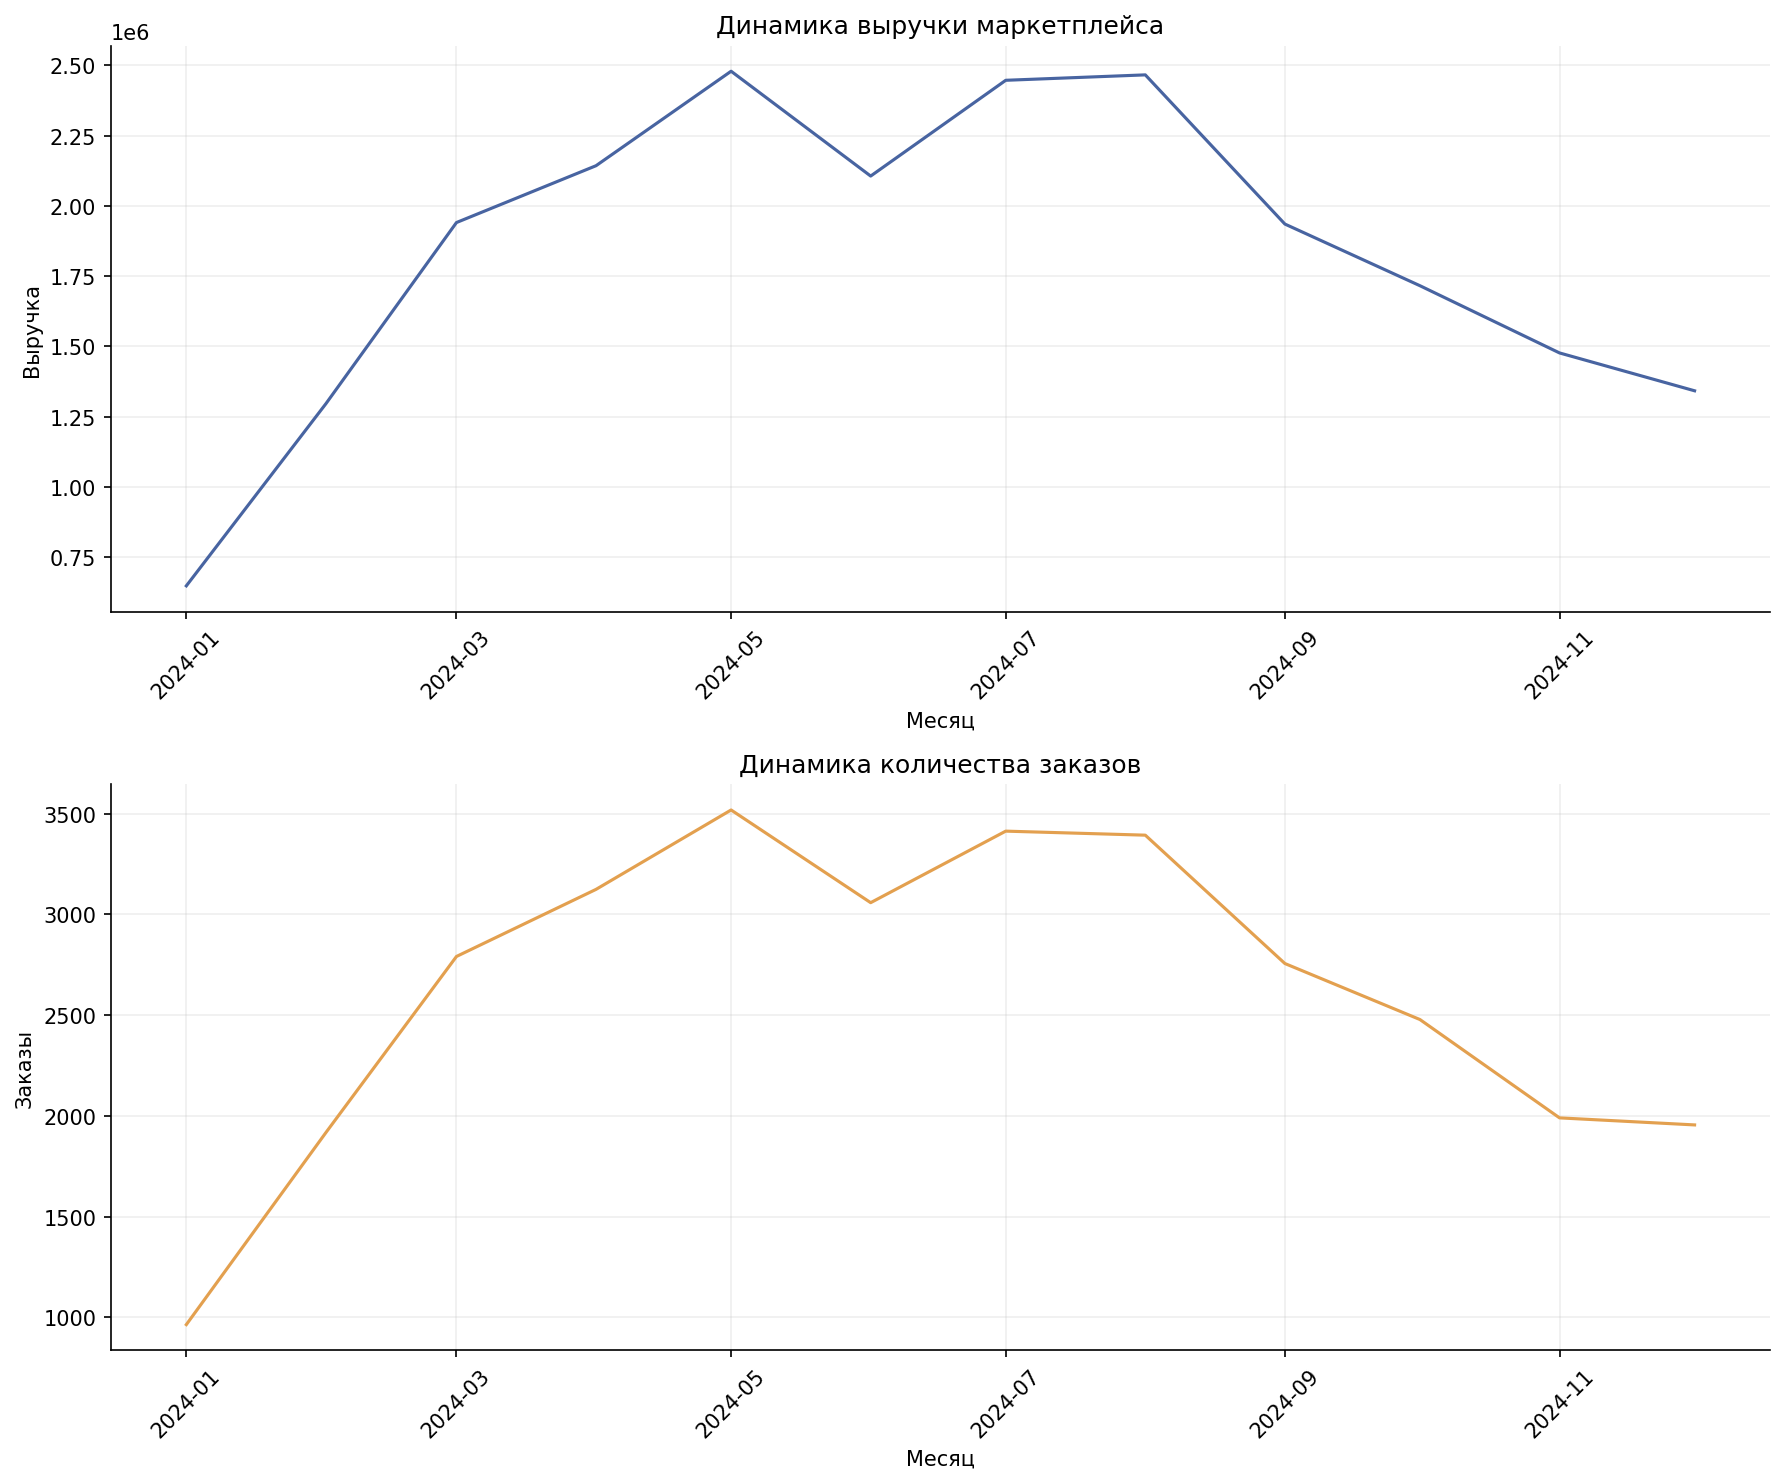

In [10]:
# Общие настройки графиков
plt.rcParams.update({
    'figure.dpi': 150,
    'savefig.dpi': 300,
    'axes.spines.top': False,
    'axes.spines.right': False
})

# Цветовая палитра
palette = ['#287D8E', '#4864A1', '#7864A7',
           '#E3A04F', '#D86B59', '#68A78B']

fig, axes = plt.subplots(2, 1, figsize=(12, 10))

metrics = [
    ('revenue', 'Динамика выручки маркетплейса', 'Выручка', palette[1]),
    ('orders_count', 'Динамика количества заказов', 'Заказы', palette[3])
]

for ax, (column, title, ylabel, color) in zip(axes, metrics):
    sns.lineplot(
        data=monthly_metrics,
        x='order_month',
        y=column,
        color=color,
        ax=ax
    )

    ax.set_title(title)
    ax.set_xlabel('Месяц')
    ax.set_ylabel(ylabel)
    ax.grid(alpha=0.2)
    ax.tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

Можно отметить, что после летних максимумов выручка и количество заказов снижаются.

**Визуализация AOV**

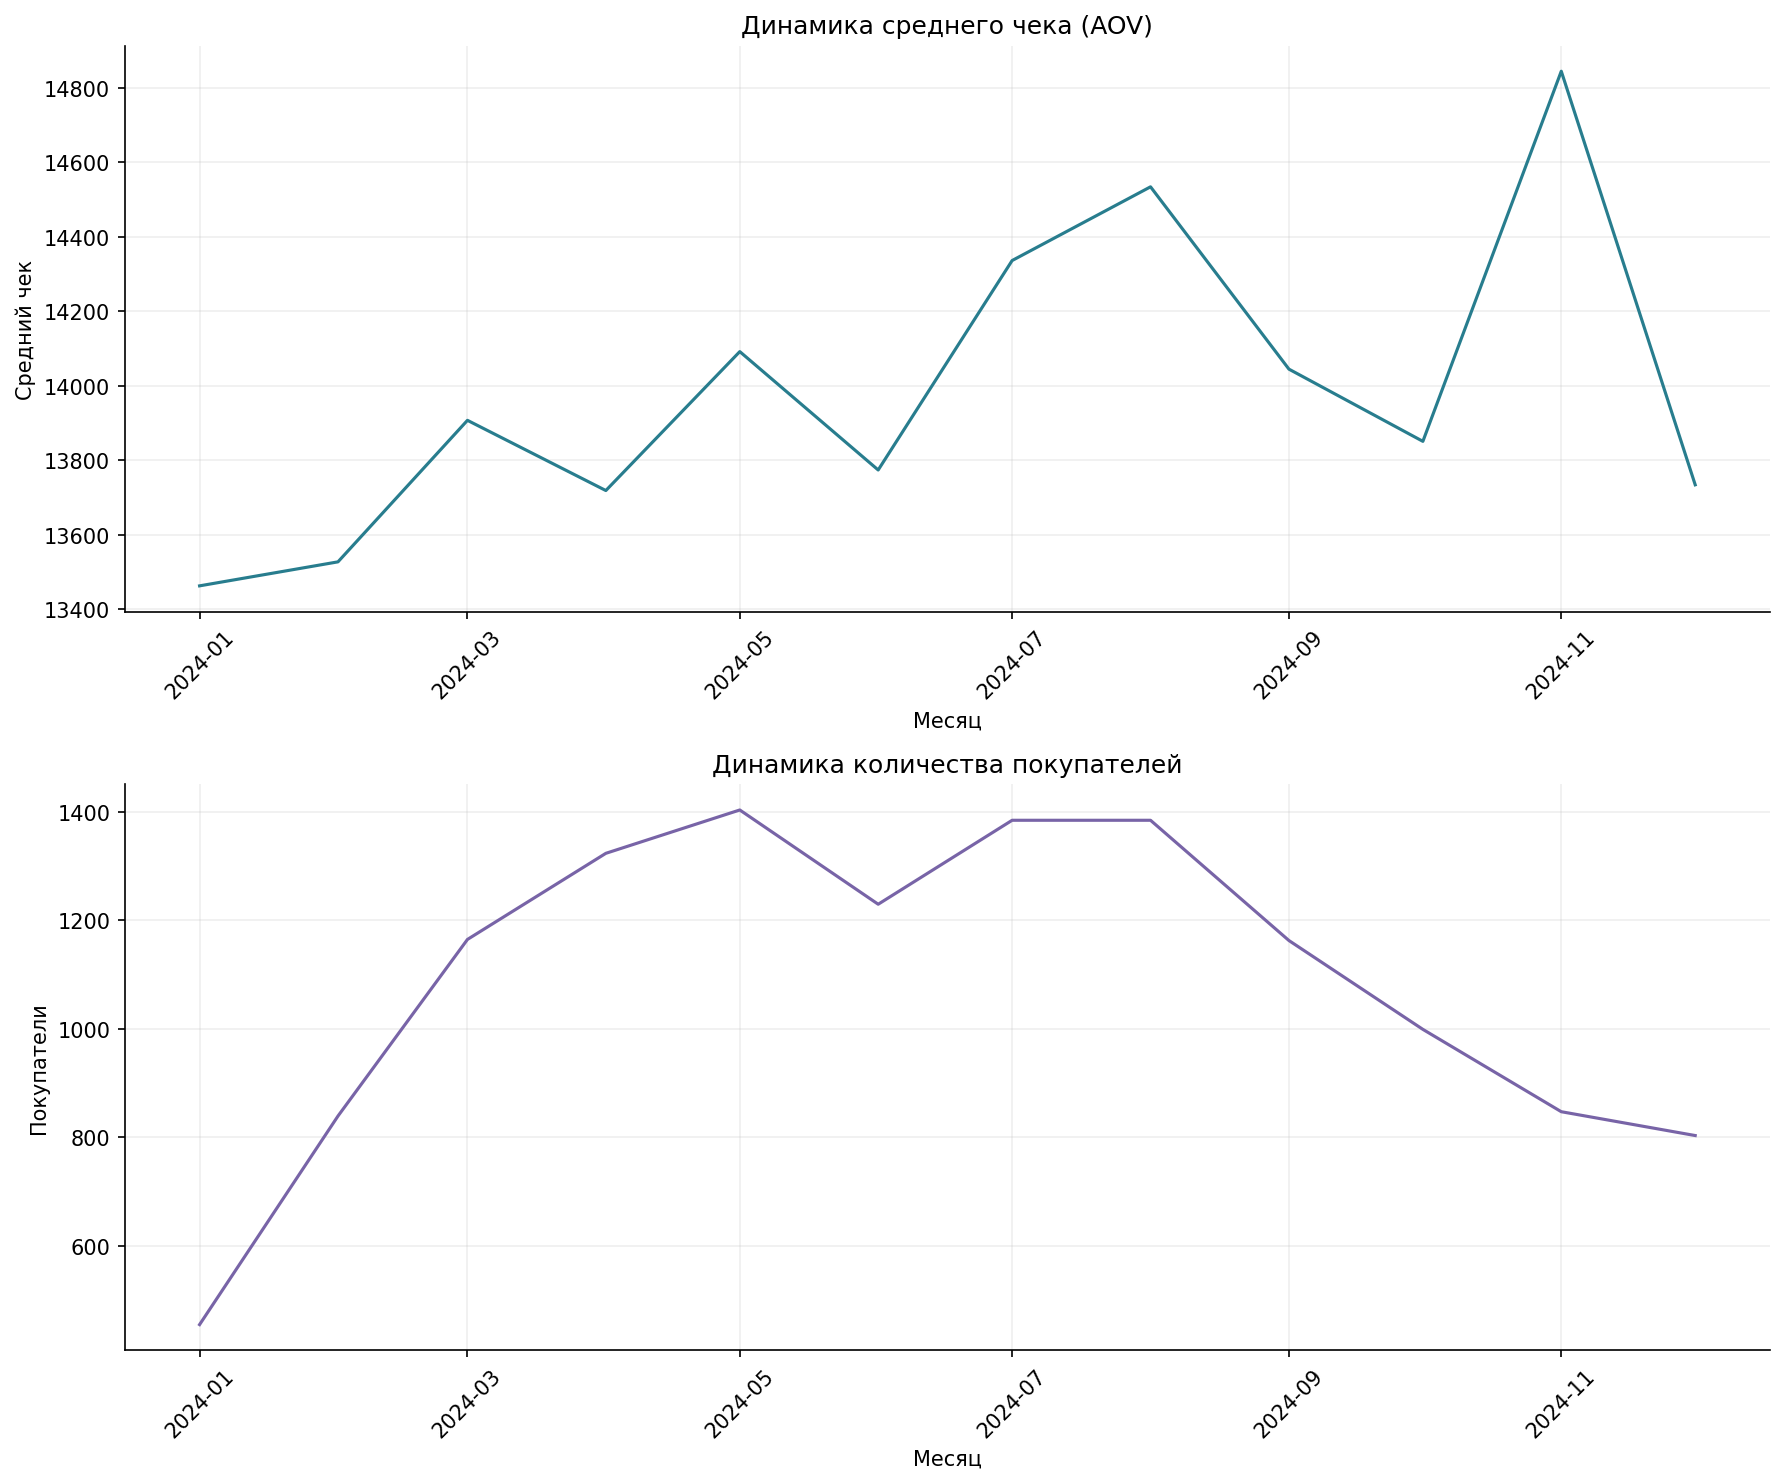

In [11]:
fig, axes = plt.subplots(2, 1, figsize=(12, 10))

metrics = [
    ('aov', 'Динамика среднего чека (AOV)', 'Средний чек', palette[0]),
    ('buyers', 'Динамика количества покупателей', 'Покупатели', palette[2])
]

for ax, (column, title, ylabel, color) in zip(axes, metrics):
    sns.lineplot(
        data=monthly_metrics,
        x='order_month',
        y=column,
        color=color,
        ax=ax
    )

    ax.set_title(title)
    ax.set_xlabel('Месяц')
    ax.set_ylabel(ylabel)
    ax.grid(alpha=0.2)
    ax.tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

Выручка маркетплейса росла в первой половине года, достигнув максимума в мае (2,48 млн), после чего наблюдались колебания и снижение до 1,34 млн в декабре (-45,8% относительно мая).

Основной причиной снижения выручки, вероятно, является сокращение покупательской аудитории: количество покупателей уменьшилось на 42,8%, а заказов - на 44,4%. При этом средний чек и частота покупок оставались относительно стабильными.

Таким образом, ключевой сигнал - снижение количества активных покупателей.

**Расчёт DAU, WAU, MAU**

In [12]:
dau = (
    events.groupby('event_date')['user_id']
    .nunique()
    .reset_index(name='dau')
)

wau = (
    events.groupby('event_week')['user_id']
    .nunique()
    .reset_index(name='wau')
)

mau = (
    events.groupby('event_month')['user_id']
    .nunique()
    .reset_index(name='mau')
)

display(dau.describe().round(2))
display(wau.describe().round(2))
display(mau)

,dau
count,366.00
mean,306.19
std,83.17
min,5.00
25%,272.00
50%,318.00
75%,359.50
max,473.00


,wau
count,53.00
mean,1172.60
std,306.14
min,133.00
25%,1142.00
50%,1258.00
75%,1338.00
max,1494.00


,event_month,mau
0,2024-01-01,1149
1,2024-02-01,2162
2,2024-03-01,2844
3,2024-04-01,3059
4,2024-05-01,3310
5,2024-06-01,3174
6,2024-07-01,3481
7,2024-08-01,3861
8,2024-09-01,3744
9,2024-10-01,3581


**Визуализация DAU, WAU, MAU**

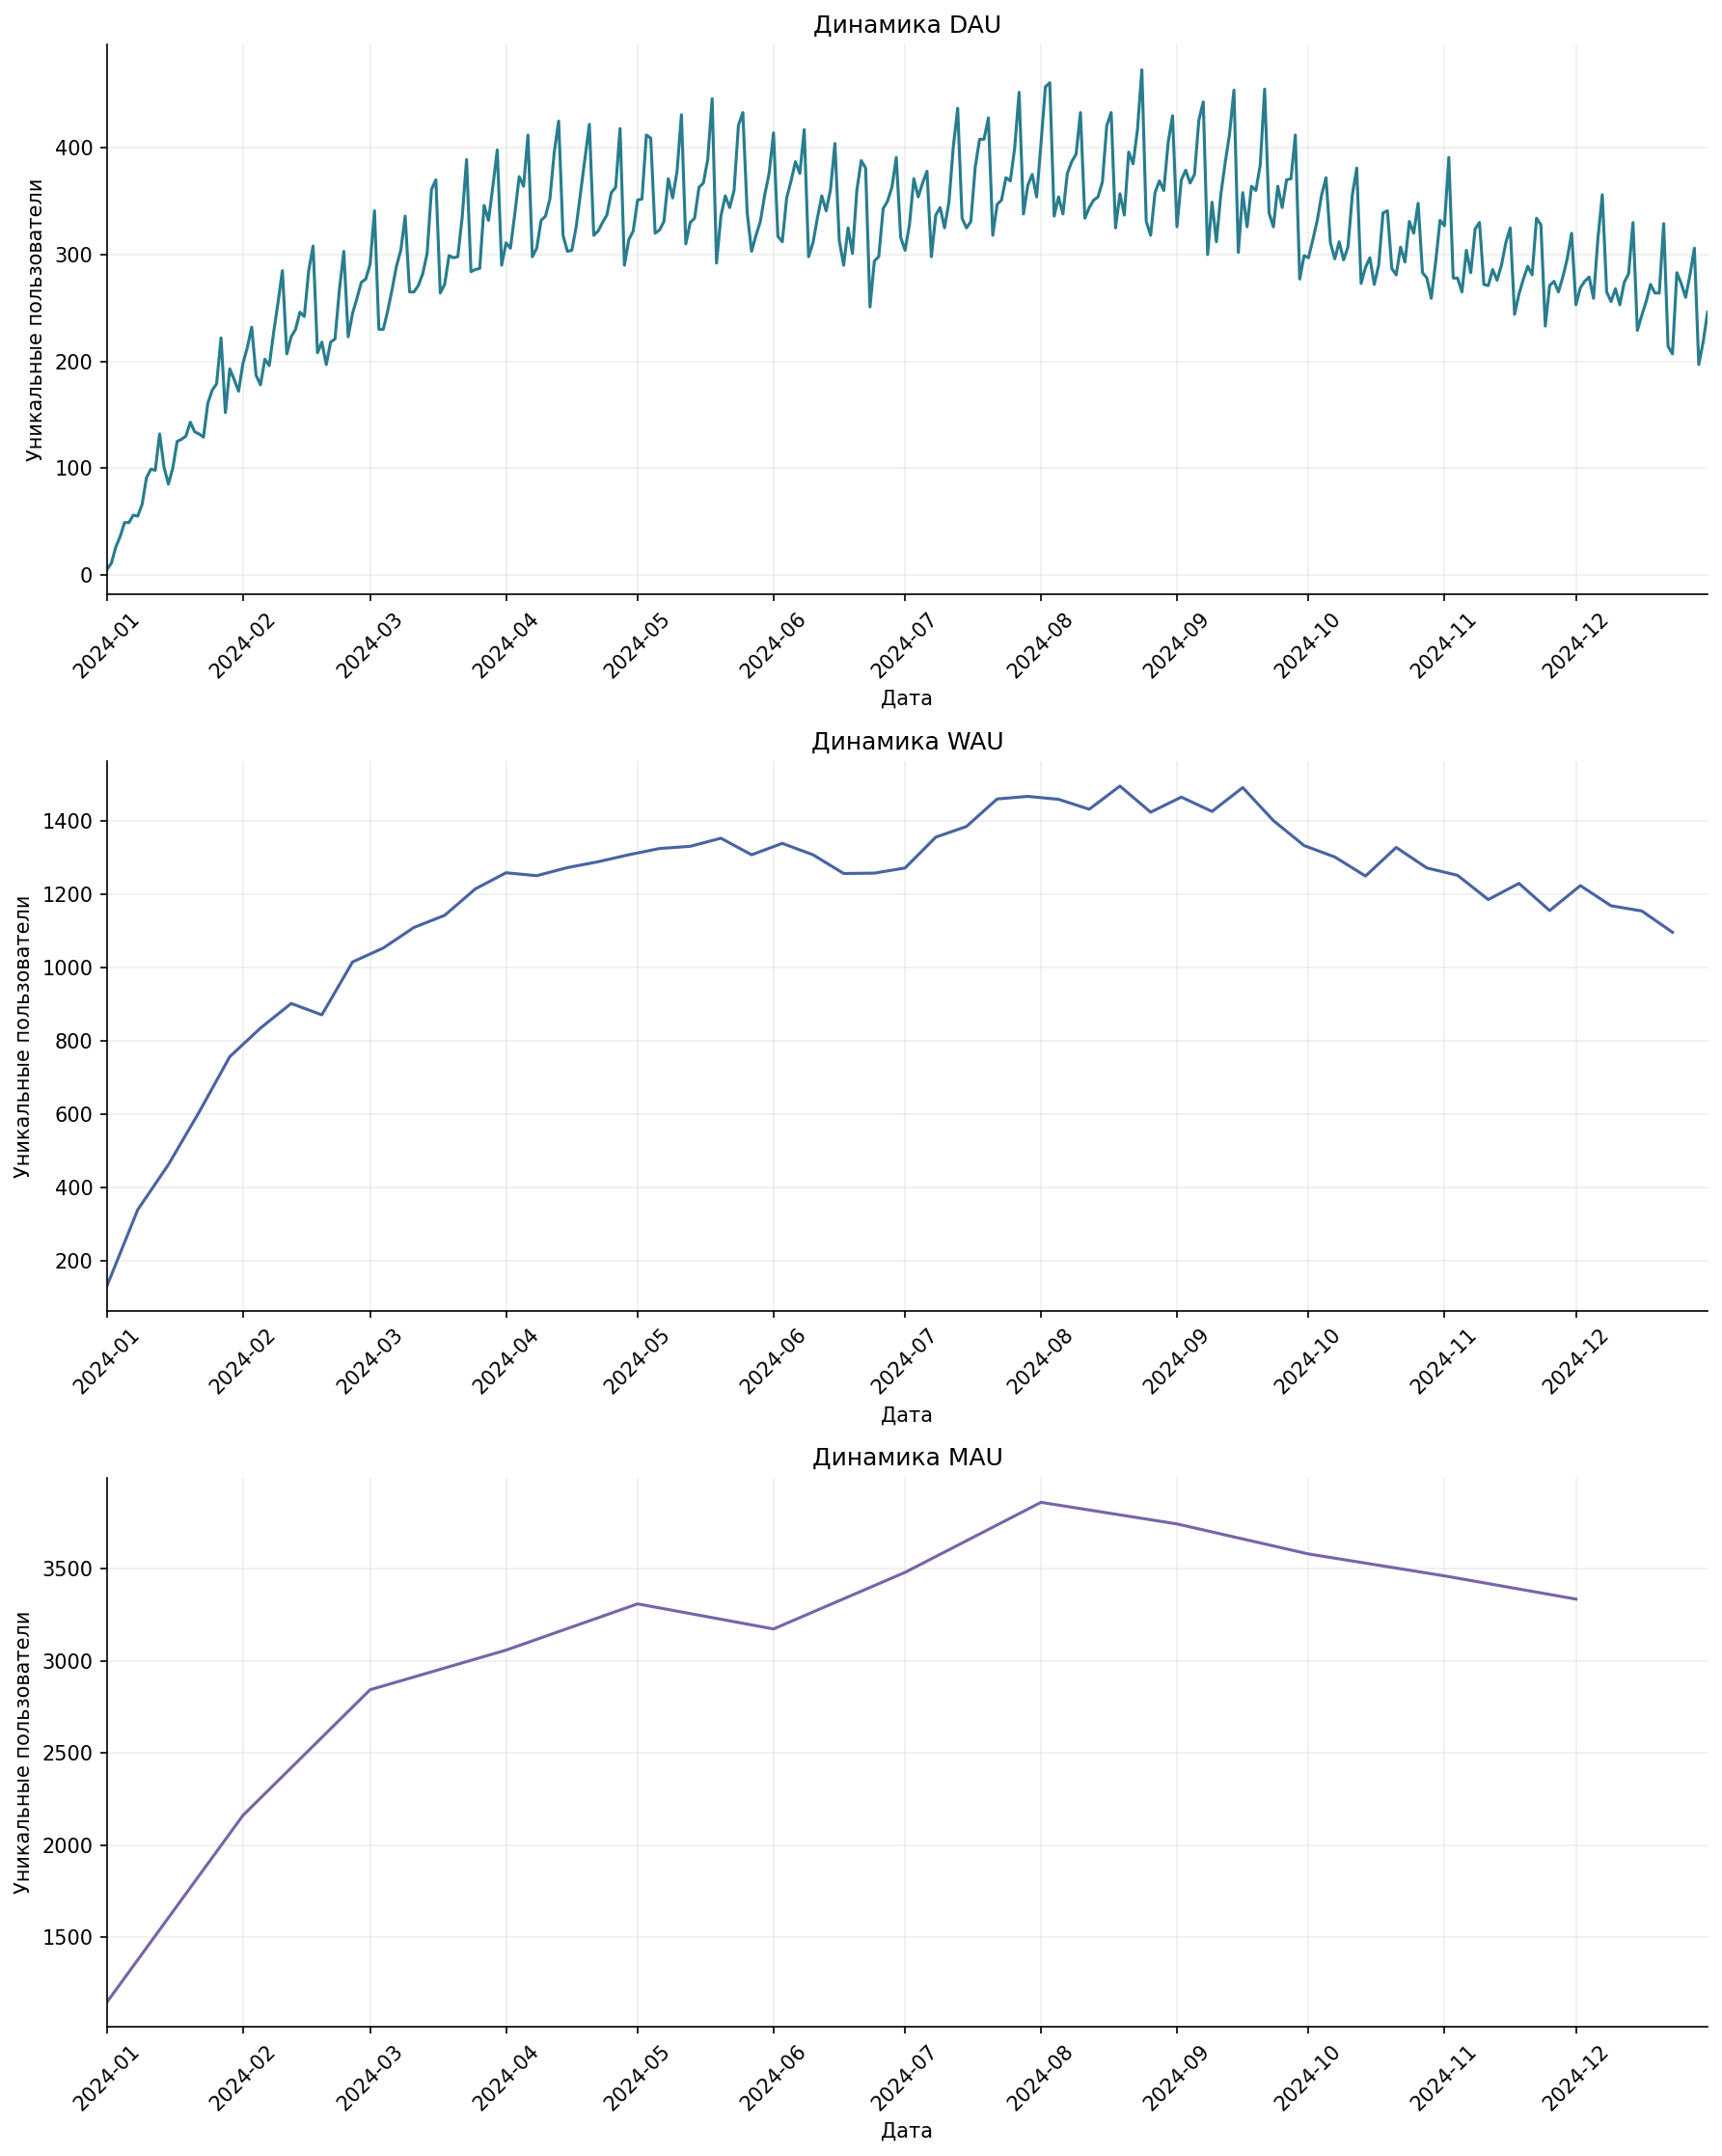

In [13]:
fig, axes = plt.subplots(3, 1, figsize=(12, 15))

wau_plot = wau[wau['event_week'] < '2024-12-30']

metrics = [
    (dau, 'event_date', 'dau', 'Динамика DAU', palette[0]),
    (wau_plot, 'event_week', 'wau', 'Динамика WAU', palette[1]),
    (mau, 'event_month', 'mau', 'Динамика MAU', palette[2])
]

for ax, (df, x, y, title, color) in zip(axes, metrics):
    sns.lineplot(
        data=df,
        x=x,
        y=y,
        color=color,
        ax=ax
    )

    ax.set_title(title)
    ax.set_xlabel('Дата')
    ax.set_ylabel('Уникальные пользователи')
    ax.set_xlim(pd.Timestamp('2024-01-01'), pd.Timestamp('2024-12-31'))
    ax.grid(alpha=0.2)
    ax.tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

Показатели DAU, WAU и MAU демонстрируют схожую динамику: рост активности в первой половине года, пик летом и постепенное снижение к декабрю. Сокращение активной аудитории совпадает со снижением количества покупателей и выручки, что может указывать на уменьшение пользовательской активности.

**Расчёт CR**

In [14]:
active_users = events[
    ['event_month', 'user_id']
].drop_duplicates()

monthly_buyers = orders[
    ['order_month', 'user_id']
].drop_duplicates()

buyers_active = monthly_buyers.merge(
    active_users,
    left_on=['order_month', 'user_id'],
    right_on=['event_month', 'user_id'],
    how='inner'
)

monthly_cr = (
    buyers_active.groupby('order_month')['user_id']
    .nunique()
    .reset_index(name='active_buyers')
    .merge(
        mau,
        left_on='order_month',
        right_on='event_month'
    )
)

monthly_cr['cr_order'] = (
    monthly_cr['active_buyers'] / monthly_cr['mau'] * 100
)

display(
    monthly_cr[
        ['order_month', 'active_buyers', 'mau', 'cr_order']
    ].round(2)
)

,order_month,active_buyers,mau,cr_order
0,2024-01-01,299,1149,26.02
1,2024-02-01,609,2162,28.17
2,2024-03-01,884,2844,31.08
3,2024-04-01,1042,3059,34.06
4,2024-05-01,1106,3310,33.41
5,2024-06-01,967,3174,30.47
6,2024-07-01,1057,3481,30.36
7,2024-08-01,1070,3861,27.71
8,2024-09-01,886,3744,23.66
9,2024-10-01,756,3581,21.11


**Визуализация CR**

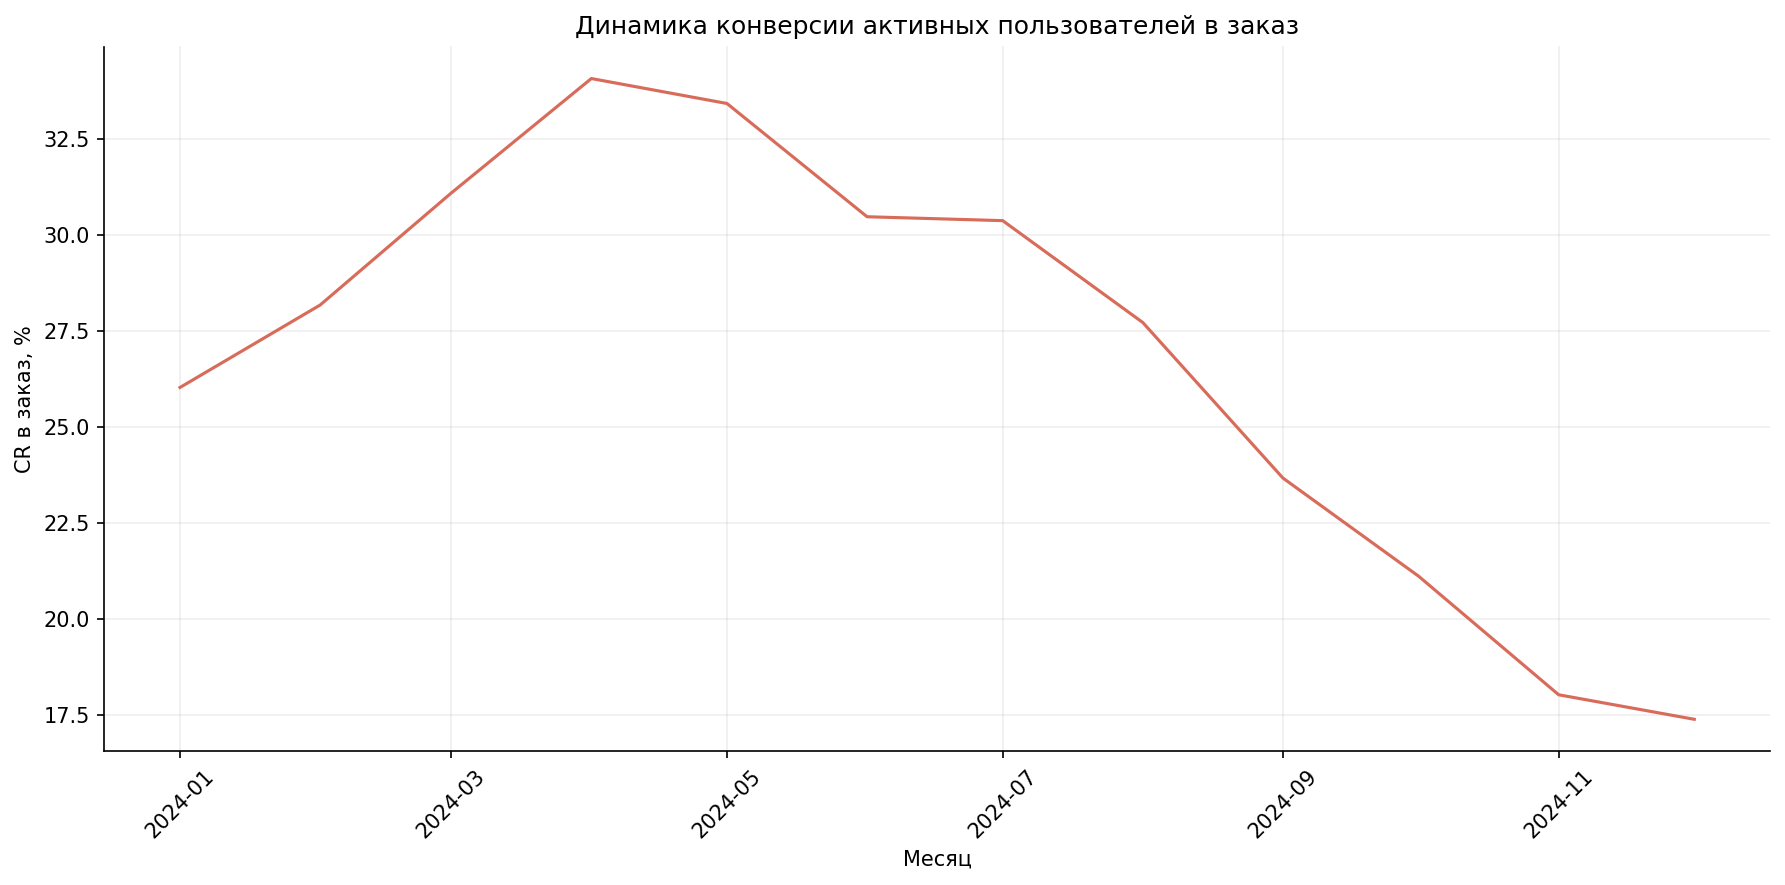

In [15]:
plt.figure(figsize=(12, 6))

sns.lineplot(
    data=monthly_cr,
    x='order_month',
    y='cr_order',
    color=palette[4]
)

plt.title('Динамика конверсии активных пользователей в заказ')
plt.xlabel('Месяц')
plt.ylabel('CR в заказ, %')
plt.grid(alpha=0.2)
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

Конверсия активных пользователей в заказ выросла с 26,02% в январе до 34,06% в апреле, после чего устойчиво снижалась, достигнув 17,39% в декабре (-16,67 п. п.). Таким образом, падение выручки связано не только с сокращением покупательской аудитории, но и со снижением конверсии.

**Расчёт Retention**

In [16]:
user_activity = (
    events[['user_id', 'event_month']]
    .drop_duplicates()
    .merge(
        users[['user_id', 'cohort_month']],
        on='user_id',
        how='inner'
    )
)

user_activity['month_number'] = (
    (user_activity['event_month'].dt.year - user_activity['cohort_month'].dt.year) * 12
    + user_activity['event_month'].dt.month
    - user_activity['cohort_month'].dt.month
)

user_activity = user_activity[user_activity['month_number'] >= 0]

cohort_sizes = (
    users.groupby('cohort_month')['user_id']
    .nunique()
    .reset_index(name='cohort_size')
)

retention_m1 = (
    user_activity[user_activity['month_number'] == 1]
    .groupby('cohort_month')['user_id']
    .nunique()
    .reset_index(name='returned_users')
    .merge(cohort_sizes, on='cohort_month', how='right')
)

retention_m1['returned_users'] = retention_m1['returned_users'].fillna(0)

retention_m1['retention_m1'] = (
    retention_m1['returned_users'] / retention_m1['cohort_size'] * 100
)

retention_m1 = retention_m1[
    retention_m1['cohort_month'] < '2024-12-01'
]

display(retention_m1.round(2))

,cohort_month,returned_users,cohort_size,retention_m1
0,2024-01-01,1102.0,2985,36.92
1,2024-02-01,1098.0,2711,40.50
2,2024-03-01,1115.0,2965,37.61
3,2024-04-01,1142.0,2905,39.31
4,2024-05-01,1132.0,3066,36.92
5,2024-06-01,964.0,2810,34.31
6,2024-07-01,1437.0,4388,32.75
7,2024-08-01,1337.0,4431,30.17
8,2024-09-01,1274.0,4466,28.53
9,2024-10-01,1169.0,4440,26.33


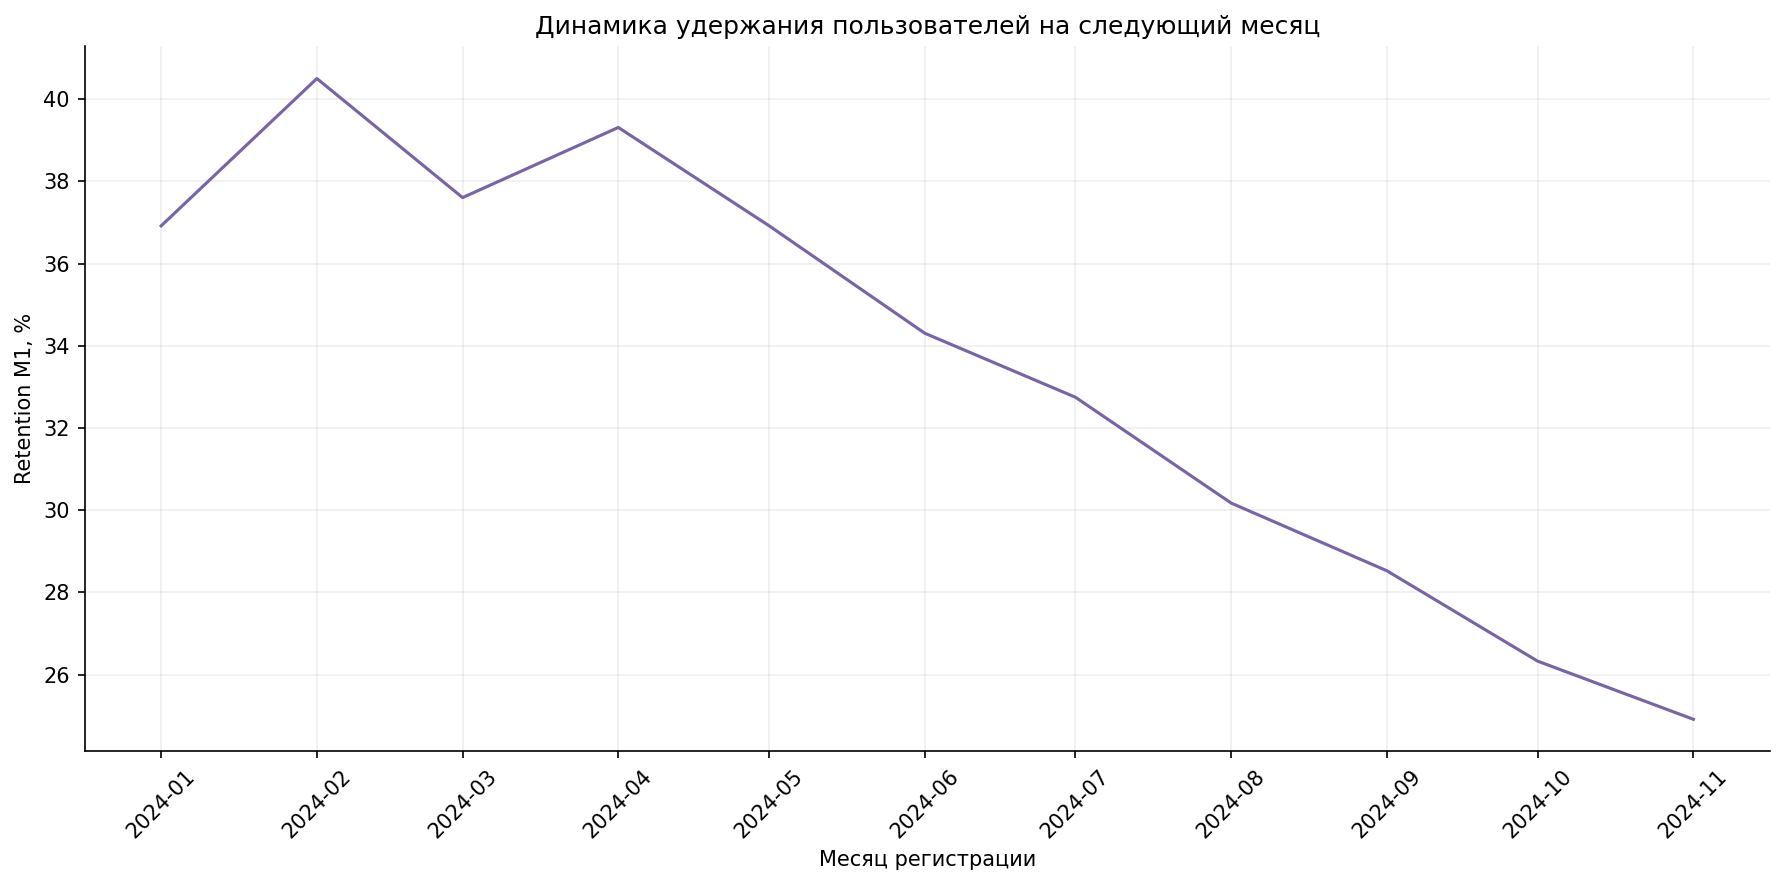

In [17]:
plt.figure(figsize=(12, 6))

sns.lineplot(
    data=retention_m1,
    x='cohort_month',
    y='retention_m1',
    color=palette[2]
)

plt.title('Динамика удержания пользователей на следующий месяц')
plt.xlabel('Месяц регистрации')
plt.ylabel('Retention M1, %')
plt.grid(alpha=0.2)
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

Месячное удержание пользователей постепенно снижается: с 40,50% в феврале до 24,91% в ноябре (-15,59 п. п.). Это свидетельствует об ухудшении способности продукта удерживать новых пользователей и может быть одной из причин сокращения активной аудитории.

**Расчёт ARPU и ARPPU**

In [18]:
monthly_metrics = monthly_metrics.merge(
    mau,
    left_on='order_month',
    right_on='event_month',
    how='left'
)

monthly_metrics['arpu'] = (
    monthly_metrics['revenue'] / monthly_metrics['mau']
)

monthly_metrics['arppu'] = (
    monthly_metrics['revenue'] / monthly_metrics['buyers']
)

display(
    monthly_metrics[
        ['order_month', 'revenue', 'mau', 'buyers', 'arpu', 'arppu']
    ].round(2)
)

,order_month,revenue,mau,buyers,arpu,arppu
0,2024-01-01,648890.03,1149,454,564.74,1429.27
1,2024-02-01,1296557.01,2162,839,599.70,1545.36
2,2024-03-01,1940749.79,2844,1165,682.40,1665.88
3,2024-04-01,2142838.40,3059,1324,700.50,1618.46
4,2024-05-01,2478758.10,3310,1404,748.87,1765.50
5,2024-06-01,2106011.86,3174,1230,663.52,1712.20
6,2024-07-01,2446535.45,3481,1385,702.83,1766.45
7,2024-08-01,2465802.40,3861,1385,638.64,1780.36
8,2024-09-01,1935366.70,3744,1163,516.92,1664.12
9,2024-10-01,1716108.26,3581,999,479.23,1717.83


**Визуализация ARPU и ARPPU**

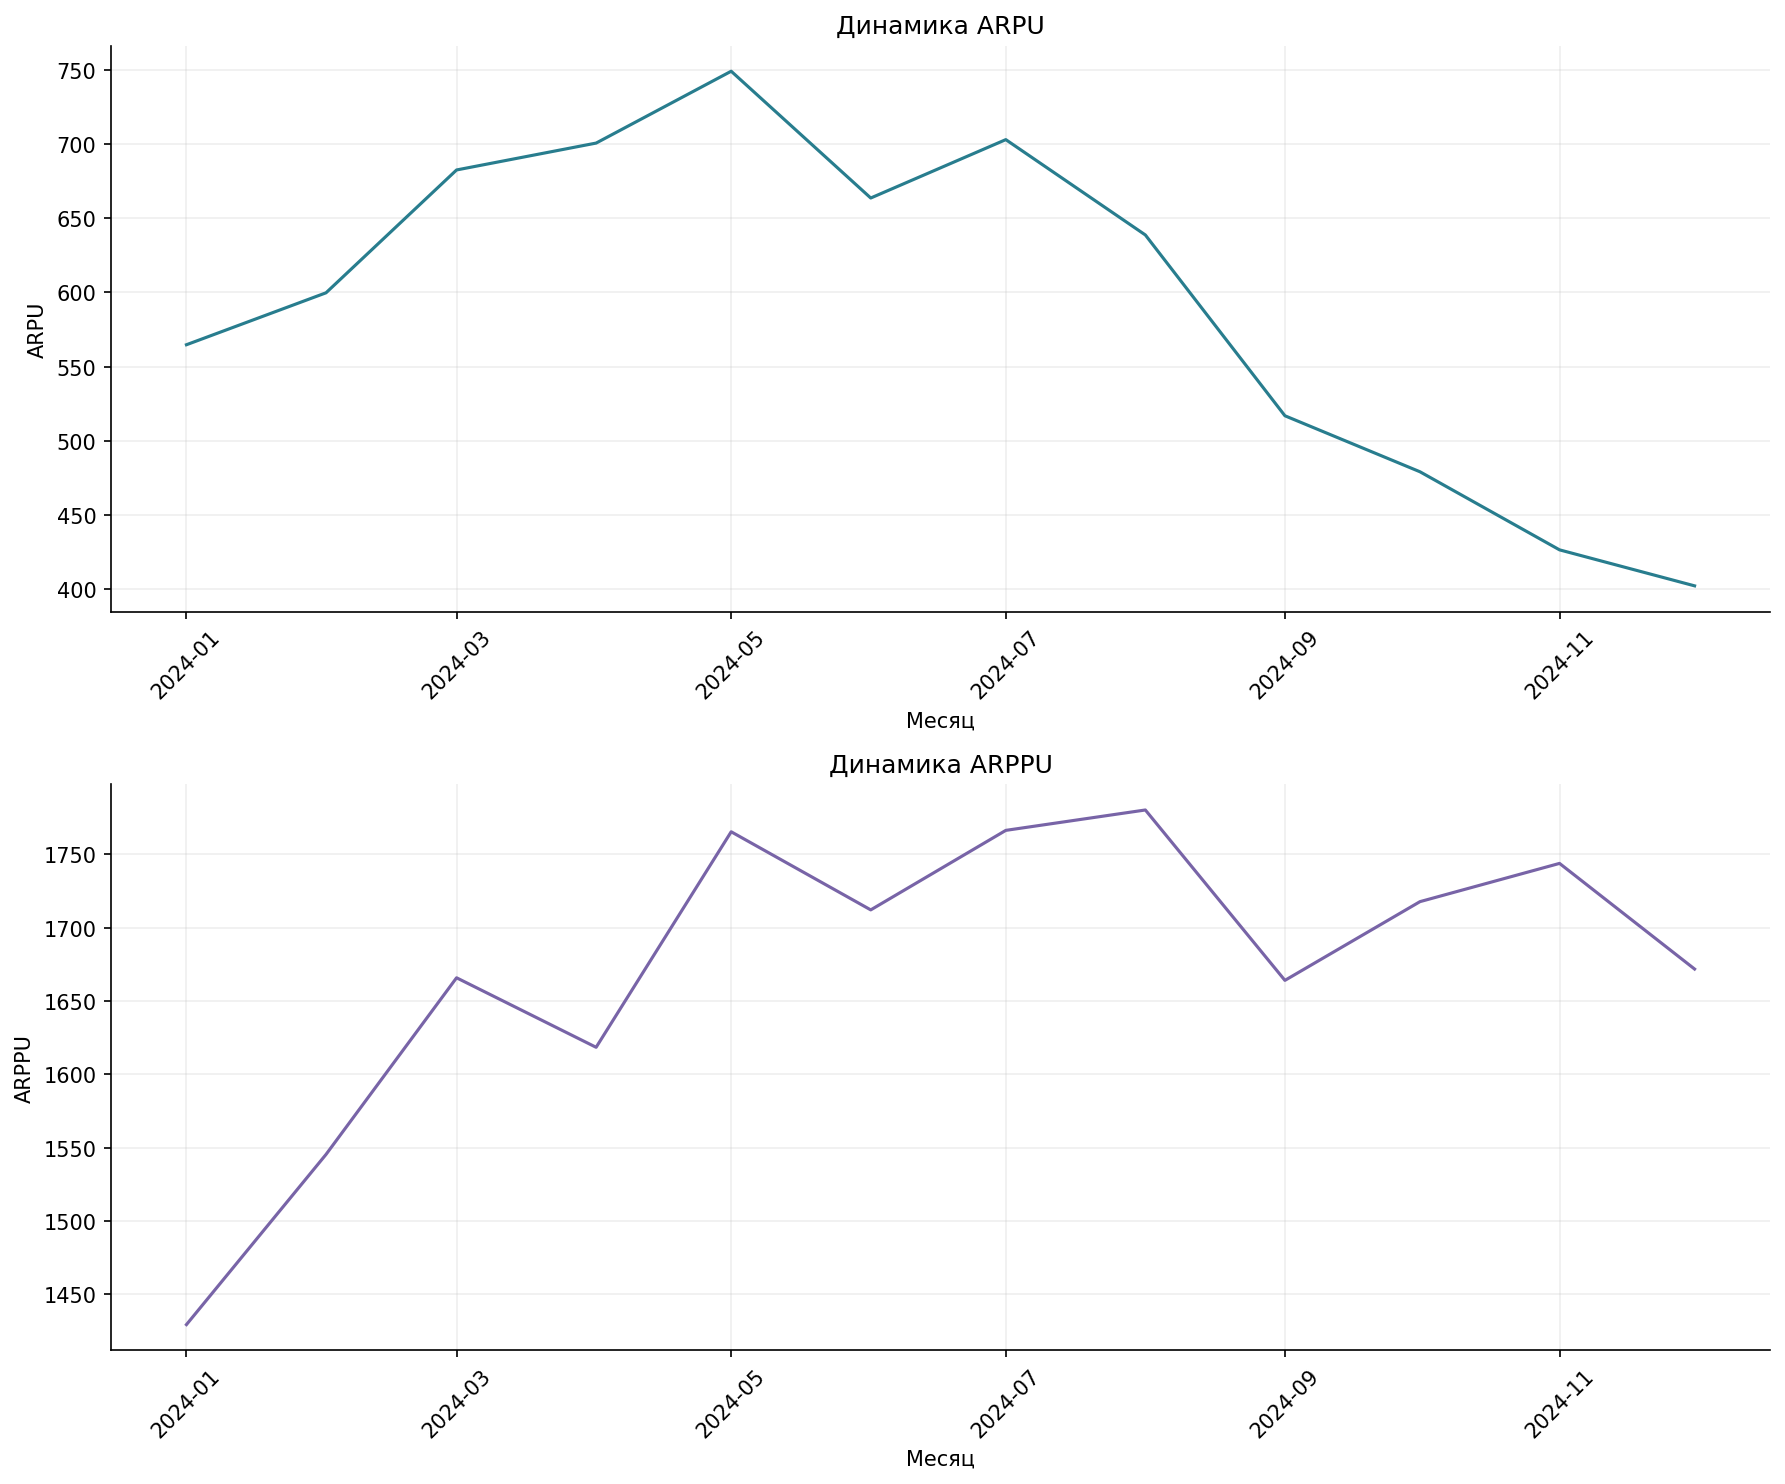

In [19]:
fig, axes = plt.subplots(2, 1, figsize=(12, 10))

metrics = [
    ('arpu', 'Динамика ARPU', 'ARPU', palette[0]),
    ('arppu', 'Динамика ARPPU', 'ARPPU', palette[2])
]

for ax, (column, title, ylabel, color) in zip(axes, metrics):
    sns.lineplot(
        data=monthly_metrics,
        x='order_month',
        y=column,
        color=color,
        ax=ax
    )

    ax.set_title(title)
    ax.set_xlabel('Месяц')
    ax.set_ylabel(ylabel)
    ax.grid(alpha=0.2)
    ax.tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

ARPU достиг максимума в мае (748,87), после чего снизился до 402,43 в декабре (-46,3%). Это свидетельствует о сокращении выручки на одного активного пользователя. При этом ARPPU оставался относительно стабильным: с марта по декабрь показатель колебался преимущественно в диапазоне 1600-1800. Таким образом, снижение ARPU связано прежде всего с уменьшением доли платящих пользователей, а не с существенным снижением дохода от одного покупателя.

**Итоги обзора ключевых метрик**

ПРоведен анализ Revenue, количество заказов, покупателей, AOV, DAU, WAU, MAU, CR, Retention, ARPU и ARPPU. Краткий вывод: после летнего периода маркетплейс демонстрирует ухудшение большинства продуктовых показателей, особенно конверсии и удержания. При этом средний чек и доход на покупателя остаются относительно стабильными.

## 3. Монетизация и юнит-экономика


**Расчёт общей выручки и затрат на мркетинг**

In [20]:
monthly_finance = (
    monthly_metrics[['order_month', 'revenue']]
    .merge(
        campaign_costs.groupby('spend_month', as_index=False)['budget'].sum(),
        left_on='order_month',
        right_on='spend_month',
        how='left'
    )
    .drop(columns='spend_month')
    .rename(columns={'budget': 'marketing_costs'})
)

print('Общая выручка:', round(monthly_finance['revenue'].sum(), 2))
print('Расходы на маркетинг:', round(monthly_finance['marketing_costs'].sum(), 2))

display(monthly_finance.round(2))

Общая выручка: 21997210.75
Расходы на маркетинг: 17762211.2


,order_month,revenue,marketing_costs
0,2024-01-01,648890.03,1177456.97
1,2024-02-01,1296557.01,1061385.93
2,2024-03-01,1940749.79,1167680.37
3,2024-04-01,2142838.40,1147739.92
4,2024-05-01,2478758.10,1225322.28
5,2024-06-01,2106011.86,1130439.77
6,2024-07-01,2446535.45,1776446.60
7,2024-08-01,2465802.40,1811677.75
8,2024-09-01,1935366.70,1820718.83
9,2024-10-01,1716108.26,1810802.57


**Визуализация общей выручки и затрат на мркетинг**

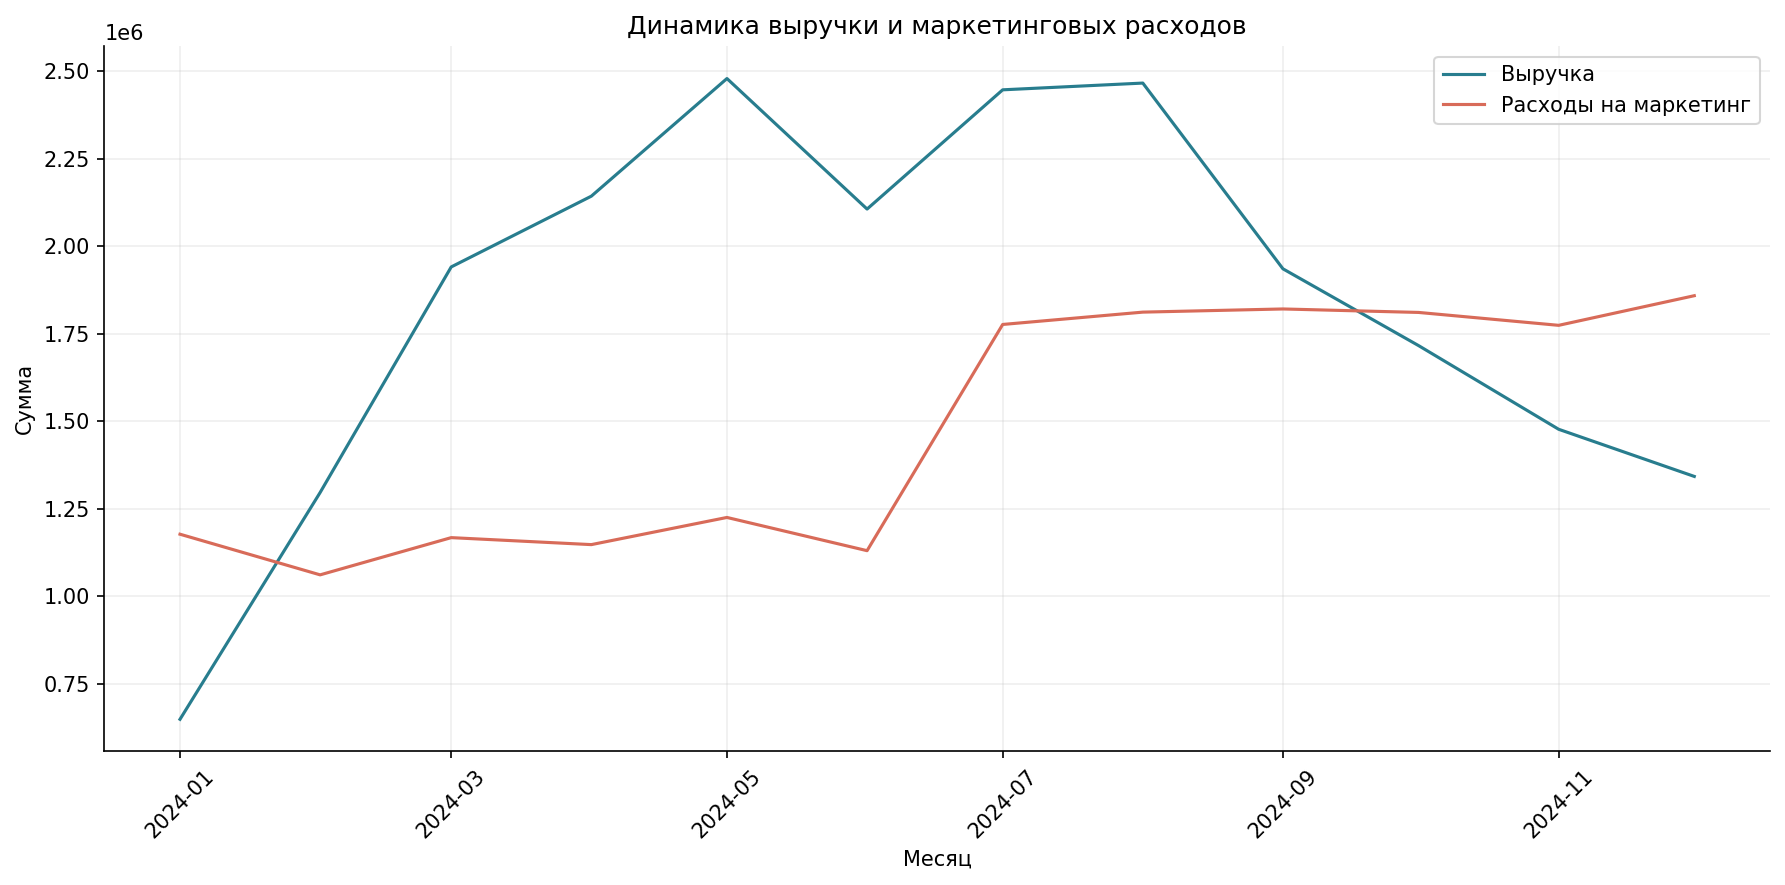

In [21]:
plt.figure(figsize=(12, 6))

sns.lineplot(
    data=monthly_finance,
    x='order_month',
    y='revenue',
    color=palette[0],
    label='Выручка'
)

sns.lineplot(
    data=monthly_finance,
    x='order_month',
    y='marketing_costs',
    color=palette[4],
    label='Расходы на маркетинг'
)

plt.title('Динамика выручки и маркетинговых расходов')
plt.xlabel('Месяц')
plt.ylabel('Сумма')
plt.xticks(rotation=45)
plt.grid(alpha=0.2)
plt.legend()

plt.tight_layout()
plt.show()

**Расчёт CAC по месяцам**

In [22]:
monthly_acquisition = (
    users.groupby('cohort_month')
    .agg(new_users=('user_id', 'nunique'))
    .reset_index()
)

monthly_acquisition = monthly_acquisition.merge(
    campaign_costs.groupby('spend_month', as_index=False)['budget'].sum(),
    left_on='cohort_month',
    right_on='spend_month',
    how='left'
)

monthly_acquisition['cac'] = (
    monthly_acquisition['budget'] / monthly_acquisition['new_users']
)

display(
    monthly_acquisition[
        ['cohort_month', 'new_users', 'budget', 'cac']
    ].round(2)
)

,cohort_month,new_users,budget,cac
0,2024-01-01,2985,1177456.97,394.46
1,2024-02-01,2711,1061385.93,391.51
2,2024-03-01,2965,1167680.37,393.82
3,2024-04-01,2905,1147739.92,395.09
4,2024-05-01,3066,1225322.28,399.65
5,2024-06-01,2810,1130439.77,402.29
6,2024-07-01,4388,1776446.60,404.84
7,2024-08-01,4431,1811677.75,408.86
8,2024-09-01,4466,1820718.83,407.68
9,2024-10-01,4440,1810802.57,407.84


**Визуализация CAC по месяцам**

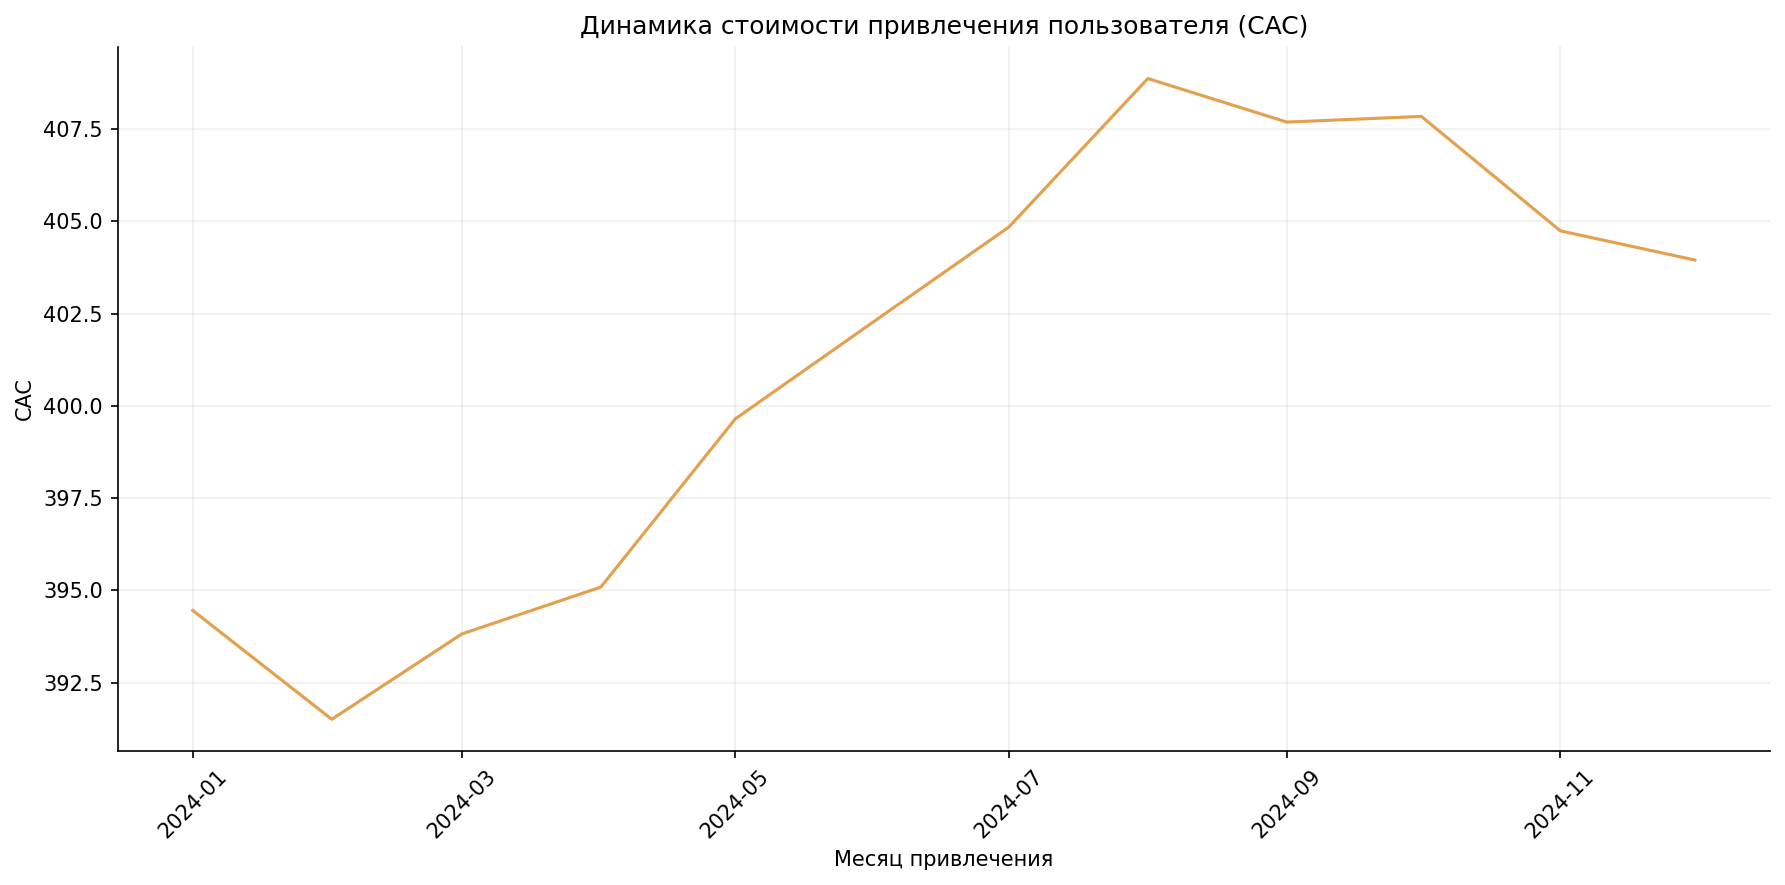

In [23]:
plt.figure(figsize=(12, 6))

sns.lineplot(
    data=monthly_acquisition,
    x='cohort_month',
    y='cac',
    color=palette[3]
)

plt.title('Динамика стоимости привлечения пользователя (CAC)')
plt.xlabel('Месяц привлечения')
plt.ylabel('CAC')
plt.xticks(rotation=45)
plt.grid(alpha=0.2)

plt.tight_layout()
plt.show()

Стоимость привлечения пользователя постепенно увеличивалась: с 394,46 в январе до максимальных 408,86 в августе (+3,7%), после чего незначительно снизилась. С июля маркетинговые расходы выросли одновременно с количеством новых пользователей, поэтому CAC оставался относительно стабильным. Однако на фоне снижения Retention и конверсии в заказ эффективность привлечения вызывает вопросы.

**Расчёт накопленной выручки**

In [24]:
cohort_orders = orders.merge(
    users[['user_id', 'cohort_month']],
    on='user_id',
    how='inner'
)

cohort_orders['month_number'] = (
    (cohort_orders['order_month'].dt.year - cohort_orders['cohort_month'].dt.year) * 12
    + cohort_orders['order_month'].dt.month
    - cohort_orders['cohort_month'].dt.month
)

cohort_orders = cohort_orders[
    cohort_orders['month_number'] >= 0
].copy()

cohort_orders['revenue'] = cohort_orders['total_price'] * 0.05

cohort_revenue = (
    cohort_orders.groupby(['cohort_month', 'month_number'])['revenue']
    .sum()
    .reset_index()
)

cohort_months = pd.date_range(
    '2024-01-01', '2024-12-01', freq='MS'
)

full_index = pd.MultiIndex.from_tuples(
    [
        (cohort, month)
        for cohort in cohort_months
        for month in range(
            12 - (cohort.year - 2024) * 12 - (cohort.month - 1)
        )
    ],
    names=['cohort_month', 'month_number']
)

cohort_revenue = (
    cohort_revenue
    .set_index(['cohort_month', 'month_number'])
    .reindex(full_index, fill_value=0)
    .reset_index()
    .sort_values(['cohort_month', 'month_number'])
)

cohort_revenue['cumulative_revenue'] = (
    cohort_revenue.groupby('cohort_month')['revenue'].cumsum()
)

display(cohort_revenue.head().round(2))

,cohort_month,month_number,revenue,cumulative_revenue
0,2024-01-01,0,623485.59,623485.59
1,2024-01-01,1,693054.85,1316540.43
2,2024-01-01,2,413166.83,1729707.26
3,2024-01-01,3,147712.28,1877419.54
4,2024-01-01,4,153252.40,2030671.94


**Расчёт ROI**

In [25]:
cohort_roi = cohort_revenue.merge(
    monthly_acquisition[['cohort_month', 'budget']],
    on='cohort_month',
    how='left'
)

cohort_roi['roi'] = (
    (cohort_roi['cumulative_revenue'] - cohort_roi['budget'])
    / cohort_roi['budget'] * 100
)

roi_pivot = cohort_roi.pivot(
    index='cohort_month',
    columns='month_number',
    values='roi'
)

roi_pivot.index = roi_pivot.index.strftime('%Y-%m')

display(roi_pivot.round(2))

month_number,0,1,2,3,4,5,6,7,8,9,10,11
cohort_month,,,,,,,,,,,,
2024-01,-47.05,11.81,46.90,59.45,72.46,74.95,76.89,78.64,78.68,78.73,78.78,78.78
2024-02,-48.11,29.07,63.62,78.40,86.45,89.31,91.71,93.40,93.40,93.40,93.40,NaN
2024-03,-44.24,29.21,71.04,91.46,101.62,106.75,111.59,111.94,112.55,112.55,NaN,NaN
2024-04,-37.18,38.79,73.43,92.57,101.04,107.90,112.01,112.50,114.04,NaN,NaN,NaN
2024-05,-39.21,28.11,60.56,76.62,79.91,81.62,83.05,83.35,NaN,NaN,NaN,NaN
2024-06,-58.13,15.11,46.86,59.10,65.35,66.85,67.31,NaN,NaN,NaN,NaN,NaN
2024-07,-57.73,-2.20,20.17,32.27,37.01,39.64,NaN,NaN,NaN,NaN,NaN,NaN
2024-08,-63.04,-26.55,-7.46,1.12,3.95,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2024-09,-72.44,-42.32,-27.51,-20.56,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


**Визуализация ROI**

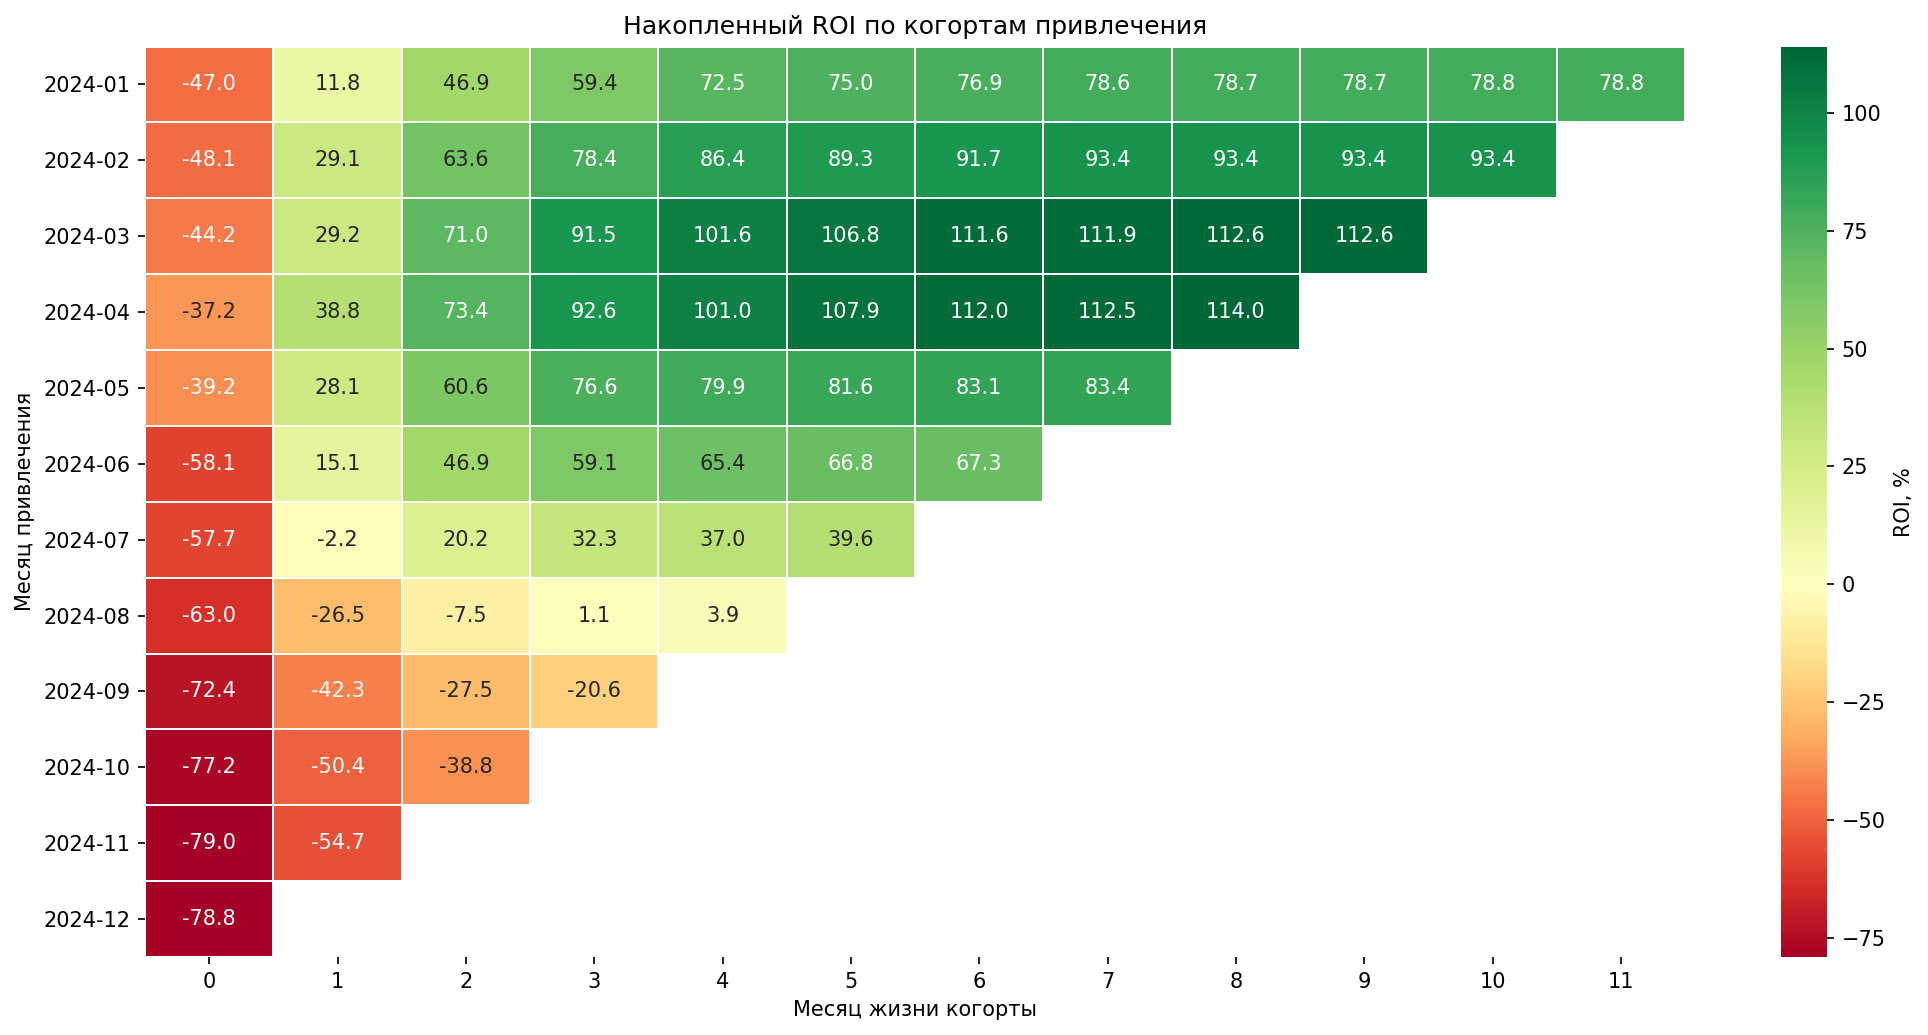

In [26]:
from matplotlib.colors import TwoSlopeNorm

plt.figure(figsize=(14, 7))

sns.heatmap(
    roi_pivot,
    annot=True,
    fmt='.1f',
    cmap='RdYlGn',
    norm=TwoSlopeNorm(
        vmin=np.nanmin(roi_pivot.values),
        vcenter=0,
        vmax=np.nanmax(roi_pivot.values)
    ),
    linewidths=0.5,
    cbar_kws={'label': 'ROI, %'}
)

plt.title('Накопленный ROI по когортам привлечения')
plt.xlabel('Месяц жизни когорты')
plt.ylabel('Месяц привлечения')

plt.tight_layout()
plt.show()

Окупаемость привлечения заметно ухудшается у когорт второй половины 2024 года.

**Расчёт Payback Period**

In [27]:
payback = (
    cohort_roi[cohort_roi['roi'] >= 0]
    .groupby('cohort_month')['month_number']
    .min()
    .reset_index(name='payback_month')
)

payback_result = (
    monthly_acquisition[['cohort_month']]
    .merge(payback, on='cohort_month', how='left')
)

payback_result['status'] = np.where(
    payback_result['payback_month'].notna(),
    'Окупилась',
    'Не окупилась за период наблюдения'
)

display(payback_result)

,cohort_month,payback_month,status
0,2024-01-01,1.0,Окупилась
1,2024-02-01,1.0,Окупилась
2,2024-03-01,1.0,Окупилась
3,2024-04-01,1.0,Окупилась
4,2024-05-01,1.0,Окупилась
5,2024-06-01,1.0,Окупилась
6,2024-07-01,2.0,Окупилась
7,2024-08-01,3.0,Окупилась
8,2024-09-01,NaN,Не окупилась за период наблюдения
9,2024-10-01,NaN,Не окупилась за период наблюдения


**Оценка монетизации и юнит-экономики**

В первой половине 2024 года маркетплейс демонстрировал рост выручки, однако во второй половине года финансовые показатели начали ухудшаться. С максимальных 2,48 млн в мае месячная выручка снизилась до 1,34 млн в декабре (-45,8%). При этом средний чек и доход на покупателя (ARPPU) оставались относительно стабильными, а ARPU снизился на 46,3%.

С июля маркетинговые расходы увеличились примерно с 1,2 до 1,8 млн в месяц. Несмотря на рост количества привлечённых пользователей, стоимость привлечения (CAC) оставалась относительно стабильной - около 390–410. Однако увеличение бюджета не сопровождалось устойчивым ростом выручки.

Ключевая проблема - ухудшение окупаемости привлечения. Когорты января–июня покрывали маркетинговые затраты уже в первый месяц после регистрации, июльская - во второй, августовская - в третий. Когорты сентября–декабря не достигли окупаемости за доступный период наблюдения.

## Итоги анализа продуктовых метрик и юнит-экономики


### Аналитическая записка: оценка состояния маркетплейса за 2024 год

<details>
<summary>(нажмите, чтобы развернуть) </summary>
    
#### 1. Основные результаты

Анализ продуктовых и финансовых показателей выявил ухудшение состояния маркетплейса во второй половине 2024 года. Несмотря на увеличение маркетинговых расходов и количества привлечённых пользователей, выручка, конверсия и удержание начали снижаться.

**Ключевые наблюдения:**
- Выручка сократилась на **45,8%** относительно майского максимума.
- Конверсия активных пользователей в заказ снизилась с **34,06% до 17,39%**.
- Retention снизился с **40,50% до 24,91%**.
- CAC с июля оставался относительно стабильным, однако срок окупаемости новых когорт увеличился.

#### 2. Динамика продаж и выручки

Выручка маркетплейса росла в первой половине года, достигнув **2,48 млн в мае**. После летнего периода началось устойчивое снижение, и к декабрю выручка составила **1,34 млн**.

Количество заказов сократилось с 3518 в мае до 1955 в декабре (-44,4%), а число уникальных покупателей - с 1404 до 803 (-42,8%).

![Динамика выручки и количества заказов](https://lh3.google.com/u/0/d/1lBISJFfoGi6BygbC5pWiGaVQYSLFWj4t=w2560-h1271-iv1?auditContext=forDisplay)

При этом средний чек (AOV) оставался относительно стабильным - преимущественно в диапазоне **13,5–14,8 тыс.** Следовательно, снижение продаж связано прежде всего с сокращением числа покупателей и заказов, а не с уменьшением их стоимости.

![Динамика AOV и количества покупателей](https://lh3.google.com/u/0/d/1x3HQpLU_x9TwnhTGjGrFokX39PrnTKmy=w2560-h1271-iv1?auditContext=prefetch)

#### 3. Пользовательская активность и удержание

Показатели DAU, WAU и MAU демонстрируют схожую динамику: рост в первой половине года, максимальные значения летом и последующее снижение.

![Динамика DAU, WAU и MAU](https://i.ibb.co/PsxWHQcC/download-2.png)

Дополнительный негативный сигнал - снижение конверсии активных пользователей в заказ. Показатель достиг максимума в апреле (**34,06%**), после чего постепенно уменьшился до **17,39% в декабре**, потеряв 16,67 процентного пункта.

![Динамика конверсии в заказ](https://i.ibb.co/zHn6SLKG/download-3.png)

Удержание пользователей также ухудшилось. Retention сократился с 40,50% для февральской когорты до 24,91% для ноябрьской (-15,59 п. п.).

![Динамика Retention](https://i.ibb.co/hJ70qJVY/download-4.png)

Таким образом, продукт сталкивается одновременно с сокращением активной аудитории, снижением конверсии и ухудшением удержания новых пользователей.

#### 4. Монетизация

ARPU достиг максимума в мае (**748,87**), после чего снизился до **402,43** в декабре (-46,3%).

При этом ARPPU оставался относительно стабильным - преимущественно в диапазоне 1600-1800.

![Динамика ARPU и ARPPU](https://i.ibb.co/5hfVhh2q/download-5.png)

Это указывает на то, что снижение дохода на активного пользователя связано преимущественно с сокращением доли покупателей, а не с существенным уменьшением выручки на одного покупателя.

#### 5. Маркетинговые расходы и стоимость привлечения

С июля маркетинговые расходы выросли примерно с **1,1–1,2 млн до 1,8 млн в месяц**, однако увеличение бюджета не сопровождалось устойчивым ростом выручки.

С октября по декабрь месячные маркетинговые расходы превышали месячную выручку маркетплейса. При этом сравнение показателей за один календарный месяц не отражает полную окупаемость привлечения.

![Сравнение выручки и маркетинговых расходов](https://i.ibb.co/wF7y4RJc/download-6.png)

Стоимость привлечения пользователя (CAC) оставалась относительно стабильной: от 394,46 в январе до максимума 408,86 в августе (+3,7%).

![Динамика CAC](https://i.ibb.co/TM85126S/download-7.png)

Таким образом, главная проблема заключается не столько в удорожании привлечения, сколько в ухудшении последующей монетизации привлечённых пользователей.

#### 6. ROI и окупаемость маркетинговых вложений

Когортный анализ показал увеличение срока окупаемости привлечения:

- **Январь–июнь:** окупаемость достигалась в первый месяц после регистрации.
- **Июль:** во второй месяц.
- **Август:** в третий месяц.
- **Сентябрь–декабрь:** окупаемость не достигнута за доступный период наблюдения.

![Накопленный ROI по когортам](https://i.ibb.co/hFHM45Lm/download-8.png)

ROI рассчитан по накопленной комиссионной выручке за вычетом маркетинговых расходов. Другие затраты бизнеса в расчёте не учитывались.

Для поздних когорт период наблюдения короче, поэтому отсутствие окупаемости на конец 2024 года не означает, что она не будет достигнута в дальнейшем.

#### 7. Итоговые выводы и рекомендации

**Основная проблема маркетплейса - снижение эффективности привлечённой аудитории.** Во второй половине года маркетинговые бюджеты увеличились, однако конверсия, удержание и доход на активного пользователя ухудшились.

При этом стабильные AOV и ARPPU показывают, что пользователи, продолжающие совершать покупки, сохраняют относительно прежний уровень расходов.

**Рекомендуемые направления дальнейшего анализа:**

1. **Каналы привлечения:** определить, какие источники обеспечивают низкие Retention и ROI после увеличения бюджета.
2. **Пользовательская воронка:** выявить этапы с наибольшими потерями пользователей перед оформлением заказа.
3. **Сегментация:** проверить, в каких регионах, категориях товаров и группах пользователей наблюдается наиболее существенное снижение конверсии.
4. **Маркетинговая эффективность:** пересмотреть распределение бюджета с учётом окупаемости и удержания, а не только стоимости привлечения.

**Вывод:** приоритетом для бизнеса должно стать повышение конверсии и удержания пользователей, а также поиск наиболее эффективных сегментов привлечения.
</details>

## 4. Поиск инсайтов, точек роста и сегментация


**Расчёт метрик по каналам**

In [28]:
channel_users = (
    users.groupby('acq_channel')
    .agg(new_users=('user_id', 'nunique'))
    .reset_index()
)

channel_costs = (
    campaign_costs.groupby('acq_channel')
    .agg(budget=('budget', 'sum'))
    .reset_index()
)

channel_metrics = channel_users.merge(
    channel_costs,
    on='acq_channel',
    how='left'
)

channel_metrics['cac'] = (
    channel_metrics['budget'] / channel_metrics['new_users']
)

channel_metrics['users_share'] = (
    channel_metrics['new_users'] /
    channel_metrics['new_users'].sum() * 100
)

channel_metrics = channel_metrics.sort_values(
    'new_users',
    ascending=False
)

display(channel_metrics.round(2))

monthly_channel_users = (
    users.groupby(['cohort_month', 'acq_channel'])
    .agg(new_users=('user_id', 'nunique'))
    .reset_index()
)

monthly_channel_metrics = monthly_channel_users.merge(
    campaign_costs,
    left_on=['cohort_month', 'acq_channel'],
    right_on=['spend_month', 'acq_channel'],
    how='left'
)

monthly_channel_metrics['cac'] = (
    monthly_channel_metrics['budget'] /
    monthly_channel_metrics['new_users']
)

display(monthly_channel_metrics.round(2))

,acq_channel,new_users,budget,cac,users_share
5,TikTok,19228,8402667.54,437.00,43.55
2,Google Ads,9319,4663489.65,500.43,21.11
0,Affiliate,6069,1898017.71,312.74,13.75
4,Social Media,4179,1563229.25,374.07,9.47
3,SEO,3312,621253.88,187.58,7.50
1,Email Marketing,2044,511724.88,250.35,4.63


,cohort_month,acq_channel,new_users,spend_month,budget,cac
0,2024-01-01,Affiliate,575,2024-01-01,179343.39,311.90
1,2024-01-01,Email Marketing,175,2024-01-01,44263.61,252.93
2,2024-01-01,Google Ads,1119,2024-01-01,559875.81,500.34
3,2024-01-01,SEO,316,2024-01-01,59683.72,188.87
4,2024-01-01,Social Media,406,2024-01-01,152268.49,375.05
...,...,...,...,...,...,...
65,2024-12-01,Affiliate,423,2024-12-01,131535.35,310.96
66,2024-12-01,Email Marketing,142,2024-12-01,35736.71,251.67
67,2024-12-01,SEO,252,2024-12-01,46902.36,186.12
68,2024-12-01,Social Media,278,2024-12-01,103310.43,371.62


**Сравненрие количества привлечённых пользователей и CAC по каналам**

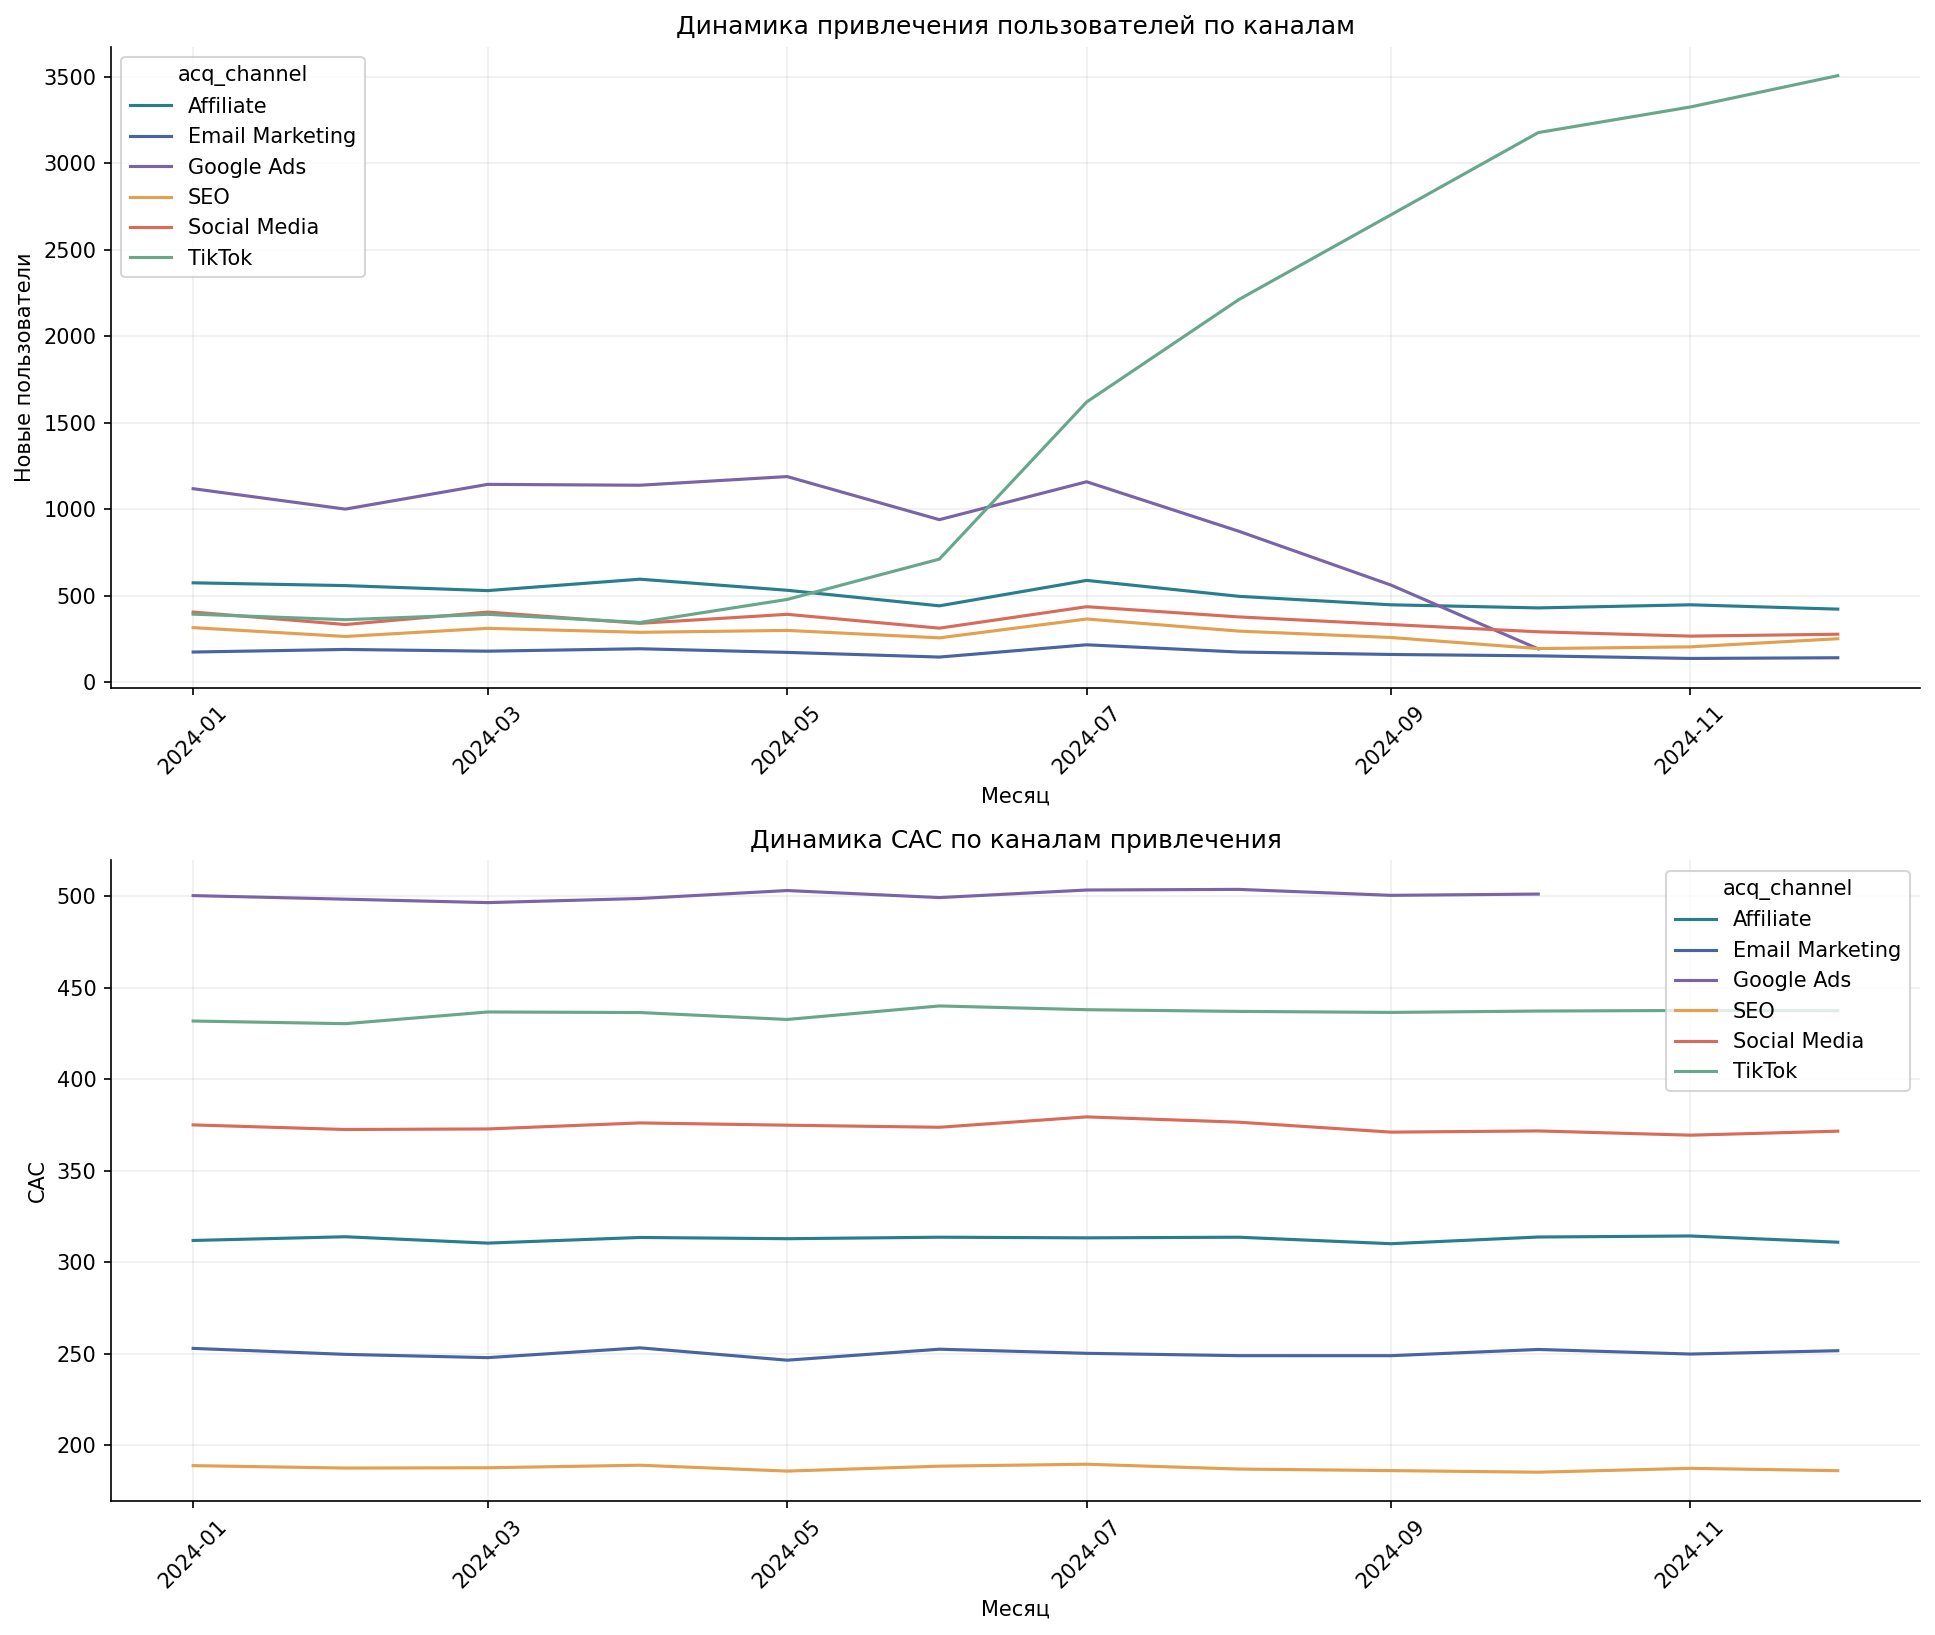

In [29]:
fig, axes = plt.subplots(2, 1, figsize=(13, 11))

sns.lineplot(
    data=monthly_channel_metrics,
    x='cohort_month',
    y='new_users',
    hue='acq_channel',
    palette=palette,
    ax=axes[0]
)

axes[0].set_title('Динамика привлечения пользователей по каналам')
axes[0].set_xlabel('Месяц')
axes[0].set_ylabel('Новые пользователи')
axes[0].tick_params(axis='x', rotation=45)
axes[0].grid(alpha=0.2)

sns.lineplot(
    data=monthly_channel_metrics,
    x='cohort_month',
    y='cac',
    hue='acq_channel',
    palette=palette,
    ax=axes[1]
)

axes[1].set_title('Динамика CAC по каналам привлечения')
axes[1].set_xlabel('Месяц')
axes[1].set_ylabel('CAC')
axes[1].tick_params(axis='x', rotation=45)
axes[1].grid(alpha=0.2)

plt.tight_layout()
plt.show()

Во второй половине 2024 года структура привлечения существенно изменилась: объём пользователей из TikTok резко увеличился, тогда как Google Ads сократил привлечение до нуля. Остальные каналы оставались относительно стабильными.

При этом CAC внутри каналов практически не менялся. Следовательно, изменение общей эффективности маркетинга может быть связано преимущественно с перераспределением привлечения между каналами, а не с ростом стоимости привлечения внутри них.

**Расчет конверсии и удержания по каналам**

In [30]:
channel_active = (
    events[['user_id', 'event_month']]
    .drop_duplicates()
    .merge(
        users[['user_id', 'acq_channel']],
        on='user_id',
        how='inner'
    )
)

channel_buyers = (
    orders[['user_id', 'order_month']]
    .drop_duplicates()
    .merge(
        channel_active,
        left_on=['user_id', 'order_month'],
        right_on=['user_id', 'event_month'],
        how='inner'
    )
)

monthly_active = (
    channel_active.groupby(['event_month', 'acq_channel'])['user_id']
    .nunique()
    .reset_index(name='active_users')
)

monthly_buyers = (
    channel_buyers.groupby(['event_month', 'acq_channel'])['user_id']
    .nunique()
    .reset_index(name='buyers')
)

monthly_channel_cr = monthly_active.merge(
    monthly_buyers,
    on=['event_month', 'acq_channel'],
    how='left'
)

monthly_channel_cr['buyers'] = monthly_channel_cr['buyers'].fillna(0)

monthly_channel_cr['cr_purchase'] = (
    monthly_channel_cr['buyers'] /
    monthly_channel_cr['active_users'] * 100
)

cohort_channel_sizes = (
    users[users['cohort_month'] < '2024-12-01']
    .groupby(['cohort_month', 'acq_channel'])['user_id']
    .nunique()
    .reset_index(name='cohort_size')
)

retained_users = (
    user_activity[user_activity['month_number'] == 1]
    .merge(
        users[['user_id', 'acq_channel']],
        on='user_id',
        how='inner'
    )
    .groupby(['cohort_month', 'acq_channel'])['user_id']
    .nunique()
    .reset_index(name='returned_users')
)

monthly_channel_retention = cohort_channel_sizes.merge(
    retained_users,
    on=['cohort_month', 'acq_channel'],
    how='left'
)

monthly_channel_retention['returned_users'] = (
    monthly_channel_retention['returned_users'].fillna(0)
)

monthly_channel_retention['retention_m1'] = (
    monthly_channel_retention['returned_users'] /
    monthly_channel_retention['cohort_size'] * 100
)

display(monthly_channel_cr.round(2).head())
display(monthly_channel_retention.round(2).head())

,event_month,acq_channel,active_users,buyers,cr_purchase
0,2024-01-01,Affiliate,240,77,32.08
1,2024-01-01,Email Marketing,79,5,6.33
2,2024-01-01,Google Ads,426,129,30.28
3,2024-01-01,SEO,159,36,22.64
4,2024-01-01,Social Media,133,38,28.57


,cohort_month,acq_channel,cohort_size,returned_users,retention_m1
0,2024-01-01,Affiliate,575,231,40.17
1,2024-01-01,Email Marketing,175,76,43.43
2,2024-01-01,Google Ads,1119,440,39.32
3,2024-01-01,SEO,316,145,45.89
4,2024-01-01,Social Media,406,130,32.02


**Визуализация качества каналов**

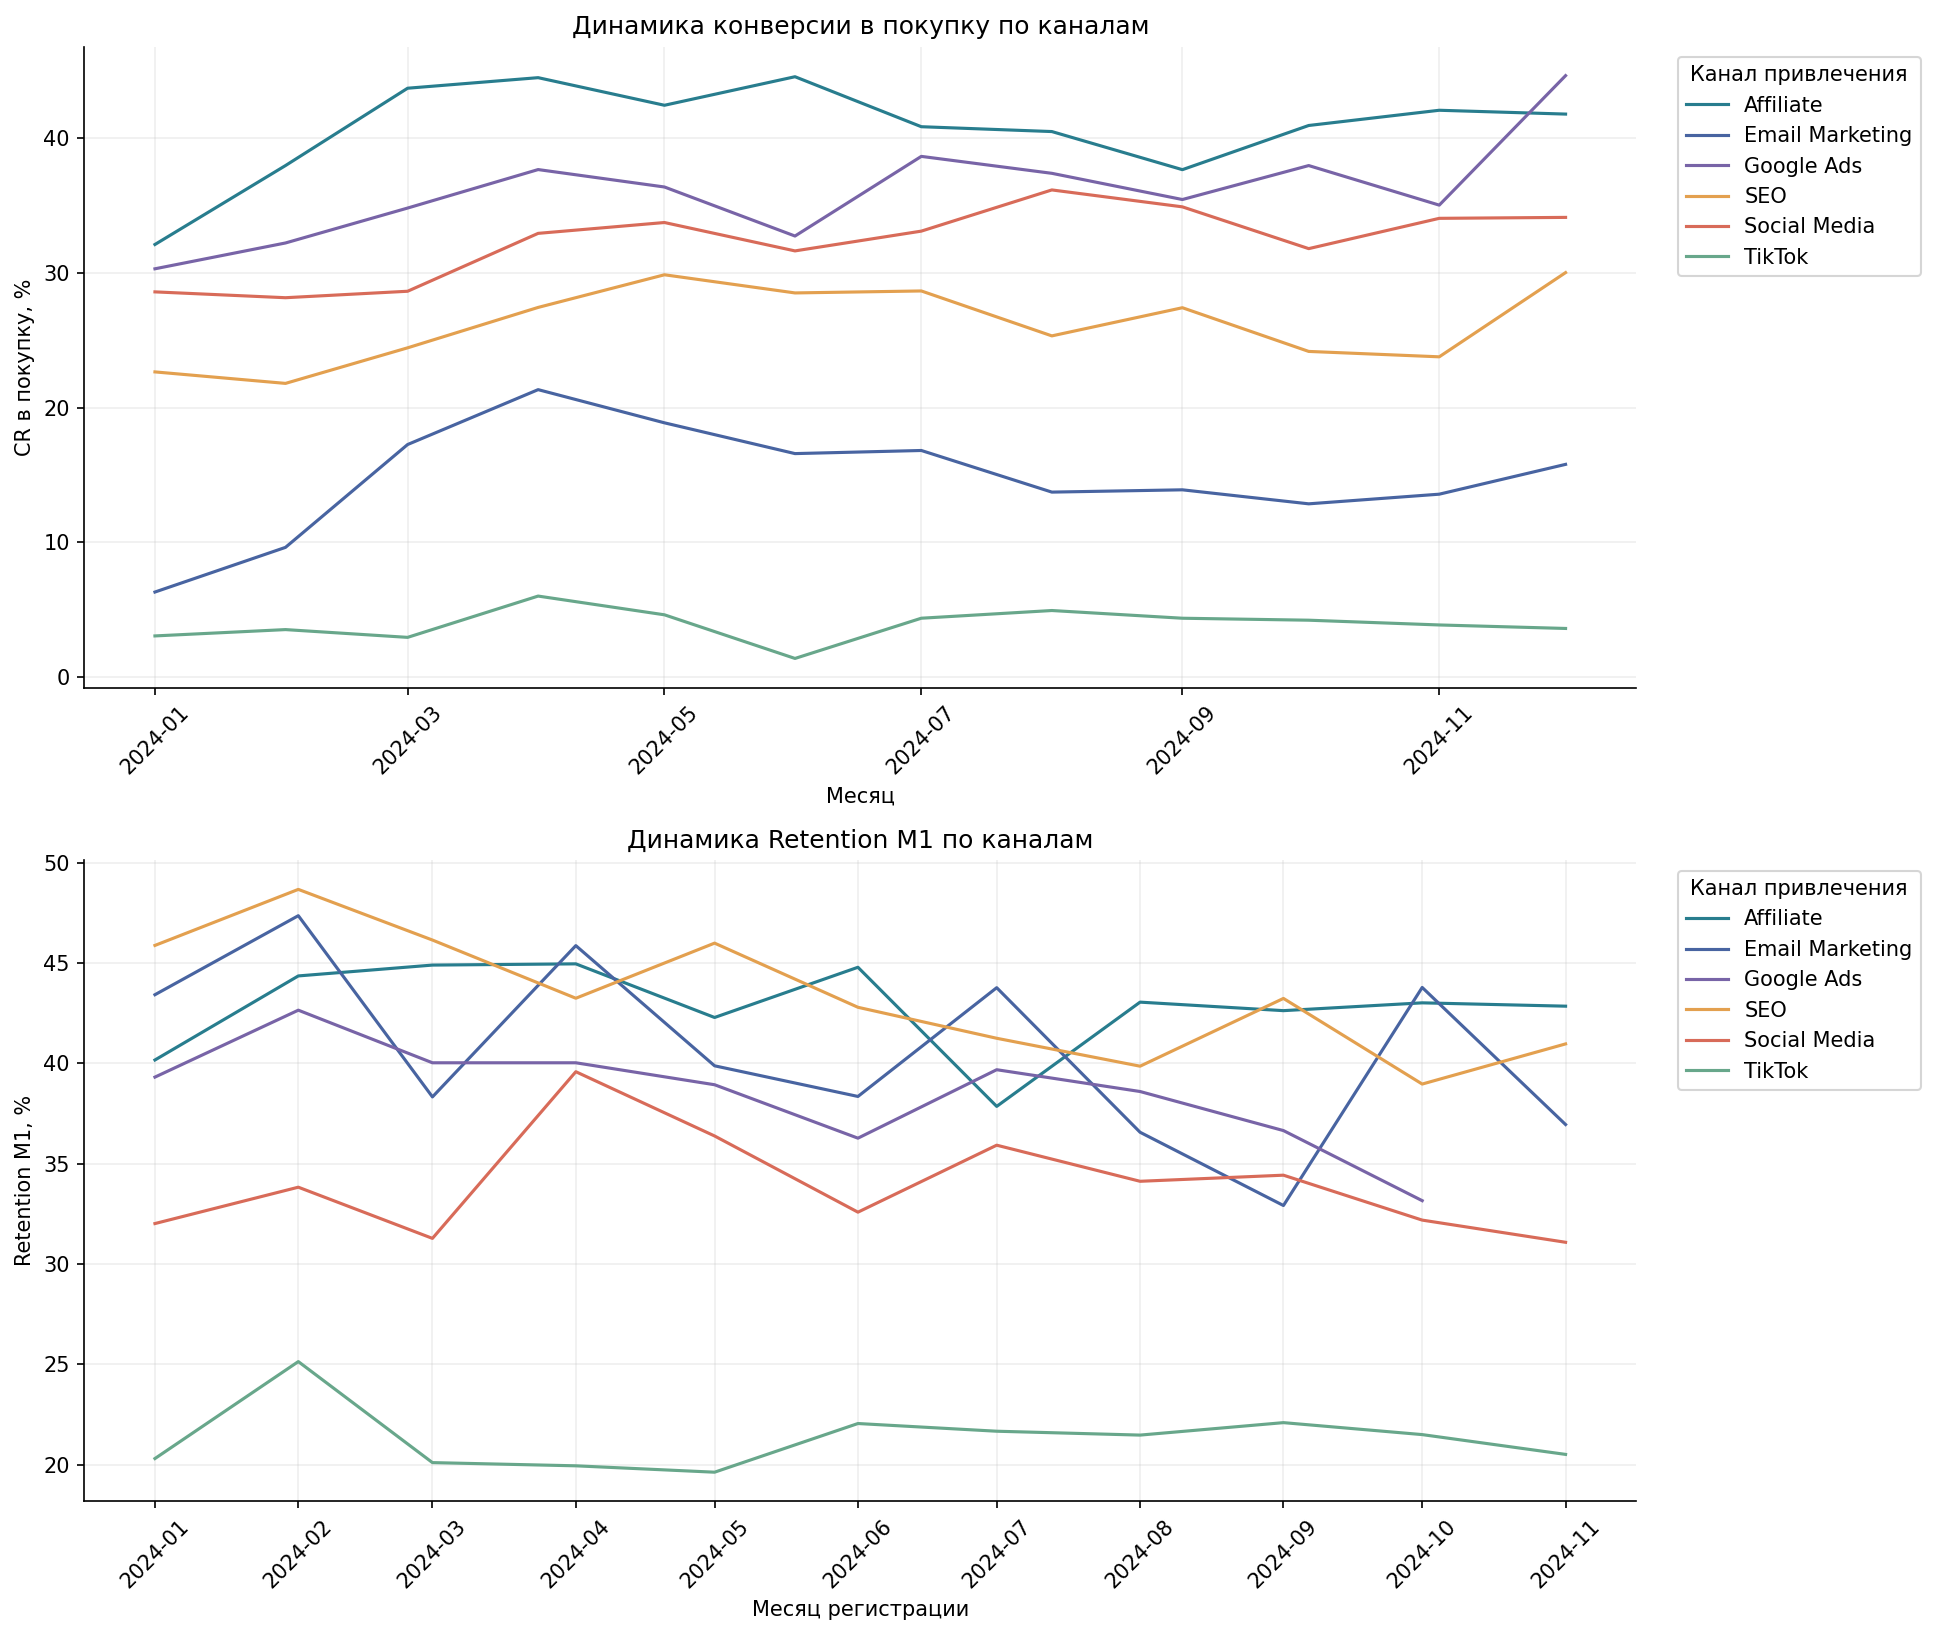

In [31]:
fig, axes = plt.subplots(2, 1, figsize=(13, 11))

sns.lineplot(
    data=monthly_channel_cr,
    x='event_month',
    y='cr_purchase',
    hue='acq_channel',
    palette=palette,
    ax=axes[0]
)

axes[0].set_title('Динамика конверсии в покупку по каналам')
axes[0].set_xlabel('Месяц')
axes[0].set_ylabel('CR в покупку, %')
axes[0].tick_params(axis='x', rotation=45)
axes[0].grid(alpha=0.2)
axes[0].legend(title='Канал привлечения', bbox_to_anchor=(1.02, 1), loc='upper left')

sns.lineplot(
    data=monthly_channel_retention,
    x='cohort_month',
    y='retention_m1',
    hue='acq_channel',
    palette=palette,
    ax=axes[1]
)

axes[1].set_title('Динамика Retention M1 по каналам')
axes[1].set_xlabel('Месяц регистрации')
axes[1].set_ylabel('Retention M1, %')
axes[1].tick_params(axis='x', rotation=45)
axes[1].grid(alpha=0.2)
axes[1].legend(title='Канал привлечения', bbox_to_anchor=(1.02, 1), loc='upper left')

plt.tight_layout()
plt.show()

Во второй половине 2024 года конверсия в покупку внутри большинства каналов оставалась относительно стабильной. При этом TikTok на протяжении всего года демонстрировал минимальную конверсию и удержание.

На фоне увеличения доли TikTok в привлечении с 13,20% до 76,20% общая конверсия маркетплейса снизилась. Это указывает на изменение структуры аудитории как на одно из наиболее вероятных объяснений ухудшения продуктовых метрик.

Retention M1 в отдельных каналах также демонстрировал снижение, однако наиболее низкие значения стабильно наблюдались у TikTok.

**Расчёт ROI по каналам**

In [32]:
channel_orders = cohort_orders.merge(
    users[['user_id', 'acq_channel']],
    on='user_id',
    how='left'
)

channel_revenue = (
    channel_orders[channel_orders['month_number'] <= 2]
    .groupby(['cohort_month', 'acq_channel'])['revenue']
    .sum()
    .reset_index()
)

channel_cohorts = (
    users.groupby(['cohort_month', 'acq_channel'])['user_id']
    .nunique()
    .reset_index(name='new_users')
)

channel_costs_monthly = campaign_costs.rename(
    columns={'spend_month': 'cohort_month'}
)

channel_roi = (
    channel_cohorts
    .merge(
        channel_costs_monthly,
        on=['cohort_month', 'acq_channel'],
        how='left'
    )
    .merge(
        channel_revenue,
        on=['cohort_month', 'acq_channel'],
        how='left'
    )
)

channel_roi['revenue'] = channel_roi['revenue'].fillna(0)

channel_roi = channel_roi[
    channel_roi['cohort_month'] <= '2024-10-01'
].copy()

channel_roi['roi_m2'] = (
    (channel_roi['revenue'] - channel_roi['budget'])
    / channel_roi['budget'] * 100
)

channel_roi_summary = (
    channel_roi.groupby('acq_channel')
    .agg(
        new_users=('new_users', 'sum'),
        revenue=('revenue', 'sum'),
        budget=('budget', 'sum')
    )
    .reset_index()
)

channel_roi_summary['roi_m2'] = (
    (channel_roi_summary['revenue'] - channel_roi_summary['budget'])
    / channel_roi_summary['budget'] * 100
)

channel_roi_summary = channel_roi_summary.sort_values(
    'roi_m2',
    ascending=False
)

display(channel_roi_summary.round(2))

,acq_channel,new_users,revenue,budget,roi_m2
0,Affiliate,5198,5331150.59,1625651.38,227.94
3,SEO,2855,1512629.84,535935.57,182.24
4,Social Media,3634,2319149.69,1361279.87,70.37
2,Google Ads,9319,7085404.44,4663489.65,51.93
1,Email Marketing,1764,439134.51,441510.30,-0.54
5,TikTok,12397,632574.08,5414073.16,-88.32


**Визуализация динамики ROI по каналам**

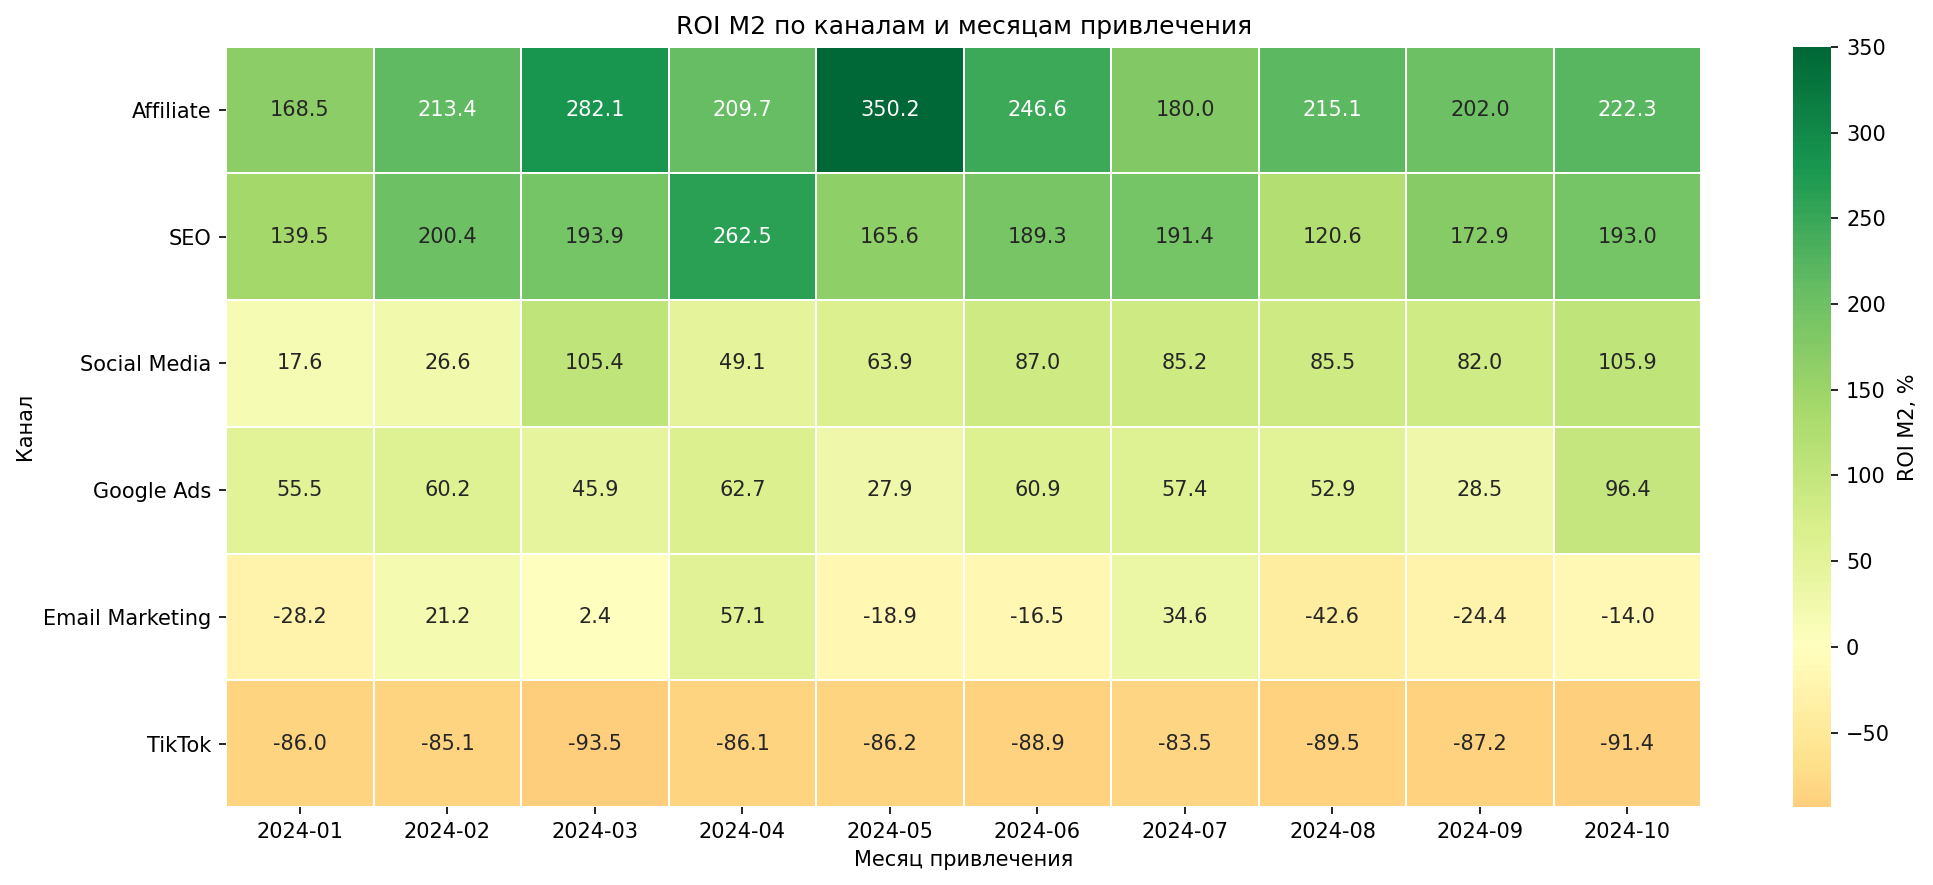

In [33]:
channel_roi_pivot = channel_roi.pivot(
    index='acq_channel',
    columns='cohort_month',
    values='roi_m2'
)

channel_roi_pivot.columns = (
    channel_roi_pivot.columns.strftime('%Y-%m')
)

channel_roi_pivot = channel_roi_pivot.loc[
    channel_roi_summary['acq_channel']
]

plt.figure(figsize=(14, 6))

sns.heatmap(
    channel_roi_pivot,
    annot=True,
    fmt='.1f',
    cmap='RdYlGn',
    center=0,
    linewidths=0.5,
    cbar_kws={'label': 'ROI M2, %'}
)

plt.title('ROI M2 по каналам и месяцам привлечения')
plt.xlabel('Месяц привлечения')
plt.ylabel('Канал')

plt.tight_layout()
plt.show()

Анализ когортного ROI показал устойчивые различия между каналами привлечения. **Affiliate** (168,5-350,2%) и **SEO** (120,6-262,5%) демонстрировали положительную окупаемость на протяжении всего периода. **Google Ads** и **Social Media** также сохраняли положительный ROI, тогда как результаты **Email Marketing** были нестабильными.

Наиболее проблемным каналом оказался **TikTok**: ROI оставался отрицательным во всех исследованных когортах (от -93,5% до -83,5%).

При этом во второй половине года объём привлечения через TikTok существенно увеличился. Это позволяет предположить, что ухудшение общей окупаемости связано преимущественно с изменением структуры привлечения, а не с массовым снижением эффективности отдельных каналов.

Для подтверждения гипотезы необходимо оценить вклад изменения долей каналов в общую динамику ROI.

**Анализ структуры привлечения пользователей по месяцам**

In [34]:
monthly_channel_users = (
    users.groupby(['cohort_month', 'acq_channel'])['user_id']
    .nunique()
    .reset_index(name='new_users')
)

channel_distribution = (
    monthly_channel_users.pivot(
        index='cohort_month',
        columns='acq_channel',
        values='new_users'
    )
    .fillna(0)
)

channel_distribution_pct = (
    channel_distribution
    .div(channel_distribution.sum(axis=1), axis=0)
    * 100
)

channel_distribution_pct.index = (
    channel_distribution_pct.index.strftime('%Y-%m')
)

display(channel_distribution_pct.round(2))

acq_channel,Affiliate,Email Marketing,Google Ads,SEO,Social Media,TikTok
cohort_month,,,,,,
2024-01,19.26,5.86,37.49,10.59,13.60,13.20
2024-02,20.62,7.01,36.92,9.77,12.32,13.35
2024-03,17.88,6.07,38.58,10.52,13.69,13.25
2024-04,20.52,6.68,39.21,9.95,11.74,11.91
2024-05,17.35,5.64,38.78,9.78,12.82,15.62
2024-06,15.73,5.20,33.45,9.15,11.14,25.34
2024-07,13.42,4.95,26.41,8.34,9.96,36.92
2024-08,11.22,3.95,19.70,6.68,8.53,49.92
2024-09,10.03,3.61,12.58,5.80,7.48,60.50


**Визуализация структуры привлечения по месяцам**

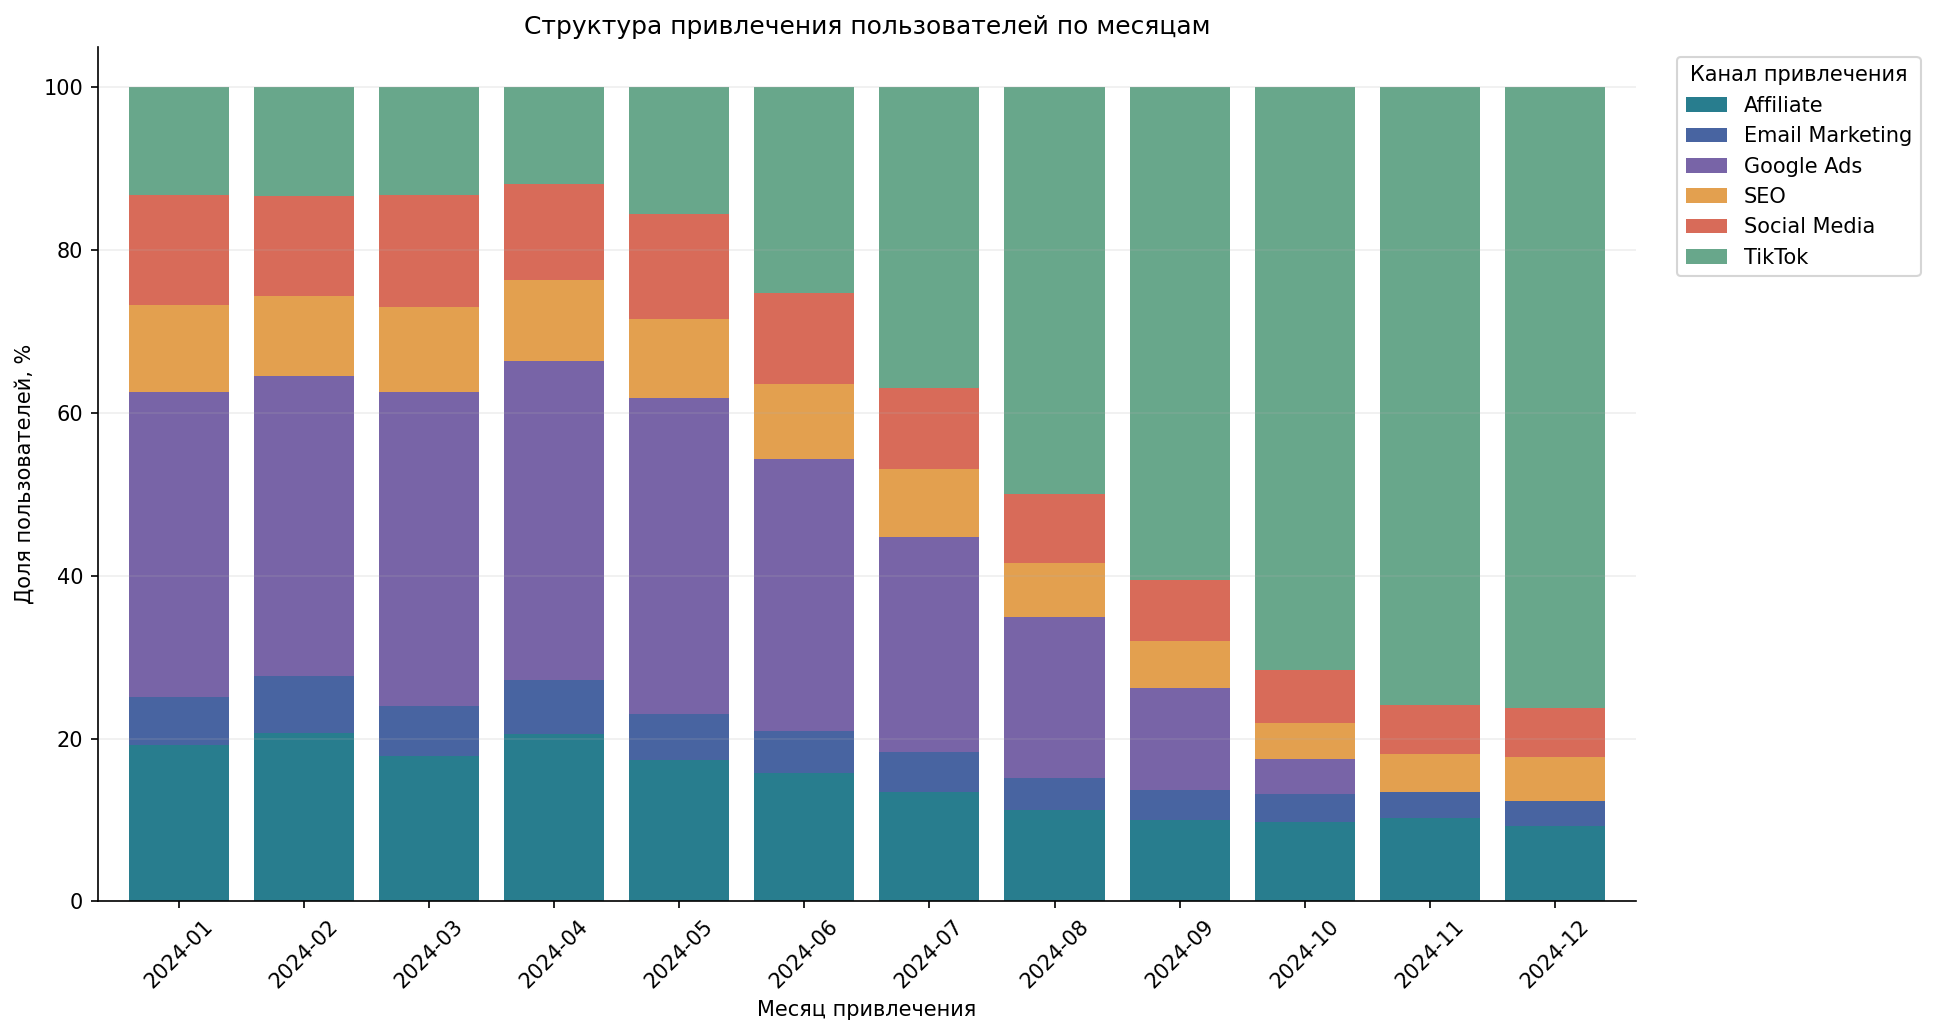

In [35]:
ax = channel_distribution_pct.plot(
    kind='bar',
    stacked=True,
    figsize=(13, 7),
    color=palette,
    width=0.8
)

ax.set_title('Структура привлечения пользователей по месяцам')
ax.set_xlabel('Месяц привлечения')
ax.set_ylabel('Доля пользователей, %')
ax.legend(title='Канал привлечения', bbox_to_anchor=(1.02, 1), loc='upper left')
ax.grid(axis='y', alpha=0.2)

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Во второй половине 2024 года структура привлечения существенно изменилась: доля **TikTok** увеличилась с 13,20% в январе до 76,20% в декабре. При этом канал демонстрирует минимальную конверсию в покупку (3,74%), низкое удержание (21,36%) и отрицательный ROI M2 (-88,32%). Одновременно сократилась доля более эффективных каналов - **Affiliate**, **SEO** и **Google Ads**. Таким образом, ухудшение конверсии, удержания и окупаемости маркетинга может быть связано с перераспределением привлечения в пользу низкоэффективного канала.

**Декомпозиция снижения конверсии в покупку**

In [36]:
start_month = pd.Timestamp('2024-04-01')
end_month = pd.Timestamp('2024-12-01')

cr_comparison = monthly_channel_cr[
    monthly_channel_cr['event_month'].isin([start_month, end_month])
].copy()

cr_comparison['channel_share'] = (
    cr_comparison['active_users'] /
    cr_comparison.groupby('event_month')['active_users'].transform('sum')
)

cr_decomposition = cr_comparison.pivot(
    index='acq_channel',
    columns='event_month',
    values=['channel_share', 'cr_purchase']
).fillna(0)

cr_decomposition.columns = [
    'share_apr', 'share_dec', 'cr_apr', 'cr_dec'
]

cr_decomposition['structure_effect'] = (
    (cr_decomposition['share_dec'] - cr_decomposition['share_apr'])
    * (cr_decomposition['cr_apr'] + cr_decomposition['cr_dec']) / 2
)

cr_decomposition['conversion_effect'] = (
    (cr_decomposition['cr_dec'] - cr_decomposition['cr_apr'])
    * (cr_decomposition['share_apr'] + cr_decomposition['share_dec']) / 2
)

cr_decomposition['total_effect'] = (
    cr_decomposition['structure_effect']
    + cr_decomposition['conversion_effect']
)

display(cr_decomposition.round(2))

structure_effect = cr_decomposition['structure_effect'].sum()
conversion_effect = cr_decomposition['conversion_effect'].sum()

cr_apr = (
    cr_decomposition['share_apr'] * cr_decomposition['cr_apr']
).sum()

cr_dec = (
    cr_decomposition['share_dec'] * cr_decomposition['cr_dec']
).sum()

print(f'CR в апреле: {cr_apr:.2f}%')
print(f'CR в декабре: {cr_dec:.2f}%')
print(f'Общее изменение: {cr_dec - cr_apr:+.2f} п. п.')
print(f'Вклад структуры привлечения: {structure_effect:+.2f} п. п.')
print(f'Вклад изменений CR внутри каналов: {conversion_effect:+.2f} п. п.')

,share_apr,share_dec,cr_apr,cr_dec,structure_effect,conversion_effect,total_effect
acq_channel,,,,,,,
Affiliate,0.22,0.16,44.44,41.75,-2.60,-0.52,-3.12
Email Marketing,0.07,0.05,21.33,15.79,-0.35,-0.34,-0.69
Google Ads,0.41,0.05,37.63,44.59,-14.92,1.58,-13.34
SEO,0.13,0.09,27.42,30.00,-1.14,0.27,-0.87
Social Media,0.11,0.08,32.91,34.09,-0.83,0.11,-0.72
TikTok,0.07,0.57,6.03,3.63,2.45,-0.77,1.68


CR в апреле: 34.08%
CR в декабре: 17.01%
Общее изменение: -17.07 п. п.
Вклад структуры привлечения: -17.40 п. п.
Вклад изменений CR внутри каналов: +0.33 п. п.


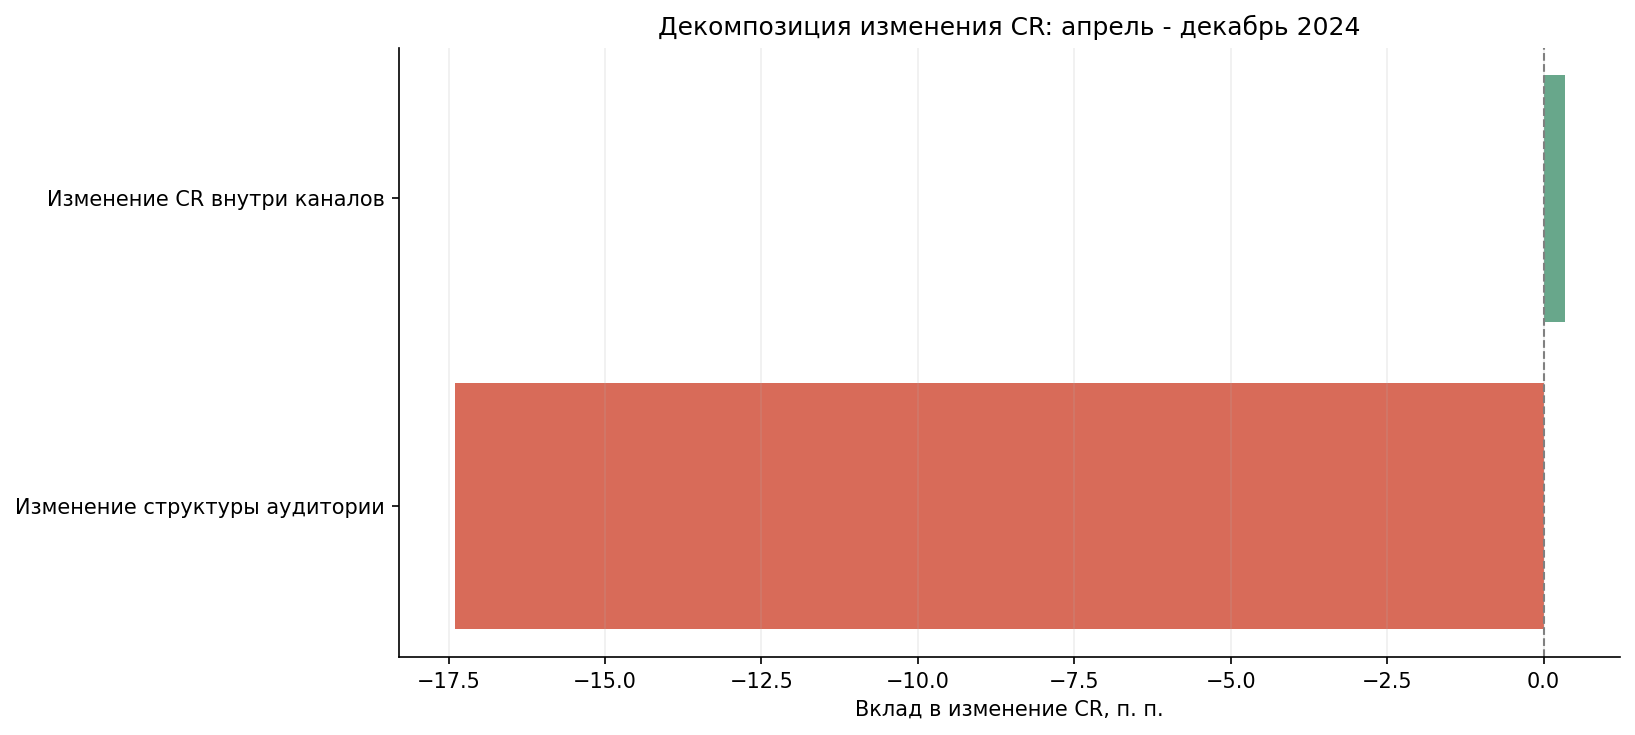

In [37]:
effects = pd.Series({
    'Изменение структуры аудитории': structure_effect,
    'Изменение CR внутри каналов': conversion_effect
})

colors = [
    palette[4] if value < 0 else palette[5]
    for value in effects
]

fig, ax = plt.subplots(figsize=(11, 5))

ax.barh(
    effects.index,
    effects.values,
    color=colors
)

ax.axvline(0, color='gray', linestyle='--', linewidth=1)

ax.set_title('Декомпозиция изменения CR: апрель - декабрь 2024')
ax.set_xlabel('Вклад в изменение CR, п. п.')
ax.set_ylabel('')
ax.grid(axis='x', alpha=0.2)

plt.tight_layout()
plt.show()

Декомпозиция конверсии показала, что с апреля по декабрь 2024 года общий CR пользователей с известным каналом привлечения снизился с 34,08% до 17,01% (-17,07 п. п.). Основной вклад внесло изменение структуры активной аудитории (-17,40 п. п.), тогда как совокупное изменение конверсии внутри каналов составило +0,33 п. п. Таким образом, ухудшение общей конверсии объясняется преимущественно перераспределением активной аудитории: доля каналов с высокой конверсией сокращалась, а доля TikTok с низкой конверсией увеличивалась.

**Анализ пользовательских сегментов**

In [38]:
segment_active = (
    events[['user_id', 'event_month']]
    .drop_duplicates()
    .merge(
        users[['user_id', 'buyer_segment']],
        on='user_id',
        how='inner'
    )
)

segment_buyers = (
    orders[['user_id', 'order_month']]
    .drop_duplicates()
    .merge(
        segment_active,
        left_on=['user_id', 'order_month'],
        right_on=['user_id', 'event_month'],
        how='inner'
    )
)

monthly_segment_active = (
    segment_active.groupby(['event_month', 'buyer_segment'])['user_id']
    .nunique()
    .reset_index(name='active_users')
)

monthly_segment_buyers = (
    segment_buyers.groupby(['event_month', 'buyer_segment'])['user_id']
    .nunique()
    .reset_index(name='buyers')
)

segment_orders = orders.merge(
    users[['user_id', 'buyer_segment']],
    on='user_id',
    how='inner'
)

monthly_segment_revenue = (
    segment_orders.groupby(['order_month', 'buyer_segment'])
    .agg(
        revenue=('total_price', lambda x: x.sum() * 0.05),
        orders_count=('order_id', 'nunique')
    )
    .reset_index()
    .rename(columns={'order_month': 'event_month'})
)

monthly_segment_metrics = (
    monthly_segment_active
    .merge(
        monthly_segment_buyers,
        on=['event_month', 'buyer_segment'],
        how='left'
    )
    .merge(
        monthly_segment_revenue,
        on=['event_month', 'buyer_segment'],
        how='left'
    )
)

monthly_segment_metrics[
    ['buyers', 'revenue', 'orders_count']
] = monthly_segment_metrics[
    ['buyers', 'revenue', 'orders_count']
].fillna(0)

monthly_segment_metrics['cr_purchase'] = (
    monthly_segment_metrics['buyers']
    / monthly_segment_metrics['active_users'] * 100
)

monthly_segment_metrics['arpu'] = (
    monthly_segment_metrics['revenue']
    / monthly_segment_metrics['active_users']
)

monthly_segment_metrics['arppu'] = (
    monthly_segment_metrics['revenue']
    / monthly_segment_metrics['buyers'].replace(0, np.nan)
    
    
)

monthly_segment_all_buyers = (
    segment_orders.groupby(['order_month', 'buyer_segment'])['user_id']
    .nunique()
    .reset_index(name='all_buyers')
    .rename(columns={'order_month': 'event_month'})
)

monthly_segment_metrics = monthly_segment_metrics.drop(
    columns=['all_buyers'],
    errors='ignore'
).merge(
    monthly_segment_all_buyers,
    on=['event_month', 'buyer_segment'],
    how='left'
)

monthly_segment_metrics['arppu'] = (
    monthly_segment_metrics['revenue']
    / monthly_segment_metrics['all_buyers'].replace(0, np.nan)
)

display(monthly_segment_metrics.round(2).head())



,event_month,buyer_segment,active_users,buyers,revenue,orders_count,cr_purchase,arpu,arppu,all_buyers
0,2024-01-01,medium,482,97,192767.69,258,20.12,399.93,1133.93,170
1,2024-01-01,one_time,40,1,7543.62,15,2.50,188.59,580.28,13
2,2024-01-01,rare,260,10,47301.42,58,3.85,181.93,1212.86,39
3,2024-01-01,regular,320,179,375872.86,599,55.94,1174.60,1732.13,217
4,2024-02-01,medium,942,217,343316.77,503,23.04,364.46,1053.12,326


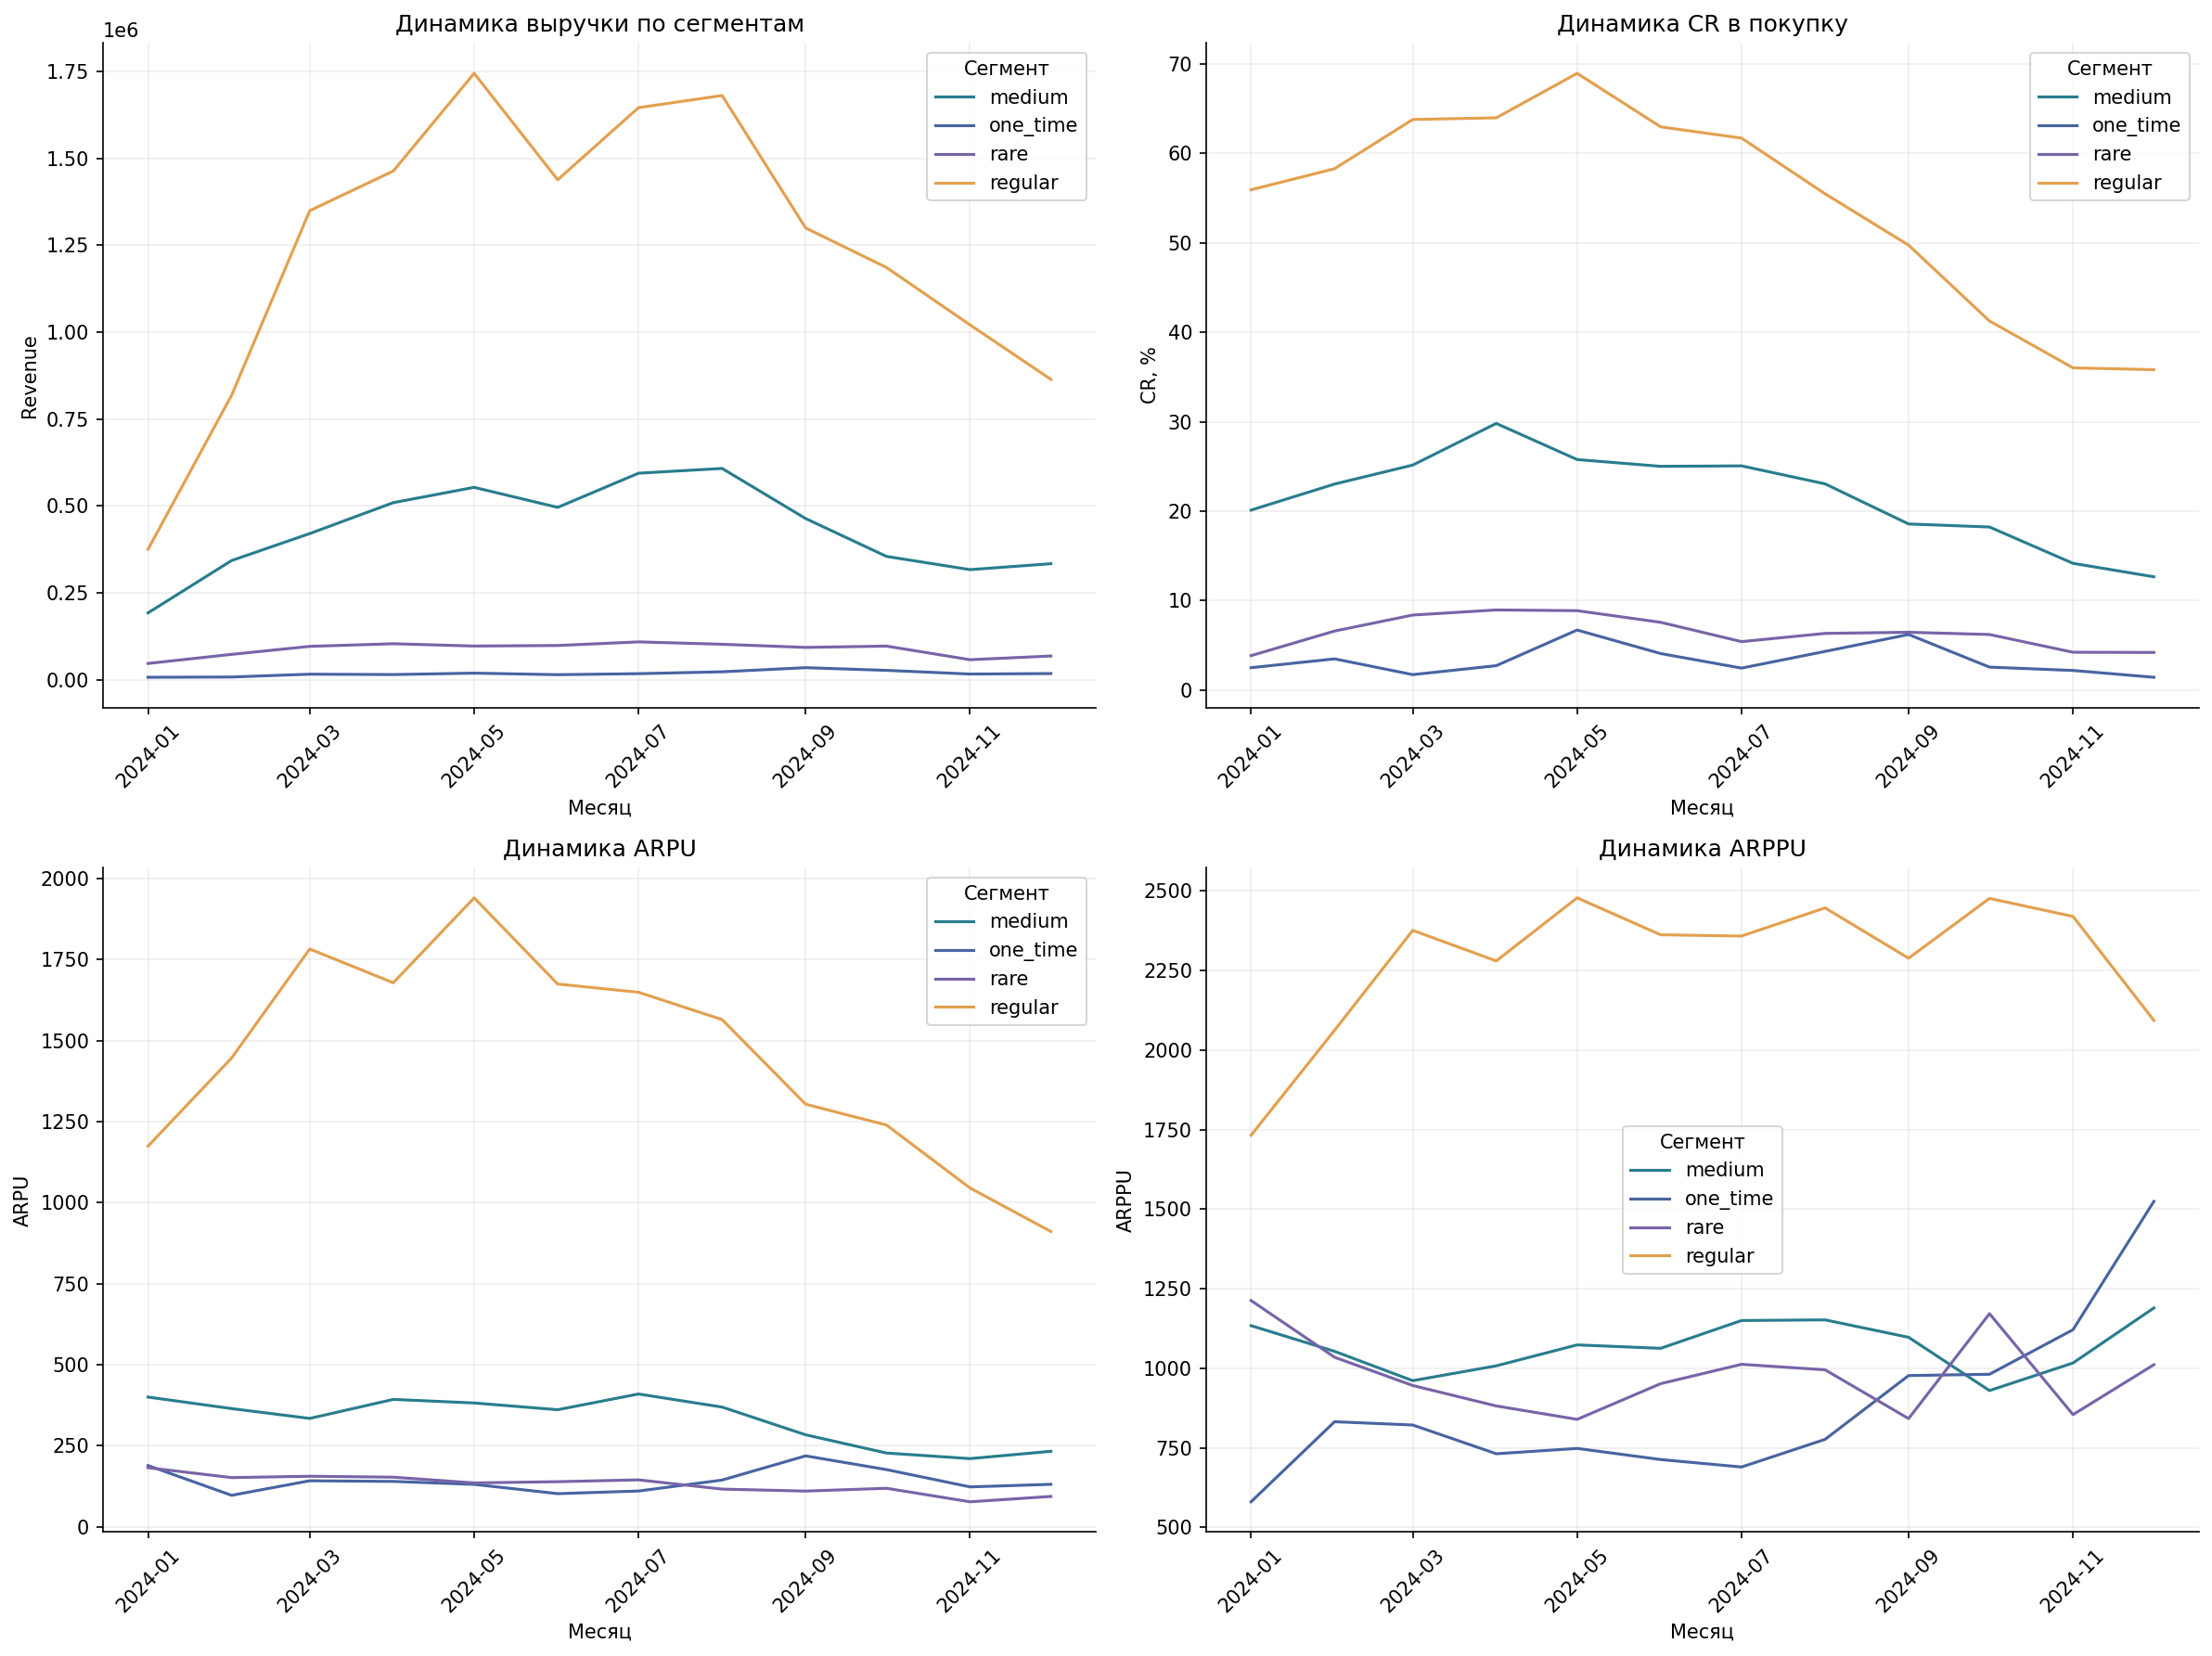

In [39]:
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

metrics = [
    ('revenue', 'Динамика выручки по сегментам', 'Revenue'),
    ('cr_purchase', 'Динамика CR в покупку', 'CR, %'),
    ('arpu', 'Динамика ARPU', 'ARPU'),
    ('arppu', 'Динамика ARPPU', 'ARPPU')
]

for ax, (column, title, ylabel) in zip(axes.flat, metrics):
    sns.lineplot(
        data=monthly_segment_metrics,
        x='event_month',
        y=column,
        hue='buyer_segment',
        palette=palette[:4],
        ax=ax
    )

    ax.set_title(title)
    ax.set_xlabel('Месяц')
    ax.set_ylabel(ylabel)
    ax.tick_params(axis='x', rotation=45)
    ax.grid(alpha=0.2)
    ax.legend(title='Сегмент')

plt.tight_layout()
plt.show()

Во второй половине 2024 года покупательская активность снизилась во всех пользовательских сегментах. Наиболее существенное падение выручки наблюдается в сегменте regular: с 1,74 млн в мае до 864,5 тыс. в декабре.

Конверсия в покупку у regular сократилась с 68,97% до 35,83%, у medium - с 25,78% до 12,67%. При этом снижение ARPU особенно заметно в сегменте regular.

Таким образом, ухудшение продуктовых показателей затрагивает не только пользователей с низкой покупательской активностью, но и наиболее доходный сегмент маркетплейса. Это делает снижение конверсии regular одной из приоритетных областей дальнейшего исследования.

**Анализ регионов пользователей**

In [40]:
region_active = (
    events[['user_id', 'event_month']]
    .drop_duplicates()
    .merge(
        users[['user_id', 'region']],
        on='user_id',
        how='inner'
    )
)

monthly_region_active = (
    region_active.groupby(['event_month', 'region'])['user_id']
    .nunique()
    .reset_index(name='active_users')
)

region_buyers = (
    orders[['user_id', 'order_month']]
    .drop_duplicates()
    .merge(
        region_active,
        left_on=['user_id', 'order_month'],
        right_on=['user_id', 'event_month'],
        how='inner'
    )
)

monthly_region_buyers = (
    region_buyers.groupby(['event_month', 'region'])['user_id']
    .nunique()
    .reset_index(name='buyers')
)

region_orders = orders.merge(
    users[['user_id', 'region']],
    on='user_id',
    how='inner'
)

monthly_region_revenue = (
    region_orders.groupby(['order_month', 'region'])
    .agg(
        revenue=('total_price', lambda x: x.sum() * 0.05)
    )
    .reset_index()
    .rename(columns={'order_month': 'event_month'})
)

monthly_region_metrics = (
    monthly_region_active
    .merge(
        monthly_region_buyers,
        on=['event_month', 'region'],
        how='left'
    )
    .merge(
        monthly_region_revenue,
        on=['event_month', 'region'],
        how='left'
    )
)

monthly_region_metrics[['buyers', 'revenue']] = (
    monthly_region_metrics[['buyers', 'revenue']].fillna(0)
)

monthly_region_metrics['cr_purchase'] = (
    monthly_region_metrics['buyers'] /
    monthly_region_metrics['active_users'] * 100
)

monthly_region_metrics['arpu'] = (
    monthly_region_metrics['revenue'] /
    monthly_region_metrics['active_users']
)

display(monthly_region_metrics.round(2))

,event_month,region,active_users,buyers,revenue,cr_purchase,arpu
0,2024-01-01,Другие регионы,391,98,206508.10,25.06,528.15
1,2024-01-01,Екатеринбург,54,12,19770.30,22.22,366.12
2,2024-01-01,Краснодар,40,16,26599.08,40.00,664.98
3,2024-01-01,Москва,272,70,132517.24,25.74,487.20
4,2024-01-01,Московская область,80,24,52964.27,30.00,662.05
...,...,...,...,...,...,...,...
103,2024-12-01,Московская область,269,44,114971.88,16.36,427.40
104,2024-12-01,Нижний Новгород,145,28,82224.37,19.31,567.06
105,2024-12-01,Новосибирск,141,21,45154.84,14.89,320.25
106,2024-12-01,Ростов-на-Дону,107,25,46923.54,23.36,438.54


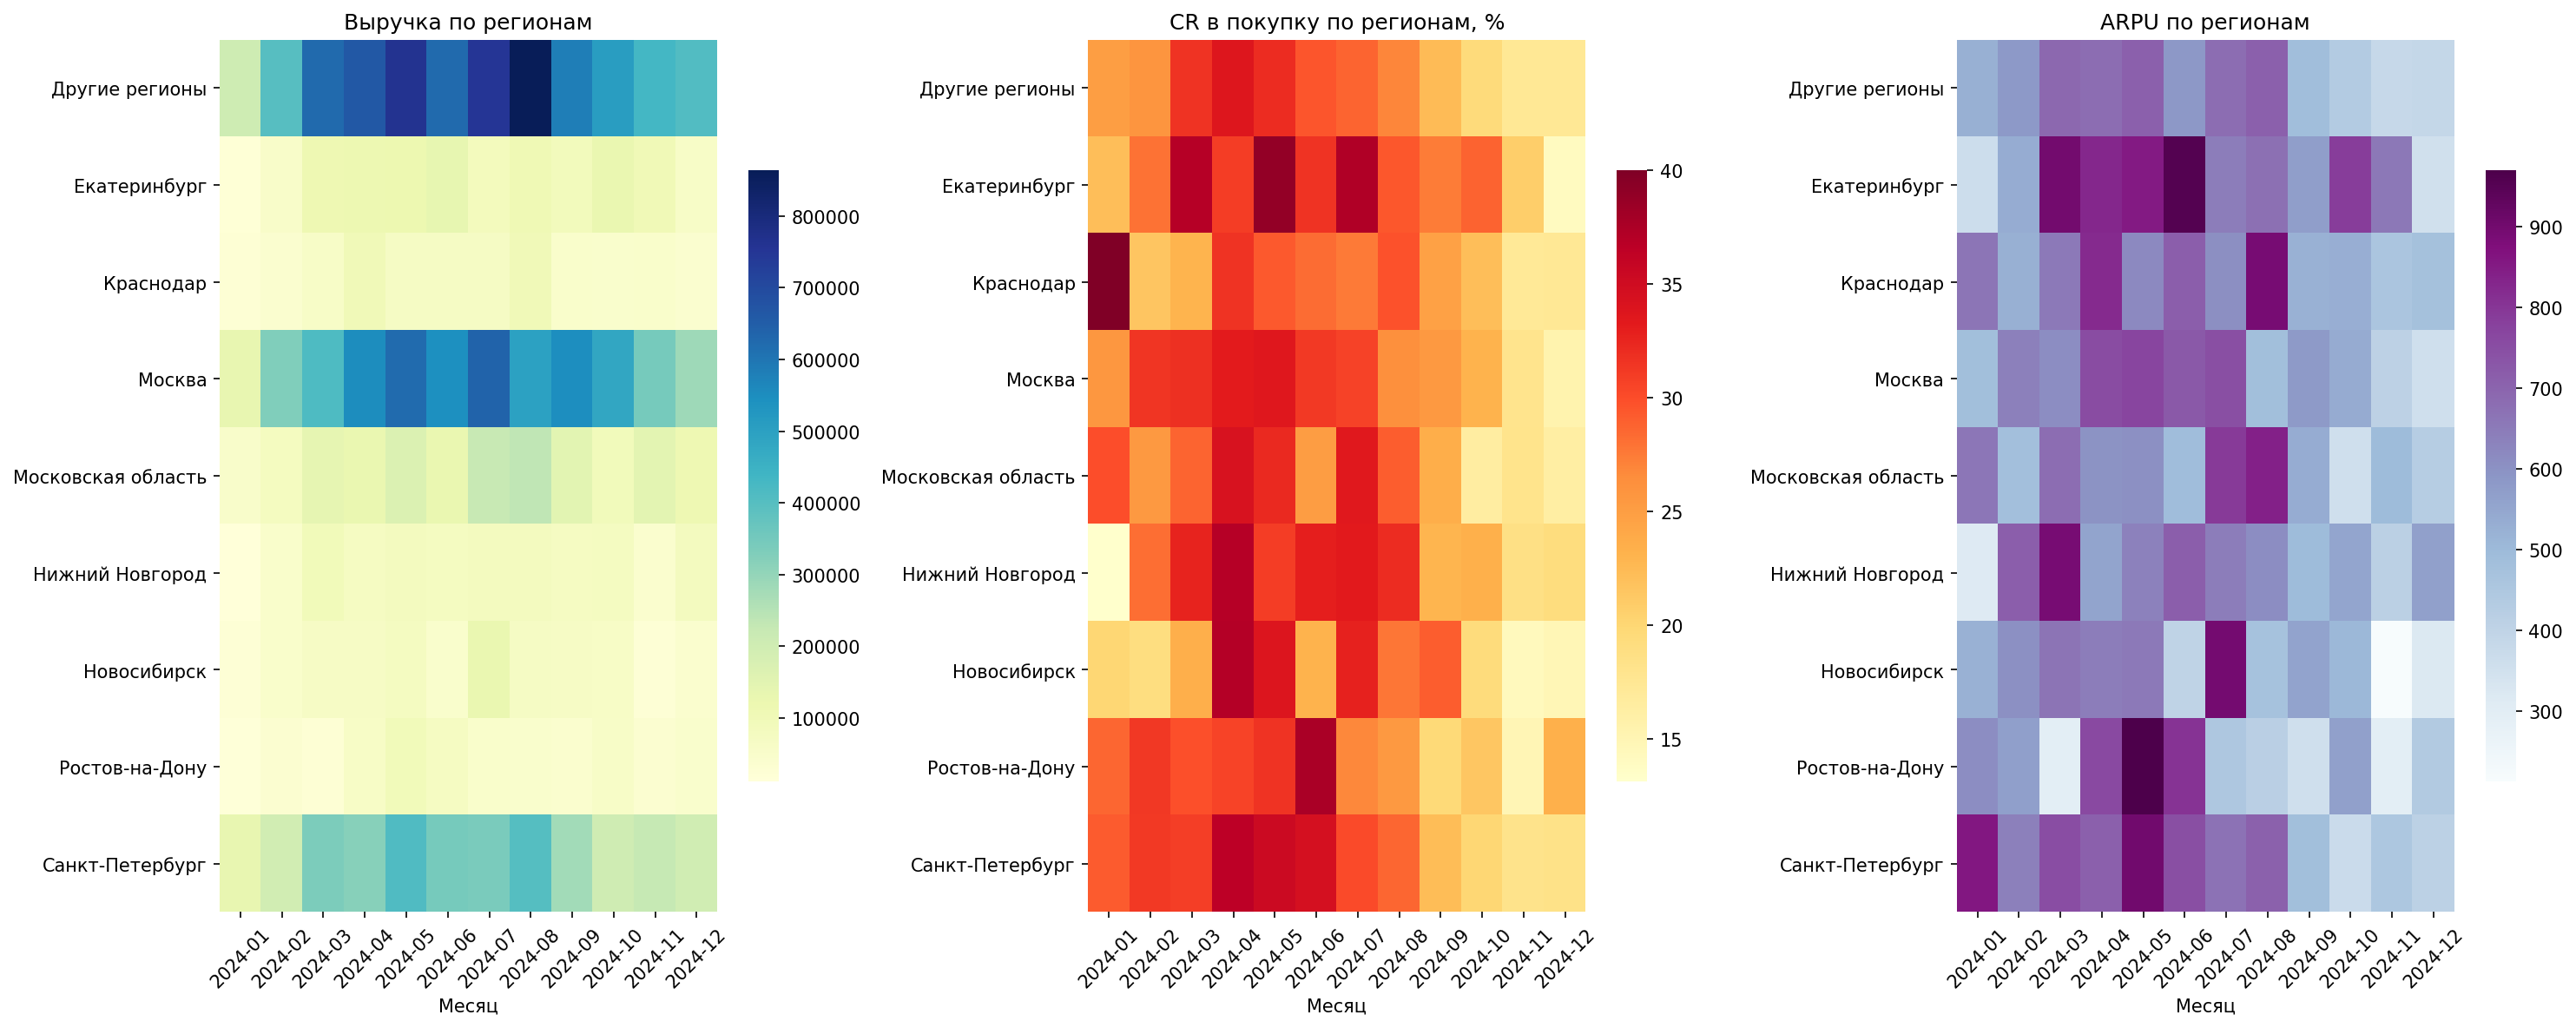

In [41]:
fig, axes = plt.subplots(1, 3, figsize=(20, 8))

metrics = [
    ('revenue', 'Выручка по регионам', 'YlGnBu'),
    ('cr_purchase', 'CR в покупку по регионам, %', 'YlOrRd'),
    ('arpu', 'ARPU по регионам', 'BuPu')
]

for ax, (metric, title, cmap) in zip(axes, metrics):

    pivot = monthly_region_metrics.pivot(
        index='region',
        columns='event_month',
        values=metric
    )

    pivot.columns = pivot.columns.strftime('%Y-%m')

    sns.heatmap(
        pivot,
        cmap=cmap,
        ax=ax,
        cbar_kws={'shrink': 0.7}
    )

    ax.set_title(title)
    ax.set_xlabel('Месяц')
    ax.set_ylabel('')
    ax.tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

Во второй половине 2024 года снижение выручки, конверсии в покупку и ARPU наблюдается практически во всех регионах. Наиболее высокие значения CR преимущественно приходились на весенние месяцы, после чего показатели постепенно ухудшались.

Таким образом, снижение продуктовых метрик носит общерегиональный характер и не связано исключительно с отдельными географическими сегментами. Это согласуется с ранее выявленным изменением структуры привлечения пользователей.

**Анализ устройств пользователей**

In [42]:
monthly_device_metrics = (
    events.groupby(['event_month', 'device'])
    .agg(
        active_users=('user_id', 'nunique'),
        events_count=('event_id', 'count')
    )
    .reset_index()
)

monthly_device_metrics['events_per_user'] = (
    monthly_device_metrics['events_count'] /
    monthly_device_metrics['active_users']
)

monthly_os_metrics = (
    events.groupby(['event_month', 'os'])
    .agg(
        active_users=('user_id', 'nunique'),
        events_count=('event_id', 'count')
    )
    .reset_index()
)

monthly_os_metrics['events_per_user'] = (
    monthly_os_metrics['events_count'] /
    monthly_os_metrics['active_users']
)

display(monthly_device_metrics.round(2).head())
display(monthly_os_metrics.round(2).head())

,event_month,device,active_users,events_count,events_per_user
0,2024-01-01,desktop,366,7800,21.31
1,2024-01-01,mobile,393,8611,21.91
2,2024-01-01,tablet,390,7831,20.08
3,2024-02-01,desktop,734,15814,21.54
4,2024-02-01,mobile,717,14705,20.51


,event_month,os,active_users,events_count,events_per_user
0,2024-01-01,Android,299,6687,22.36
1,2024-01-01,Windows,282,5457,19.35
2,2024-01-01,iOS,287,5884,20.50
3,2024-01-01,macOS,281,6214,22.11
4,2024-02-01,Android,564,13030,23.10


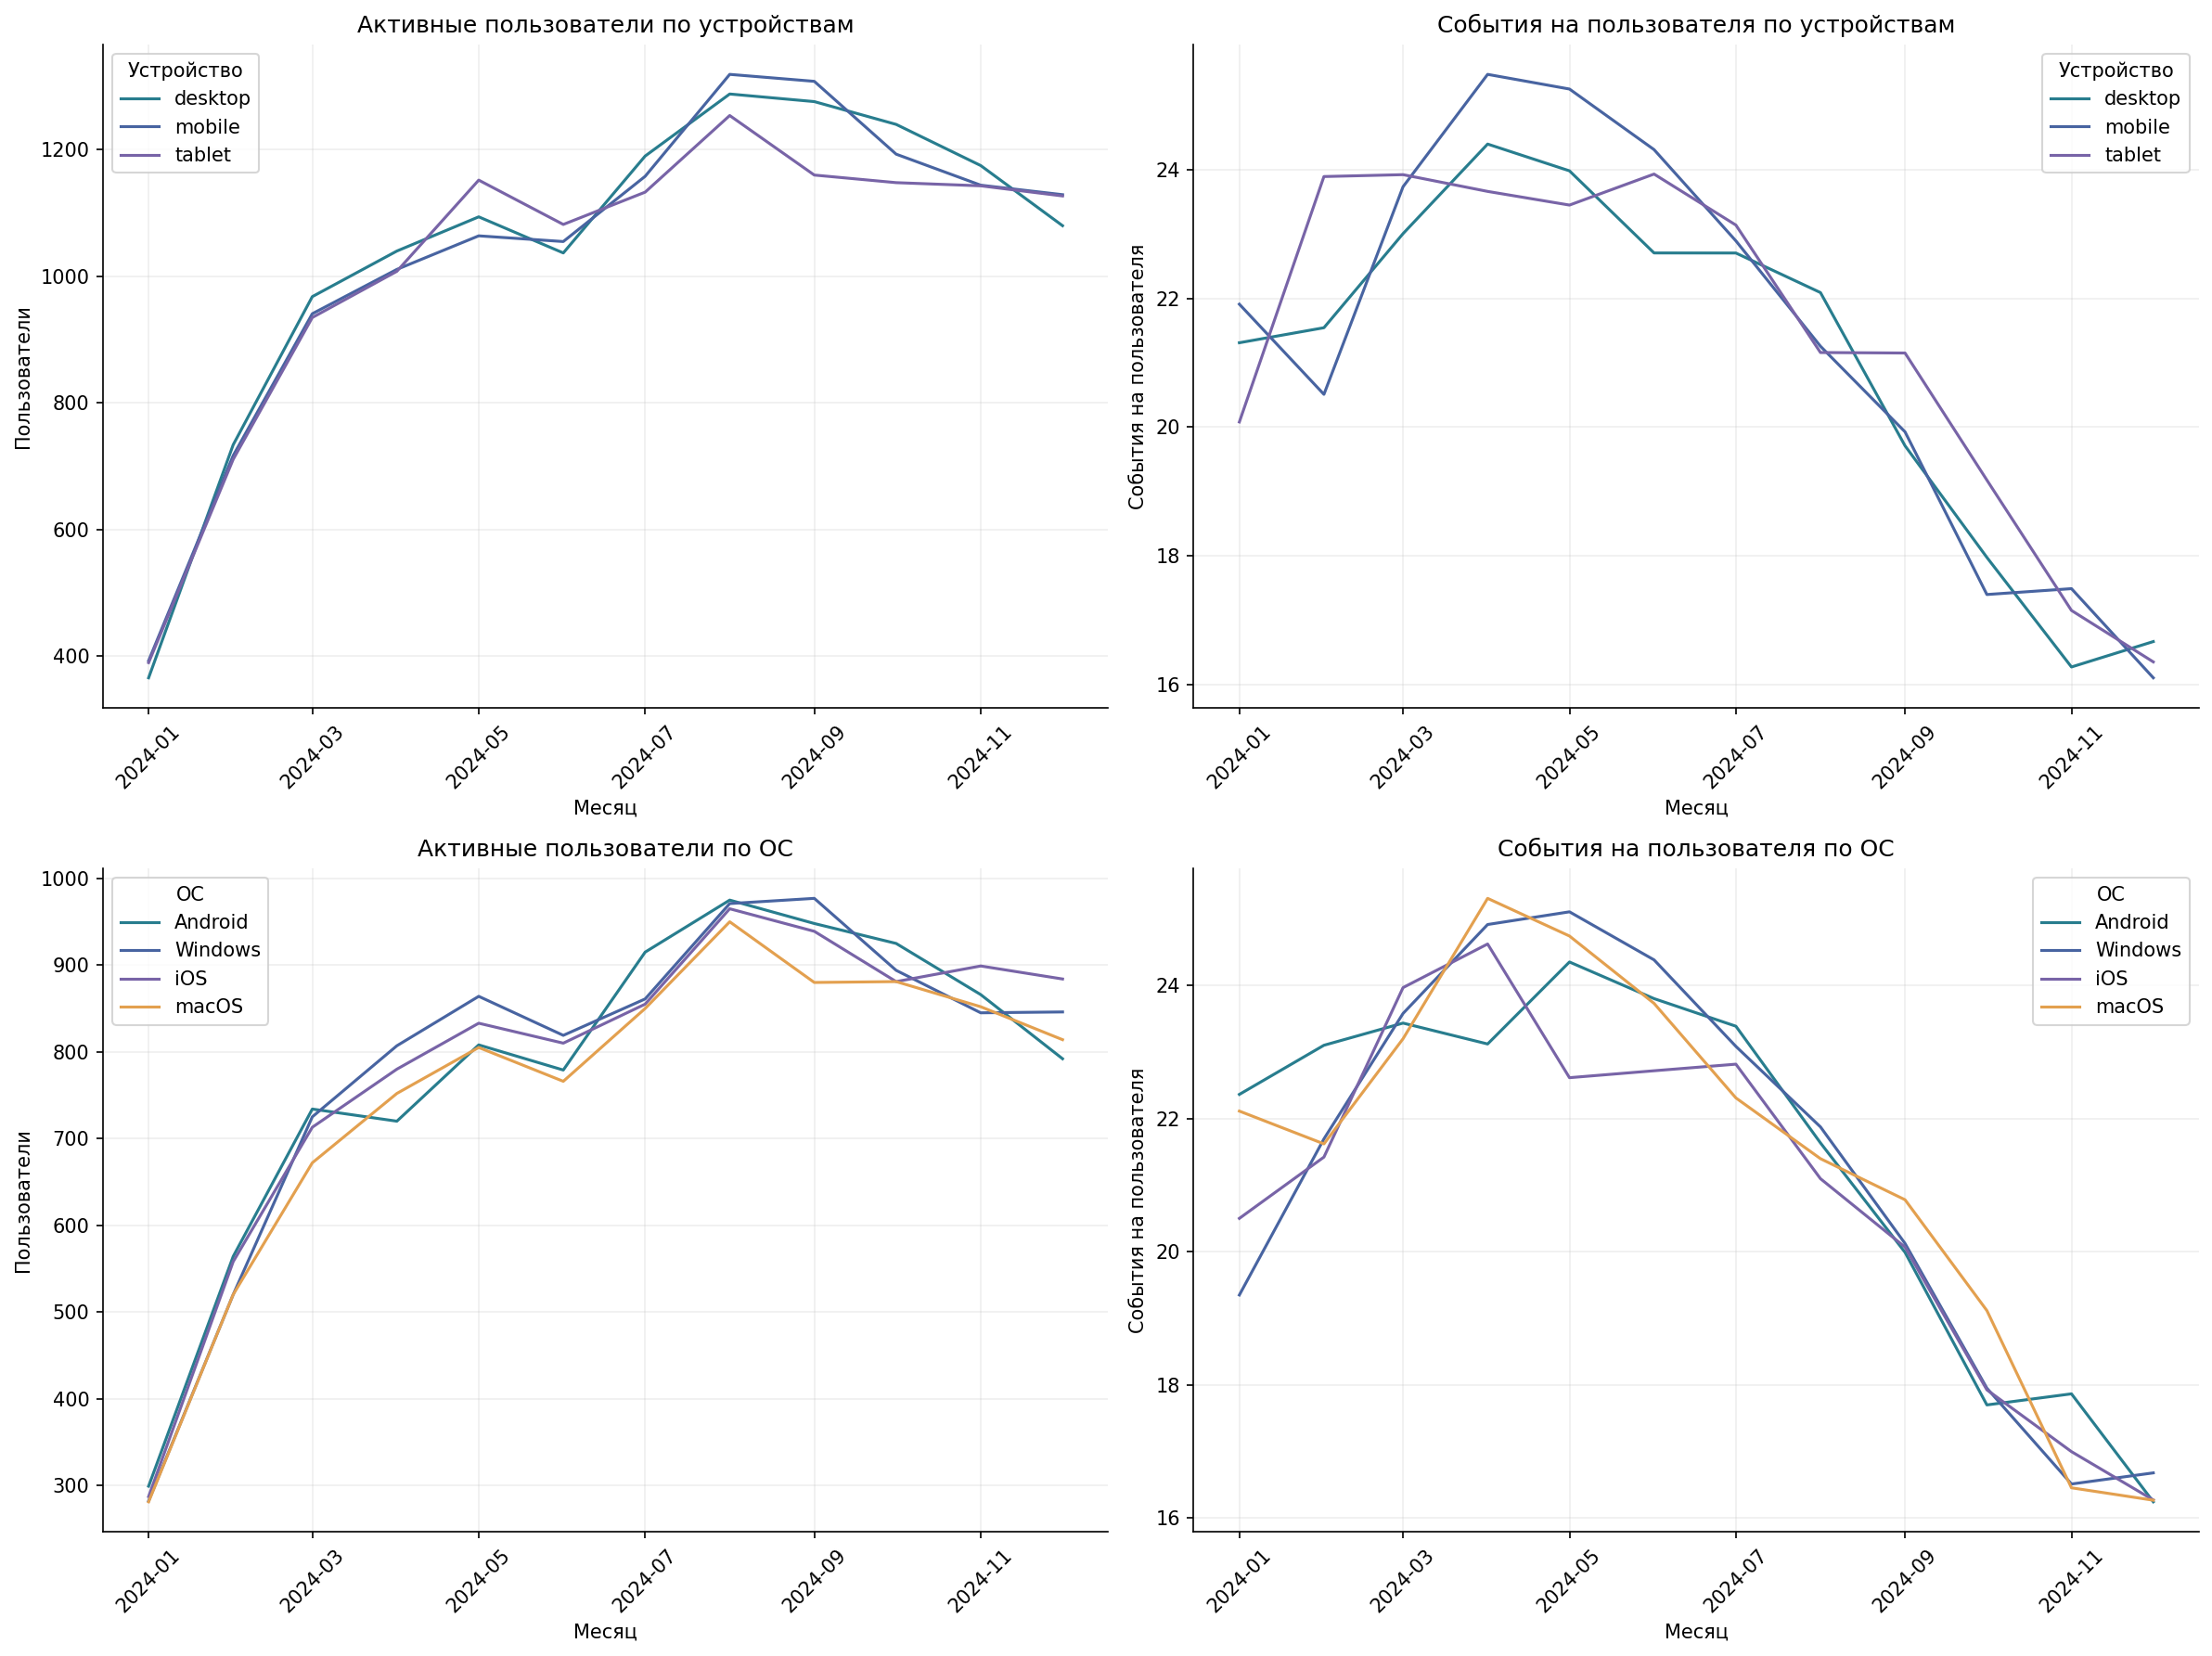

In [43]:
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

metrics = [
    (
        monthly_device_metrics, 'device', 'active_users',
        'Активные пользователи по устройствам', 'Пользователи'
    ),
    (
        monthly_device_metrics, 'device', 'events_per_user',
        'События на пользователя по устройствам', 'События на пользователя'
    ),
    (
        monthly_os_metrics, 'os', 'active_users',
        'Активные пользователи по ОС', 'Пользователи'
    ),
    (
        monthly_os_metrics, 'os', 'events_per_user',
        'События на пользователя по ОС', 'События на пользователя'
    )
]

for ax, (df, segment, metric, title, ylabel) in zip(axes.flat, metrics):

    categories = sorted(df[segment].dropna().unique())
    colors = {
        category: palette[i % len(palette)]
        for i, category in enumerate(categories)
    }

    sns.lineplot(
        data=df,
        x='event_month',
        y=metric,
        hue=segment,
        palette=colors,
        ax=ax
    )

    ax.set_title(title)
    ax.set_xlabel('Месяц')
    ax.set_ylabel(ylabel)
    ax.tick_params(axis='x', rotation=45)
    ax.grid(alpha=0.2)
    ax.legend(title='Устройство' if segment == 'device' else 'ОС')

plt.tight_layout()
plt.show()

Во второй половине 2024 года снижение активности наблюдается на всех типах устройств и операционных системах. Количество активных пользователей достигало максимальных значений летом, после чего постепенно сокращалось. Одновременно уменьшалось среднее число событий на пользователя. При этом существенных различий в динамике между устройствами и ОС не обнаружено. Таким образом, сокращение пользовательской активности носит общий характер и не связано исключительно с отдельной технической платформой.

**Анализ категорий товаров**

In [44]:
category_metrics = (
    orders.groupby('category_name')
    .agg(
        orders_count=('order_id', 'nunique'),
        buyers=('user_id', 'nunique'),
        total_sales=('total_price', 'sum')
    )
    .reset_index()
)

category_metrics['revenue'] = (
    category_metrics['total_sales'] * 0.05
)

category_metrics['aov'] = (
    category_metrics['total_sales'] / category_metrics['orders_count']
)

category_metrics['revenue_share'] = (
    category_metrics['revenue'] /
    category_metrics['revenue'].sum() * 100
)

category_metrics = (
    category_metrics
    .drop(columns='total_sales')
    .sort_values('revenue', ascending=False)
)


category_monthly = (
    orders.groupby(['order_month', 'category_name'])
    .agg(
        orders_count=('order_id', 'nunique'),
        revenue=('total_price', lambda x: x.sum() * 0.05)
    )
    .reset_index()
)

category_monthly['revenue_per_order'] = (
    category_monthly['revenue'] /
    category_monthly['orders_count']
)

top_categories = (
    category_metrics.nlargest(5, 'revenue')['category_name']
)

category_monthly_top = category_monthly[
    category_monthly['category_name'].isin(top_categories)
].copy()

display(category_monthly_top.round(2).head())

,order_month,category_name,orders_count,revenue,revenue_per_order
2,2024-01-01,Бытовая техника,18,39062.53,2170.14
11,2024-01-01,Мебель для дома,29,111108.35,3831.32
18,2024-01-01,Спортивный инвентарь,27,39145.42,1449.83
23,2024-01-01,Товары для туризма,21,21651.56,1031.03
24,2024-01-01,Украшения и часы,28,46796.21,1671.29


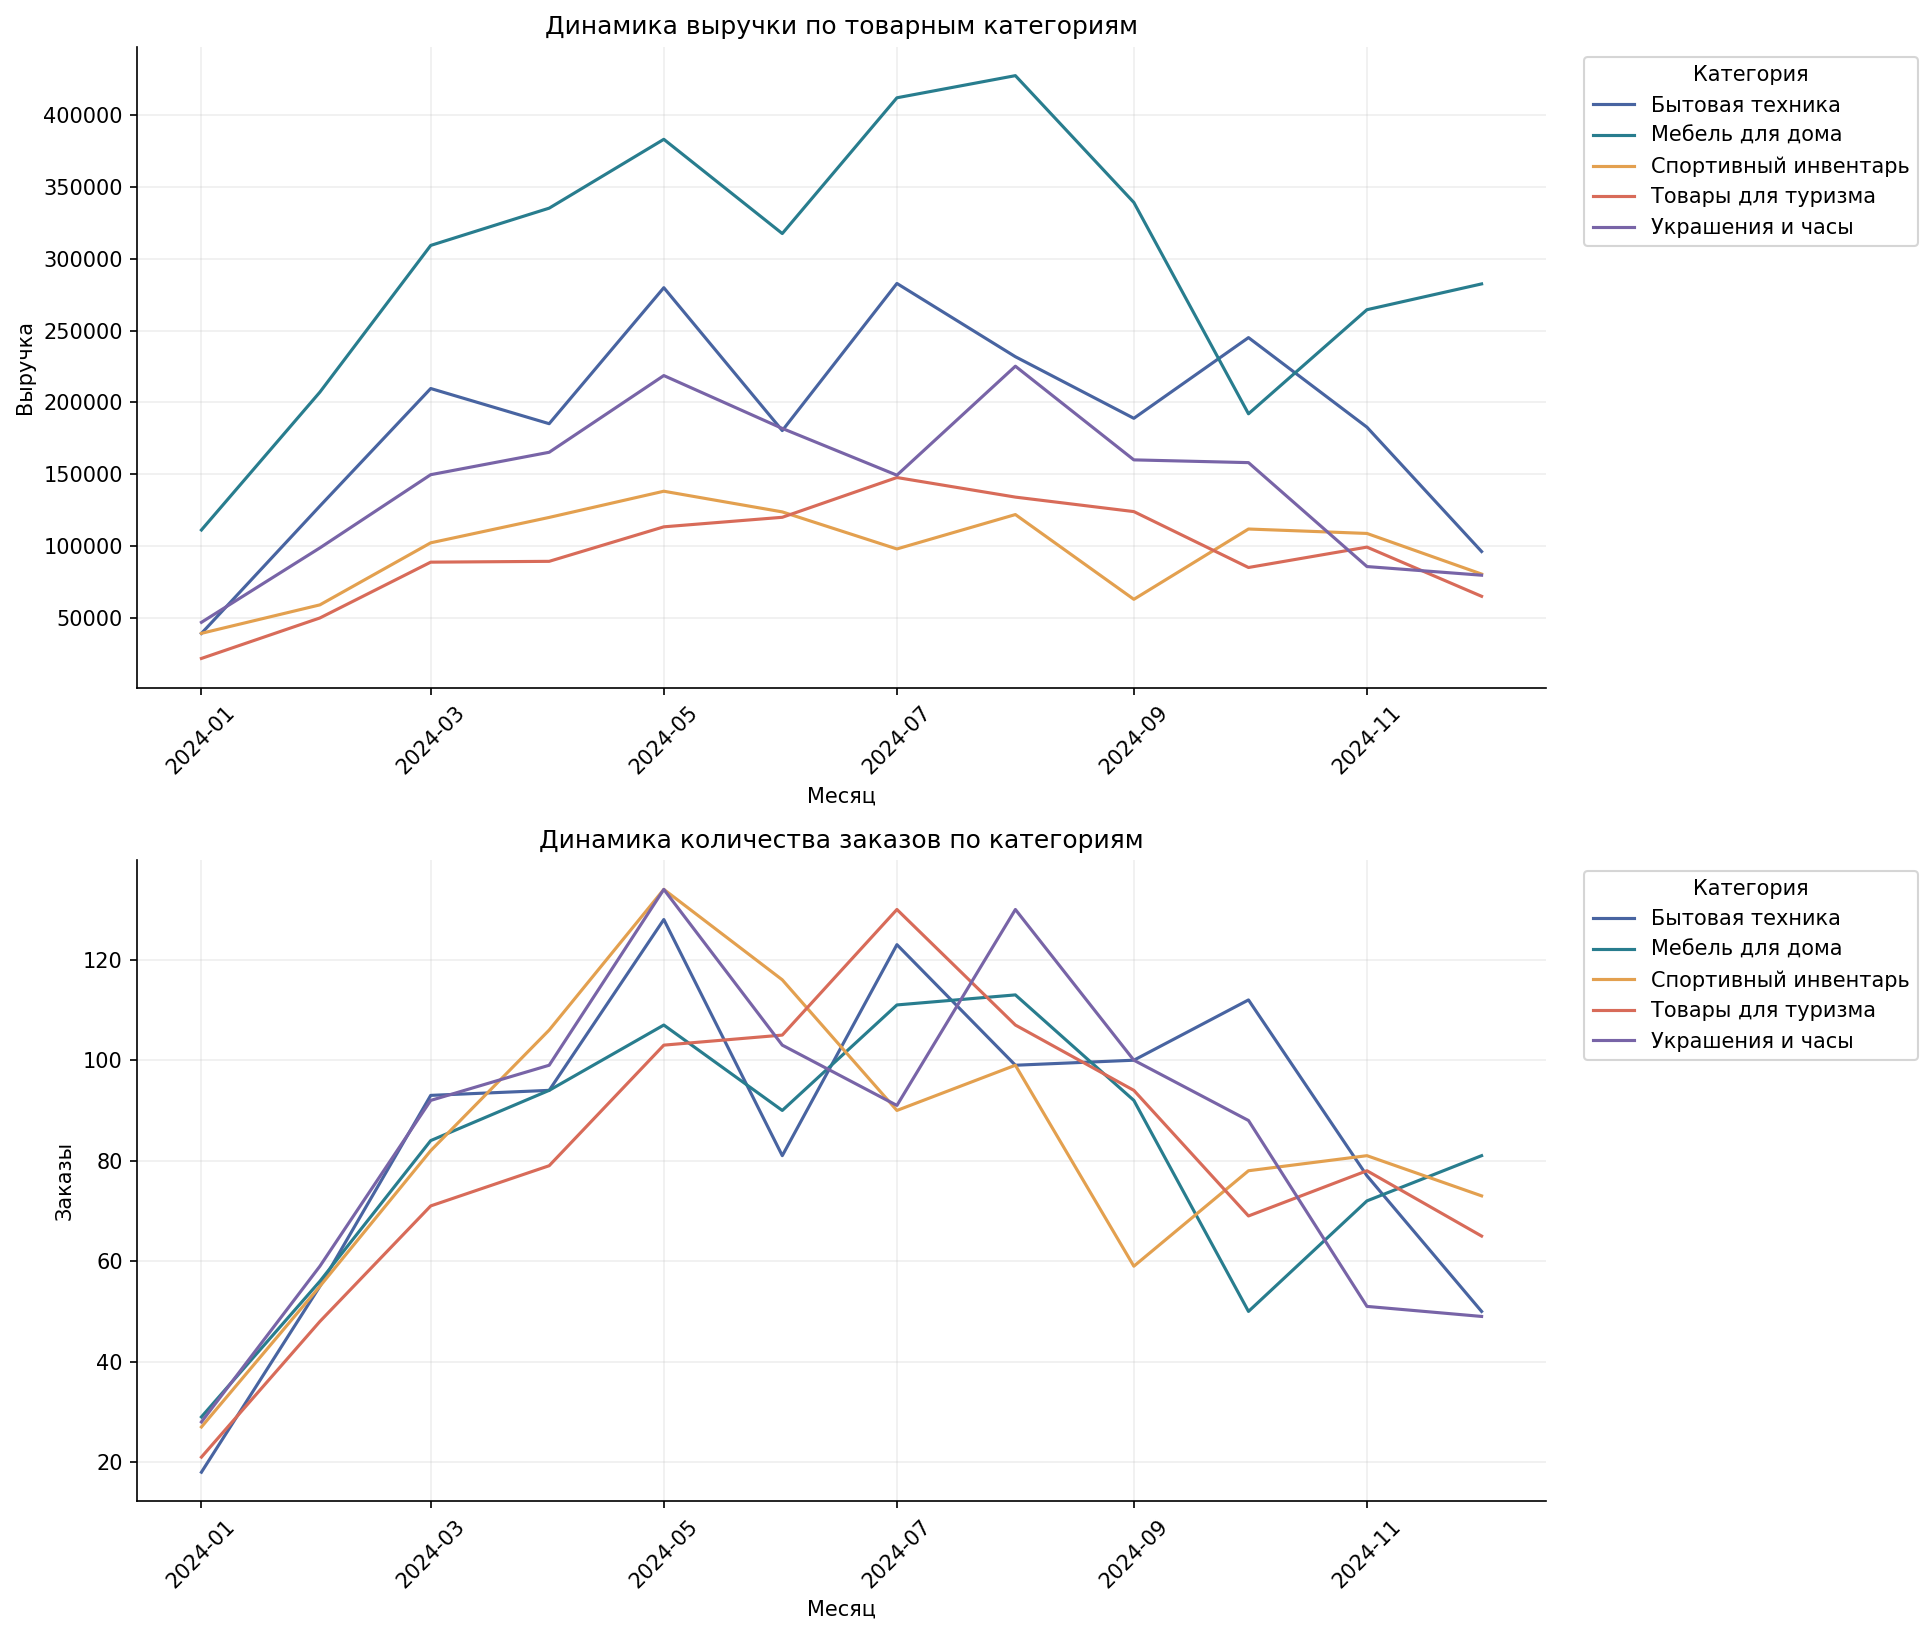

In [45]:
fig, axes = plt.subplots(2, 1, figsize=(13, 11))

metrics = [
    ('revenue', 'Динамика выручки по товарным категориям', 'Выручка'),
    ('orders_count', 'Динамика количества заказов по категориям', 'Заказы')
]

category_colors = {
    category: palette[i]
    for i, category in enumerate(top_categories)
}

for ax, (metric, title, ylabel) in zip(axes, metrics):
    sns.lineplot(
        data=category_monthly_top,
        x='order_month',
        y=metric,
        hue='category_name',
        palette=category_colors,
        ax=ax
    )

    ax.set_title(title)
    ax.set_xlabel('Месяц')
    ax.set_ylabel(ylabel)
    ax.tick_params(axis='x', rotation=45)
    ax.grid(alpha=0.2)
    ax.legend(
        title='Категория',
        bbox_to_anchor=(1.02, 1),
        loc='upper left'
    )

plt.tight_layout()
plt.show()

Во второй половине 2024 года выручка и количество заказов снизились в большинстве крупнейших товарных категорий. Особенно заметное сокращение наблюдается в бытовой технике и украшениях, тогда как мебель для дома демонстрирует частичное восстановление к концу года. Сходная динамика выручки и заказов указывает на снижение покупательской активности как на один из основных факторов ухудшения продаж. При этом проблема не ограничивается отдельной категорией товаров.

**Расчёт изменения выручки по категориям**

In [46]:
category_monthly = (
    orders.groupby(['order_month', 'category_name'])
    .agg(
        revenue=('total_price', lambda x: x.sum() * 0.05),
        orders_count=('order_id', 'nunique')
    )
    .reset_index()
)

category_comparison = (
    category_monthly[
        category_monthly['order_month'].isin([
            '2024-05-01', '2024-12-01'
        ])
    ]
    .pivot(
        index='category_name',
        columns='order_month',
        values='revenue'
    )
    .fillna(0)
    .reset_index()
)

category_comparison.columns = [
    'category_name', 'revenue_may', 'revenue_dec'
]

category_comparison['revenue_change'] = (
    category_comparison['revenue_dec'] -
    category_comparison['revenue_may']
)

category_comparison['change_pct'] = (
    category_comparison['revenue_change'] /
    category_comparison['revenue_may'].replace(0, np.nan) * 100
)

category_comparison = category_comparison.sort_values(
    'revenue_change'
)

display(category_comparison.round(2))



,category_name,revenue_may,revenue_dec,revenue_change,change_pct
2,Бытовая техника,279817.01,96103.08,-183713.92,-65.66
24,Украшения и часы,218626.56,79616.68,-139009.88,-63.58
11,Мебель для дома,383140.19,282452.92,-100687.27,-26.28
8,Инструменты и садовый инвентарь,111704.34,44992.79,-66711.55,-59.72
0,Автотовары,124295.48,62439.42,-61856.06,-49.77
18,Спортивный инвентарь,138091.59,80405.02,-57686.57,-41.77
14,Обувь женская,100666.43,47804.50,-52861.93,-52.51
20,Сумки и аксессуары,101934.17,49242.84,-52691.33,-51.69
21,Товары для кухни,112783.06,60320.97,-52462.08,-46.52
23,Товары для туризма,113301.47,64928.49,-48372.98,-42.69


**Визуализация изменения выручки по категориям**

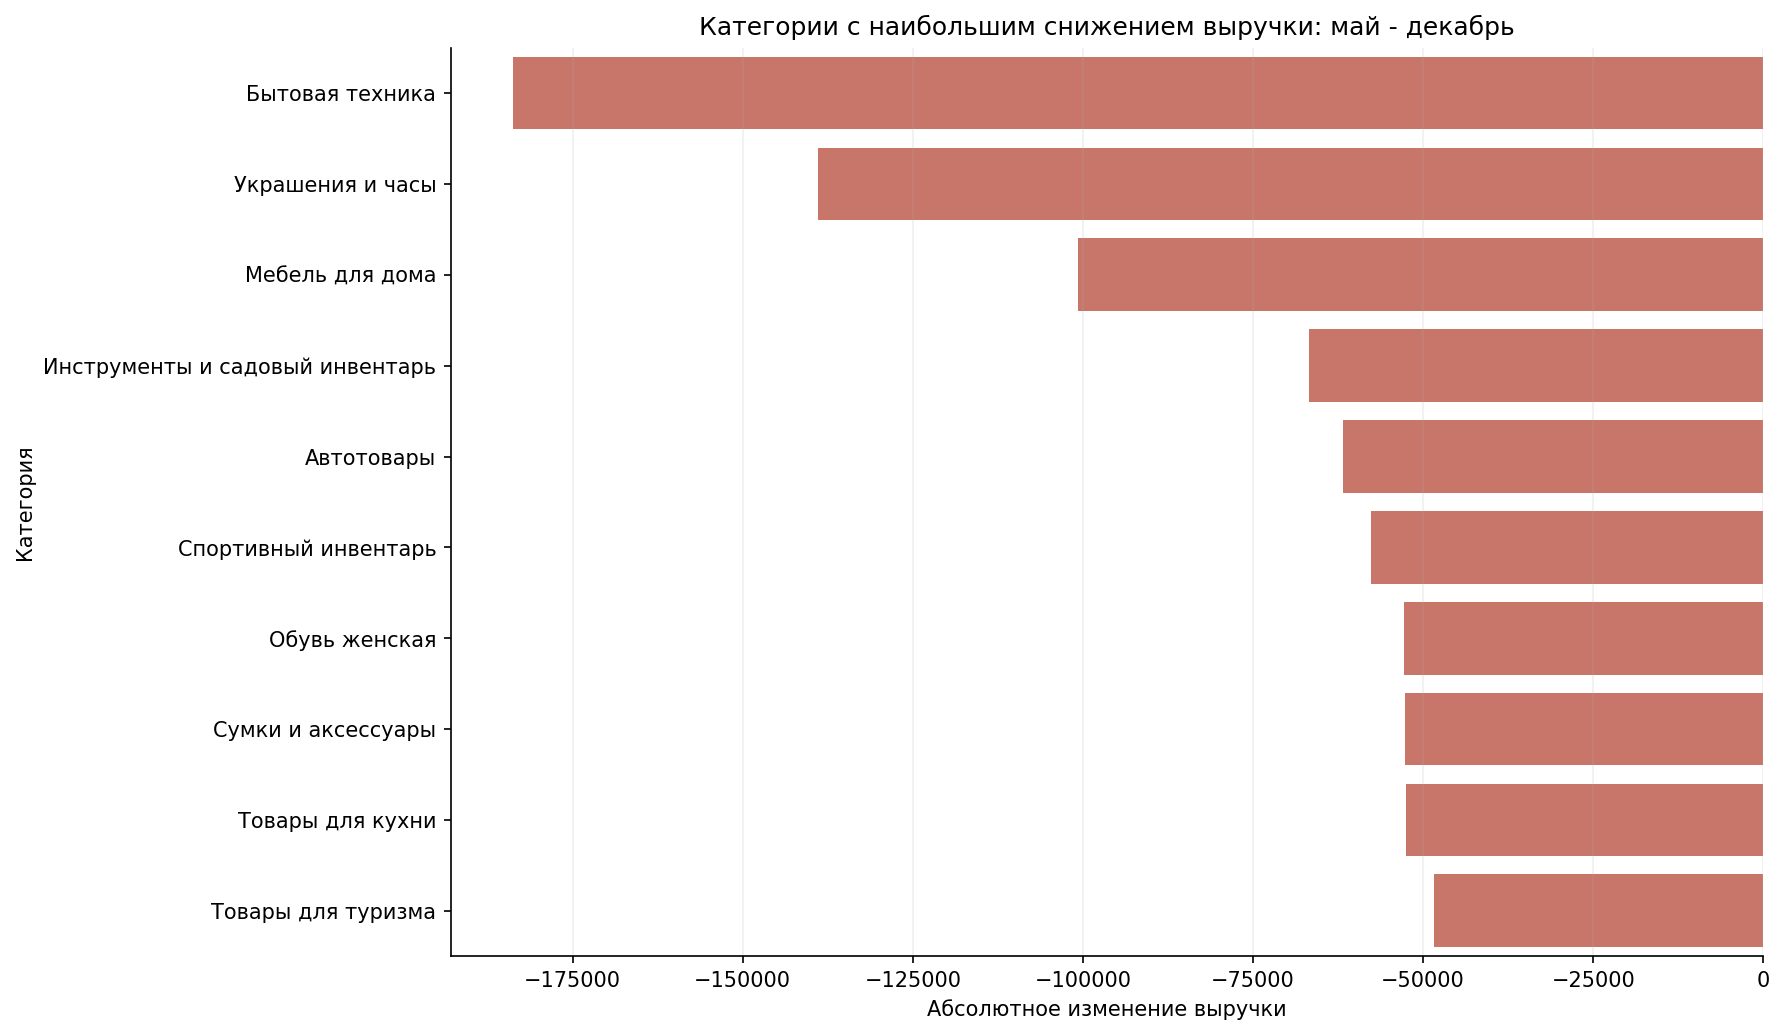

In [47]:
top_decline = category_comparison.nsmallest(
    10, 'revenue_change'
).sort_values('revenue_change')

plt.figure(figsize=(12, 7))

sns.barplot(
    data=top_decline,
    x='revenue_change',
    y='category_name',
    color=palette[4]
)

plt.title('Категории с наибольшим снижением выручки: май - декабрь')
plt.xlabel('Абсолютное изменение выручки')
plt.ylabel('Категория')
plt.grid(axis='x', alpha=0.2)

plt.tight_layout()
plt.show()

С мая по декабрь 2024 года выручка снизилась во всех 25 товарных категориях. Наибольший абсолютный вклад в сокращение внесли бытовая техника (-183,7 тыс.), украшения и часы (-139,0 тыс.) и мебель для дома (-100,7 тыс.). Совокупно на эти категории приходится около 37% общего снижения выручки. Падение продаж затрагивает как дорогостоящие товары, так и категории повседневного спроса. Это указывает на общий характер снижения покупательской активности и согласуется с ранее выявленным изменением структуры привлечения пользователей.

**Построение общей воронки**

In [48]:
import plotly.graph_objects as go

funnel_steps = [
    'page_view',
    'product_view',
    'add_to_cart',
    'checkout_start',
    'checkout_complete'
]

step_names = [
    'Просмотр страницы',
    'Просмотр товара',
    'Добавление в корзину',
    'Начало оформления',
    'Завершение оформления'
]

funnel = (
    events[events['event_type'].isin(funnel_steps)]
    .groupby('event_type')['user_id']
    .nunique()
    .reindex(funnel_steps, fill_value=0)
    .reset_index(name='users')
)

funnel['step_name'] = step_names

funnel['cr_initial'] = (
    funnel['users'] / funnel['users'].iloc[0] * 100
)

funnel['cr_previous'] = (
    funnel['users'] / funnel['users'].shift(1) * 100
)

funnel.loc[0, 'cr_previous'] = 100

display(funnel.round(2))

,event_type,users,step_name,cr_initial,cr_previous
0,page_view,22098,Просмотр страницы,100.00,100.00
1,product_view,22069,Просмотр товара,99.87,99.87
2,add_to_cart,20411,Добавление в корзину,92.37,92.49
3,checkout_start,16769,Начало оформления,75.88,82.16
4,checkout_complete,13897,Завершение оформления,62.89,82.87


In [49]:
fig = go.Figure(
    go.Funnel(
        y=funnel['step_name'],
        x=funnel['users'],
        textinfo='value+percent initial+percent previous',
        textposition='inside',
        marker=dict(
            color=palette[:5]
        ),
        connector=dict(
            line=dict(color='lightgray', width=1)
        )
    )
)

fig.update_layout(
    title='Общая воронка оформления заказа',
    width=1050,
    height=600,
    font=dict(size=13),
    paper_bgcolor='white',
    plot_bgcolor='white',
    margin=dict(l=180, r=100, t=80, b=50)
)

fig.show()

Общая воронка показывает, что до завершения оформления заказа доходят 62,89% пользователей, совершивших просмотр страницы.

Наибольшие потери наблюдаются между добавлением товара в корзину и началом оформления: 3642 пользователя (17,84%). Ещё 2872 пользователя (17,13%) не достигают завершения оформления после его начала.

Эти этапы представляют потенциальные точки роста конверсии и требуют дополнительного исследования.

**Воронки по покупательским сегментам**

In [50]:
segment_events = events.merge(
    users[['user_id', 'buyer_segment']],
    on='user_id',
    how='inner'
)

segment_funnel = (
    segment_events[
        segment_events['event_type'].isin(funnel_steps)
    ]
    .groupby(['buyer_segment', 'event_type'])['user_id']
    .nunique()
    .unstack(fill_value=0)
    .reindex(columns=funnel_steps)
)

display(segment_funnel)

event_type,page_view,product_view,add_to_cart,checkout_start,checkout_complete
buyer_segment,,,,,
medium,9353,9343,8720,7270,6091
one_time,1294,1291,1072,685,454
rare,5589,5575,4934,3608,2646
regular,5326,5324,5161,4730,4295


In [51]:
from plotly.subplots import make_subplots

segments = ['regular', 'medium', 'rare', 'one_time']

fig = make_subplots(
    rows=4,
    cols=1,
    subplot_titles=segments,
    specs=[[{'type': 'funnel'}] for _ in segments],
    vertical_spacing=0.06
)

for i, segment in enumerate(segments):
    fig.add_trace(
        go.Funnel(
            y=step_names,
            x=segment_funnel.loc[segment, funnel_steps].values,
            textinfo='value+percent initial+percent previous',
            textposition='inside',
            marker=dict(color=palette[:5]),
            showlegend=False
        ),
        row=i + 1,
        col=1
    )

fig.update_layout(
    title='Воронки оформления заказа по пользовательским сегментам',
    width=950,
    height=1200,
    font=dict(size=11),
    paper_bgcolor='white',
    margin=dict(l=170, r=60, t=90, b=40)
)

fig.show()

Анализ воронок выявил существенные различия между покупательскими сегментами. Наиболее высокая доля пользователей, достигших завершения оформления заказа, наблюдается у regular (81%), наиболее низкая - у one_time (35%).

Наибольшие потери во всех сегментах происходят на переходах от корзины к началу оформления и от начала к завершению оформления. Особенно выражены они у rare и one_time, где конверсия между соседними этапами составляет 64-73%.

Таким образом, поздние этапы оформления заказа представляют потенциальную точку роста, особенно для пользователей с низкой покупательской активностью.

**Месячные воронки**

In [52]:
monthly_segment_funnel = (
    segment_events[
        segment_events['event_type'].isin(funnel_steps)
    ]
    .groupby(['event_month', 'buyer_segment', 'event_type'])['user_id']
    .nunique()
    .unstack(fill_value=0)
    .reindex(columns=funnel_steps, fill_value=0)
)

monthly_segment_cr = (
    monthly_segment_funnel
    .div(monthly_segment_funnel.shift(axis=1), axis=0)
    * 100
)

monthly_segment_cr.iloc[:, 0] = 100

monthly_segment_cr = (
    monthly_segment_cr
    .reset_index()
    .melt(
        id_vars=['event_month', 'buyer_segment'],
        var_name='event_type',
        value_name='cr_previous'
    )
)

monthly_funnel = (
    events[events['event_type'].isin(funnel_steps)]
    .groupby(['event_month', 'event_type'])['user_id']
    .nunique()
    .unstack(fill_value=0)
    .reindex(columns=funnel_steps, fill_value=0)
)

monthly_cr = (
    monthly_funnel
    .div(monthly_funnel.shift(axis=1), axis=0)
    * 100
)

monthly_cr.iloc[:, 0] = 100

monthly_cr = (
    monthly_cr
    .reset_index()
    .melt(
        id_vars='event_month',
        var_name='event_type',
        value_name='cr_previous'
    )
)

display(monthly_segment_cr.round(2).head())
display(monthly_cr.round(2).head())

,event_month,buyer_segment,event_type,cr_previous
0,2024-01-01,medium,page_view,100.0
1,2024-01-01,one_time,page_view,100.0
2,2024-01-01,rare,page_view,100.0
3,2024-01-01,regular,page_view,100.0
4,2024-02-01,medium,page_view,100.0


,event_month,event_type,cr_previous
0,2024-01-01,page_view,100.0
1,2024-02-01,page_view,100.0
2,2024-03-01,page_view,100.0
3,2024-04-01,page_view,100.0
4,2024-05-01,page_view,100.0


**Общая динамика переходов**

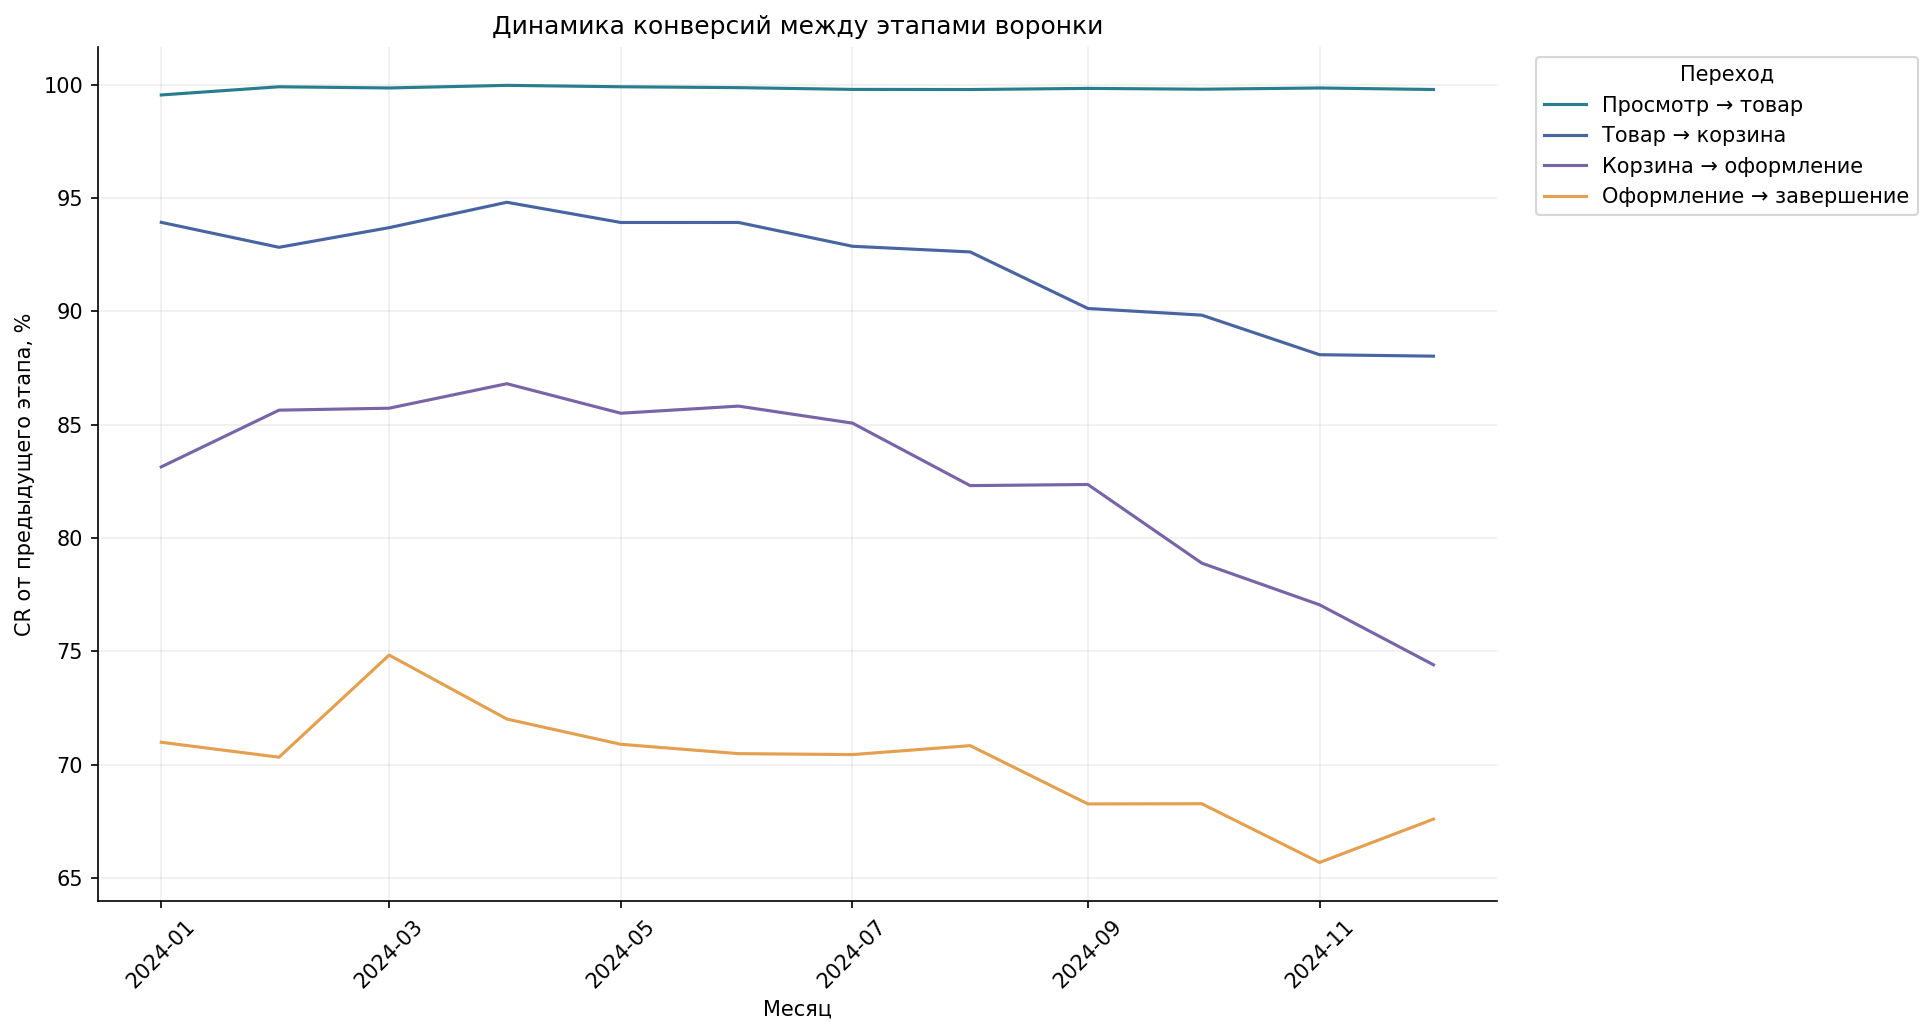

In [53]:
monthly_cr_plot = monthly_cr[
    monthly_cr['event_type'] != 'page_view'
].copy()

step_labels = {
    'product_view': 'Просмотр → товар',
    'add_to_cart': 'Товар → корзина',
    'checkout_start': 'Корзина → оформление',
    'checkout_complete': 'Оформление → завершение'
}

monthly_cr_plot['transition'] = (
    monthly_cr_plot['event_type'].map(step_labels)
)

fig, ax = plt.subplots(figsize=(13, 7))

sns.lineplot(
    data=monthly_cr_plot,
    x='event_month',
    y='cr_previous',
    hue='transition',
    palette=palette[:4],
    ax=ax
)

ax.set_title('Динамика конверсий между этапами воронки')
ax.set_xlabel('Месяц')
ax.set_ylabel('CR от предыдущего этапа, %')
ax.tick_params(axis='x', rotation=45)
ax.grid(alpha=0.2)
ax.legend(
    title='Переход',
    bbox_to_anchor=(1.02, 1),
    loc='upper left'
)

plt.tight_layout()
plt.show()

**Динамика переходов по сегментам**

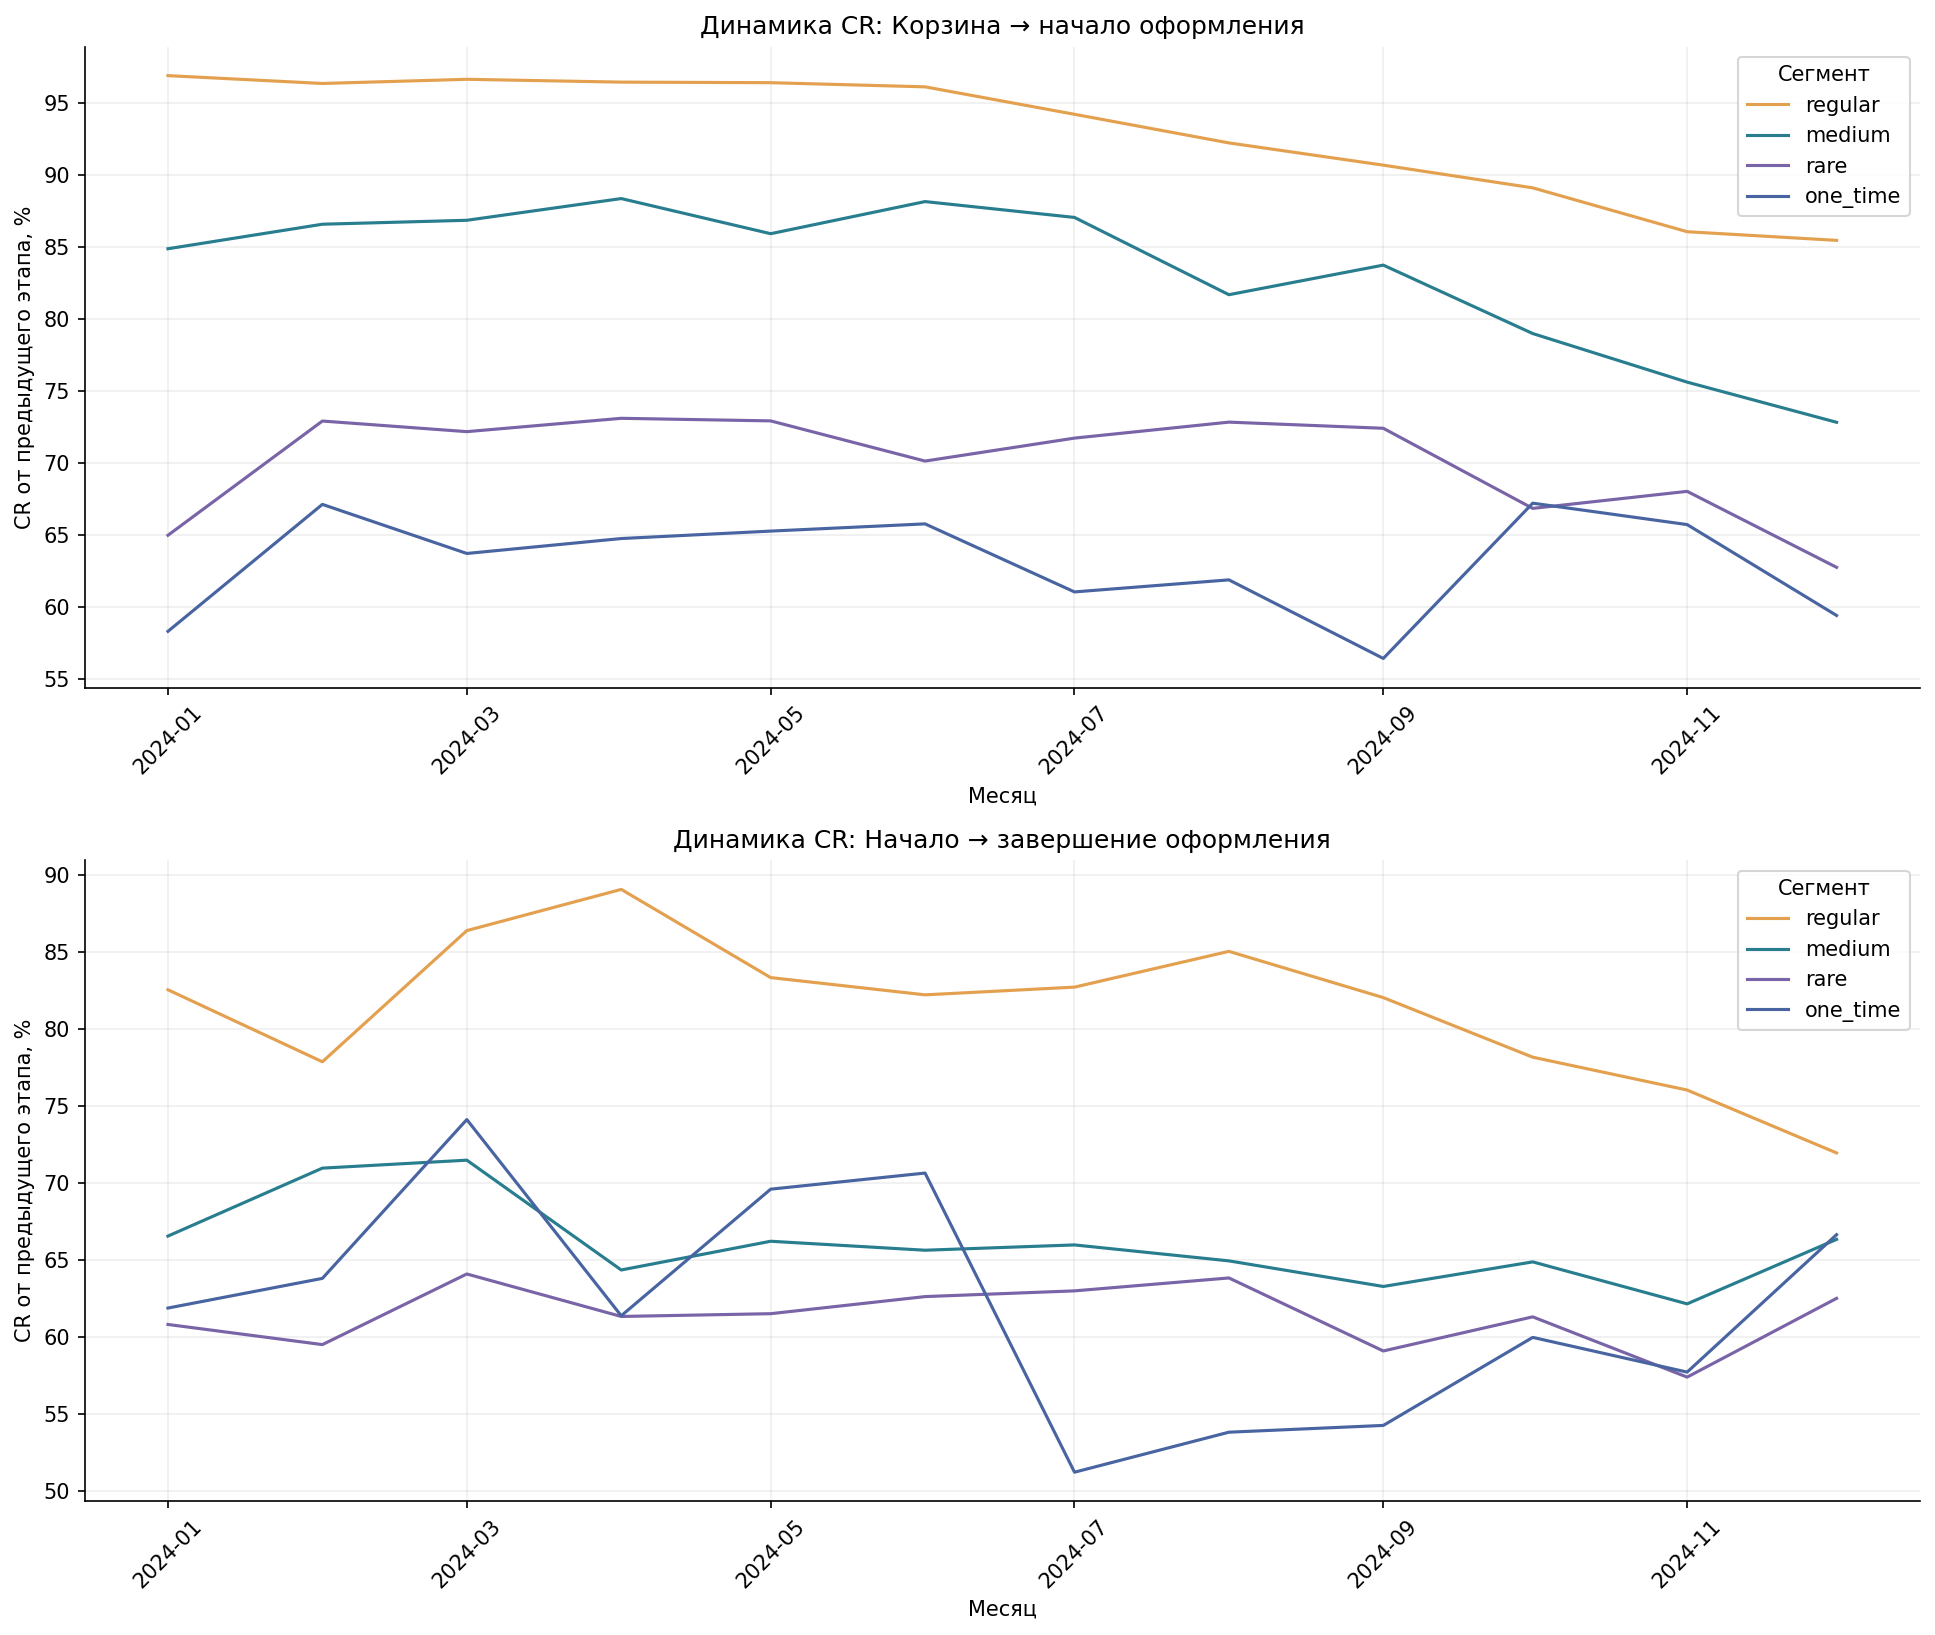

In [54]:
segment_cr_plot = monthly_segment_cr[
    monthly_segment_cr['event_type'].isin([
        'checkout_start',
        'checkout_complete'
    ])
].copy()

fig, axes = plt.subplots(2, 1, figsize=(13, 11))

transitions = [
    ('checkout_start', 'Корзина → начало оформления'),
    ('checkout_complete', 'Начало → завершение оформления')
]

segment_colors = {
    'regular': palette[3],
    'medium': palette[0],
    'rare': palette[2],
    'one_time': palette[1]
}

for ax, (event_type, title) in zip(axes, transitions):

    df_plot = segment_cr_plot[
        segment_cr_plot['event_type'] == event_type
    ]

    sns.lineplot(
        data=df_plot,
        x='event_month',
        y='cr_previous',
        hue='buyer_segment',
        hue_order=['regular', 'medium', 'rare', 'one_time'],
        palette=segment_colors,
        ax=ax
    )

    ax.set_title(f'Динамика CR: {title}')
    ax.set_xlabel('Месяц')
    ax.set_ylabel('CR от предыдущего этапа, %')
    ax.tick_params(axis='x', rotation=45)
    ax.grid(alpha=0.2)
    ax.legend(title='Сегмент')

plt.tight_layout()
plt.show()

Во второй половине 2024 года конверсия между этапами пользовательской воронки заметно снизилась. Наиболее существенное ухудшение наблюдается на переходе от добавления товара в корзину к началу оформления заказа. Конверсия завершения оформления также демонстрирует отрицательную динамику. Снижение затрагивает все покупательские сегменты, включая regular и medium, которые обеспечивают основную часть выручки. При этом переход от просмотра страницы к просмотру товара остаётся практически стабильным. Таким образом, помимо изменения структуры привлечения, выявлена дополнительная потенциальная проблема на поздних этапах пользовательского пути. Приоритетным направлением дальнейшего исследования является переход от корзины к оформлению заказа.

## Итоги сегментации и поиска точек роста



### Аналитическая записка: поиск инсайтов и точек роста маркетплейса


<details>
<summary>(нажмите, чтобы развернуть)</summary>

#### 1. Основные результаты

Анализ выявил две основные проблемы маркетплейса во второй половине 2024 года: изменение структуры привлечения пользователей и снижение конверсии на поздних этапах оформления заказа.

**Ключевые результаты:**

- Доля TikTok в новых регистрациях выросла с **13,20% в январе до 76,20% в декабре**. При этом канал демонстрировал стабильно отрицательный ROI.
- Декомпозиция общей конверсии показала, что её снижение с апреля по декабрь практически полностью объясняется изменением структуры активной аудитории между каналами.
- Наиболее значительное снижение выручки наблюдается в покупательском сегменте `regular`, который формирует основную часть доходов маркетплейса.
- Наибольшие потери в пользовательской воронке наблюдаются между добавлением товара в корзину и началом оформления. Конверсия этого перехода дополнительно снижалась во второй половине года.
- Выручка сократилась во всех 25 товарных категориях, а ухудшение пользовательской активности наблюдалось практически во всех регионах и на всех устройствах.

#### 2. Каналы привлечения

**Динамика привлечения и стоимости пользователя**

Во второй половине 2024 года структура привлечения существенно изменилась. Объём регистраций из TikTok резко увеличился, тогда как Google Ads постепенно сокращал привлечение и с ноября перестал приводить новых пользователей.

При этом CAC внутри каждого канала оставался относительно стабильным. Следовательно, изменение эффективности маркетинга связано преимущественно не с удорожанием отдельных источников, а с перераспределением объёма привлечения.

![Динамика привлечения и CAC по каналам](https://i.ibb.co/0HsHR2s/image.png)

**Конверсия и удержание**

Анализ помесячной динамики показал, что конверсия в покупку внутри большинства каналов оставалась относительно стабильной.

Наиболее высокую конверсию демонстрировал Affiliate, тогда как TikTok стабильно показывал минимальные значения. Удержание M1 у TikTok также оставалось самым низким.

![Динамика CR и Retention M1 по каналам](https://i.ibb.co/KcvCTH1q/image.png)

**Окупаемость каналов**

Наиболее высокую окупаемость за первые три календарных месяца жизни когорт показали:

- **Affiliate - ROI M2 = 227,94%.**
- **SEO - ROI M2 = 182,24%.**

Эти каналы сохраняли положительную окупаемость на протяжении всего исследованного периода.

Напротив, ROI TikTok оставался отрицательным во всех рассмотренных когортах - от -93,5% до -83,5%.

![Динамика ROI по каналам и когортам](https://i.ibb.co/XkZMfbhv/image.png)

**Изменение структуры привлечения**

Доля TikTok увеличилась с 13,20% в январе до 76,20% в декабре. Одновременно доля Google Ads сократилась с 37,49% до 0%, а Affiliate - с 19,26% до 9,19%.

![Структура привлечения по месяцам](https://i.ibb.co/LdSMH1Cr/image.png)

**Декомпозиция снижения конверсии**

Для количественной оценки влияния изменения структуры аудитории проведена декомпозиция общей конверсии в покупку за апрель-декабрь.

| Показатель | Значение |
|---|---:|
| CR в апреле | 34,08% |
| CR в декабре | 17,01% |
| Общее изменение | -17,07 п. п. |
| Вклад изменения структуры аудитории | -17,40 п. п. |
| Вклад изменения CR внутри каналов | +0,33 п. п. |

![Декомпозиция изменения конверсии](https://i.ibb.co/Gf4cf0Qq/image.png)

**Инсайт:** снижение общей конверсии практически полностью объясняется изменением структуры активной аудитории между каналами. Вклад изменений конверсии внутри самих каналов оказался незначительным.

Это подтверждает важность перераспределения привлечения в пользу TikTok как объяснения ухудшения общих продуктовых показателей.

**Ограничение:** данные не позволяют разделить платный и органический трафик TikTok. Поэтому CAC и ROI характеризуют канал в целом, а не только эффективность рекламных кампаний.

#### 3. Пользовательские сегменты

Анализ помесячной динамики показал снижение покупательской активности во всех сегментах.

Наиболее заметные изменения:

| Сегмент | CR в мае | CR в декабре | Изменение |
|---|---:|---:|---:|
| regular | 68,97% | 35,83% | -33,14 п. п. |
| medium | 25,78% | 12,67% | -13,11 п. п. |
| rare | 8,88% | 4,21% | -4,67 п. п. |
| one_time | 6,71% | 1,43% | -5,28 п. п. |

Сильнее всего снижение выручки затронуло `regular`: с 1,74 млн в мае до 864,5 тыс. в декабре.

ARPU этого сегмента также сократился с 1940,78 до 910,96, тогда как ARPPU оставался относительно стабильным.

![Динамика Revenue, CR, ARPU и ARPPU по сегментам](https://i.ibb.co/kVs4P3v7/image.png)

**Инсайт:** снижение выручки связано не только с ростом доли пользователей с низкой покупательской активностью, но и с ухудшением конверсии внутри самого доходного сегмента.

При этом сегменты могут определяться на основе покупательского поведения, поэтому различия между ними нельзя рассматривать как независимое объяснение причин покупок.

#### 4. Регионы

Анализ динамики Revenue, CR и ARPU показал, что снижение продуктовых показателей во второй половине года наблюдалось практически во всех регионах.

Конверсия преимущественно достигала высоких значений весной, после чего постепенно снижалась. Аналогичная динамика характерна для ARPU.

![Динамика выручки, CR и ARPU по регионам](https://i.ibb.co/QFZgQDj3/image.png)

**Инсайт:** ухудшение продуктовых показателей носит общерегиональный характер. Отдельные географические сегменты не выглядят основной причиной падения конверсии и монетизации.

#### 5. Устройства и операционные системы

Динамика активности на desktop, mobile и tablet оказалась схожей.

Количество активных пользователей росло до летнего периода, после чего начало сокращаться. Одновременно уменьшалось среднее число событий на пользователя.

Аналогичная тенденция наблюдалась на Android, iOS, Windows и macOS.

![Динамика активности по устройствам и ОС](https://i.ibb.co/pjSkNqDy/image.png)

**Инсайт:** снижение пользовательской активности затрагивает все основные платформы. Устойчиво отличающейся негативной динамики для отдельного устройства или ОС не обнаружено.

#### 6. Пользовательская воронка

**Общая воронка**

Анализ общей событийной воронки показал, что до завершения оформления заказа доходят **62,89% пользователей**, совершивших просмотр страницы.

Наиболее значительные потери происходят на последних этапах:

| Переход | CR от предыдущего шага |
|---|---:|
| Просмотр страницы → просмотр товара | 99,87% |
| Просмотр товара → корзина | 92,49% |
| Корзина → начало оформления | 82,16% |
| Начало → завершение оформления | 82,87% |

Наибольшие потери по числу пользователей наблюдаются между корзиной и началом оформления - 3642 пользователя.

![Общая воронка оформления заказа](https://i.ibb.co/ZRkRZbrK/image.png)

**Воронки по сегментам**

Сравнение сегментов показало существенные различия в прохождении воронки.

| Сегмент | CR от первого до последнего этапа |
|---|---:|
| regular | 81% |
| medium | 65% |
| rare | 47% |
| one_time | 35% |

Наибольшие потери наблюдаются у сегментов `rare` и `one_time`, особенно на поздних этапах оформления.

![Воронки по покупательским сегментам](https://i.ibb.co/prZDb7Tm/image.png)

**Динамика переходов**

Помесячный анализ выявил снижение конверсии между этапами воронки во второй половине года.

Наиболее выраженное ухудшение наблюдалось между добавлением товара в корзину и началом оформления заказа. Конверсия завершения оформления также снижалась.

![Динамика конверсий общей воронки](https://i.ibb.co/ycHK0zwp/image.png)

Снижение конверсии на поздних этапах наблюдалось внутри нескольких пользовательских сегментов, включая `regular` и `medium`.

![Динамика переходов по сегментам](https://i.ibb.co/204dRN75/image.png)

**Инсайт:** помимо изменения структуры привлечения, маркетплейс столкнулся с ухудшением прохождения поздних этапов пользовательского пути. Особенно важен переход от корзины к оформлению заказа.

**Ограничение:** воронки построены по уникальным пользователям без строгой проверки последовательности действий. Событие `checkout_complete` означает завершение оформления, но не гарантирует оплату.

#### 7. Товарные категории

**Структура продаж**

Основную выручку обеспечивают категории с высоким средним чеком:

- Мебель для дома - 16,28%.
- Бытовая техника - 10,22%.
- Украшения и часы - 7,81%.

Совокупно эти категории формируют около **34,3% выручки маркетплейса**.

Продукты питания лидируют по количеству заказов (4027), однако обеспечивают только 2,71% выручки.

**Динамика категорий**

Во второй половине года выручка и количество заказов снижались в большинстве крупнейших категорий.

Особенно заметное ухудшение наблюдалось в бытовой технике и украшениях, тогда как мебель для дома демонстрировала частичное восстановление к декабрю.

![Динамика выручки и заказов по категориям](https://i.ibb.co/rRc7XwHX/image.png)

Сравнение мая и декабря показало снижение выручки во всех 25 товарных категориях.

Наибольший абсолютный вклад внесли:

- Бытовая техника - -183,7 тыс. (-65,66%).
- Украшения и часы - -139,0 тыс. (-63,58%).
- Мебель для дома - -100,7 тыс. (-26,28%).

Совокупно эти категории обеспечили около 37% общего снижения выручки.

![Категории с наибольшим снижением выручки](https://i.ibb.co/6Jw0L8y2/image.png)

**Инсайт:** падение продаж затронуло практически весь ассортимент, поэтому проблема не ограничивается отдельными товарными направлениями. Снижение выручки в большинстве категорий сопровождается сокращением количества заказов.

#### 8. Гипотезы для развития продукта

**Гипотеза 1. Оптимизация структуры привлечения**

**Если перераспределить часть платного маркетингового бюджета в пользу Affiliate и SEO, то ROI новых когорт повысится.**

**Основание:** Affiliate и SEO демонстрировали положительный ROI на протяжении всего периода, тогда как TikTok стабильно имел отрицательную окупаемость. Декомпозиция также показала, что изменение структуры активной аудитории внесло основной вклад в снижение общей конверсии.

Перед экспериментом необходимо разделить платный и органический трафик TikTok и оценить возможности масштабирования эффективных каналов.

**Ключевая метрика:** ROI M2.

**Дополнительные метрики:** CAC, Retention M1, количество привлечённых пользователей.

**Гипотеза 2. Оптимизация перехода к оформлению заказа**

**Если упростить переход от корзины к оформлению заказа, то конверсия в начало оформления увеличится.**

**Основание:** переход `add_to_cart → checkout_start` характеризуется наибольшими потерями пользователей. Во второй половине года его конверсия дополнительно снижалась, в том числе внутри наиболее доходного сегмента `regular`.

Перед проверкой необходимо исследовать последовательность действий и возможные барьеры на этом этапе.

**Ключевая метрика:** конверсия из добавления в корзину в начало оформления.

**Барьерная метрика:** конверсия в оплаченный заказ.

**Гипотеза 3. Повышение активности покупателей**

**Если предлагать пользователям с редкими покупками персонализированные рекомендации на основе истории заказов, то частота повторных покупок увеличится.**

**Основание:** сегменты `medium`, `rare` и `one_time` демонстрируют более низкие показатели покупательской активности по сравнению с `regular`. Дополнительно во второй половине года конверсия снизилась во всех сегментах.

Для проверки необходимо выделить пользователей с низкой частотой покупок по поведению до начала эксперимента.

**Ключевая метрика:** доля пользователей с повторной покупкой.

**Дополнительные метрики:** количество заказов на покупателя, ARPU и AOV.

#### 9. Итоговые выводы и рекомендации

**Основная проблема маркетплейса - снижение эффективности монетизации пользователей на фоне изменения структуры привлечения.**

Декомпозиция показала, что падение общей конверсии с апреля по декабрь преимущественно объясняется перераспределением активной аудитории между каналами. Увеличилась доля TikTok, который отличается низкой покупательской конверсией и отрицательной окупаемостью.

Дополнительно выявлено ухудшение прохождения поздних этапов пользовательской воронки, особенно перехода от корзины к оформлению заказа. Снижение наблюдалось и внутри наиболее доходных покупательских сегментов.

При этом региональные и технические различия не объясняют общую отрицательную динамику, а снижение выручки во всех товарных категориях подтверждает широкий характер проблемы.

**Приоритетные рекомендации:**

1. Разделить платный и органический трафик TikTok и оценить эффективность рекламных кампаний.
2. Проверить возможности масштабирования Affiliate и SEO с учётом ROI и удержания.
3. Исследовать причины снижения конверсии между корзиной и началом оформления заказа.
4. Протестировать механики стимулирования повторных покупок.

Предложенные гипотезы требуют дальнейшей проверки. Обнаруженные закономерности помогают определить приоритетные направления развития, но сами по себе не доказывают причинно-следственные связи.

</details>


## 5. Анализ A/B-теста


# Дизайн эксперимента: Бонус на первую покупку для пользователей TikTok
## 1. Контекст и цель эксперимента
- **Бизнес-контекст:** Команда продукта запускает эксперимент, направленный на повышение конверсии среди пользователей, привлечённых через канал TikTok. Для стимулирования первой покупки пользователям будет предоставлен бонус на первую покупку.
- **Цель:** Проверить, влияет ли предоставление бонуса на первую покупку на конверсию и выручку среди пользователей TikTok.
- **Гипотеза:** Предоставление бонуса на первую покупку новым пользователям, привлеченным через TikTok, приведет к увеличению конверсии в первую покупку
---
## 2. Формат эксперимента
- **Тип эксперимента:** Сплит-роллинг (rolling split)
- **Канал:** Только пользователи, пришедшие с TikTok
- **Группы:**
    - **Контрольная (A):** пользователи TikTok без бонуса
    - **Тестовая (B):** пользователи TikTok с бонусом на первую покупку
- **Распределение:** Равномерное распределение новых пользователей TikTok между группами по дате регистрации
- **Период проведения:** 3 недели (фиксировано)
---
## 3. Ключевые метрики
### Основная метрика
- **Конверсия в первую покупку** — доля пользователей, зарегистрировавшихся с TikTok и совершивших первую покупку
- *Цель:* увеличить конверсию с помощью бонуса
- *Критерий успеха:* статистически значимый рост конверсии в тестовой группе
### Вспомогательные метрики
- **ARPU** (средняя выручка на пользователя TikTok)
- **ARPPU** (средняя выручка на покупателя TikTok)
- **AOV** (средний чек TikTok)
### Барьерная метрика
- **Общая выручка от пользователей TikTok**
---
## 4. Размеры групп и запуск
- **Целевая аудитория:** только пользователи TikTok
- **Размеры групп:** определяются по фактическому трафику TikTok за период эксперимента
- **Комментарий:** запуск без предварительного расчёта мощности и MDE из-за срочности задачи


**Загрузка данных**

In [55]:
events_ab = pd.read_csv('https://code.s3.yandex.net/datasets/pa_marketplace_events_AB.csv', parse_dates=['event_date'])
orders_ab = pd.read_csv('https://code.s3.yandex.net/datasets/pa_marketplace_orders_AB.csv', parse_dates=['order_date'])
users_ab = pd.read_csv('https://code.s3.yandex.net/datasets/pa_marketplace_users_AB.csv', parse_dates=['registration_date'])
split_ab = pd.read_csv('https://code.s3.yandex.net/datasets/pa_marketplace_AB_split_users.csv')

**Информация о данных**

In [56]:
ab_datasets = {
    'Users AB': users_ab,
    'Events AB': events_ab,
    'Orders AB': orders_ab,
    'Split AB': split_ab
}

for name, df in ab_datasets.items():
    print(f'\n{"=" * 50}')
    print(f'{name}: {df.shape[0]} строк, {df.shape[1]} столбцов')
    print(f'{"=" * 50}')

    display(df.head())

    print('\nТипы данных:')
    df.info()

    print('\nПропуски:')
    display(df.isna().sum())

    print(f'\nПолных дубликатов: {df.duplicated().sum()}')


Users AB: 22196 строк, 9 столбцов


,user_id,registration_date,age,gender,region,acq_channel,buyer_segment,cohort_week,cohort_month
0,18,2024-01-01 05:26:00,49,M,Екатеринбург,TikTok,one_time,2024-01-01,2024-01-01
1,22,2024-01-01 17:13:00,50,M,Санкт-Петербург,TikTok,one_time,2024-01-01,2024-01-01
2,26,2024-01-01 21:15:00,60,F,Москва,TikTok,rare,2024-01-01,2024-01-01
3,33,2024-01-01 14:43:00,31,M,Екатеринбург,TikTok,rare,2024-01-01,2024-01-01
4,39,2024-01-01 01:13:00,44,M,Санкт-Петербург,TikTok,rare,2024-01-01,2024-01-01



Типы данных:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 22196 entries, 0 to 22195
Data columns (total 9 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   user_id            22196 non-null  int64         
 1   registration_date  22196 non-null  datetime64[ns]
 2   age                22196 non-null  int64         
 3   gender             22196 non-null  object        
 4   region             22196 non-null  object        
 5   acq_channel        22196 non-null  object        
 6   buyer_segment      22196 non-null  object        
 7   cohort_week        22196 non-null  object        
 8   cohort_month       22196 non-null  object        
dtypes: datetime64[ns](1), int64(2), object(6)
memory usage: 1.5+ MB

Пропуски:


user_id              0
registration_date    0
age                  0
gender               0
region               0
acq_channel          0
buyer_segment        0
cohort_week          0
cohort_month         0
dtype: int64


Полных дубликатов: 0

Events AB: 831231 строк, 9 столбцов


,event_id,user_id,event_date,event_type,os,device,product_name,event_week,event_month
0,3132,100,2024-01-01 15:23:56,page_view,iOS,mobile,NaN,2024-01-01,2024-01-01
1,3133,100,2024-01-01 15:24:01,product_view,iOS,mobile,Шорты для тренировок,2024-01-01,2024-01-01
2,3134,100,2024-01-01 15:24:10,product_click,iOS,mobile,Куртка детская,2024-01-01,2024-01-01
3,3135,100,2024-01-01 15:25:10,add_to_cart,iOS,mobile,Балетки классические,2024-01-01,2024-01-01
4,3136,100,2024-01-01 15:25:46,checkout_start,iOS,mobile,NaN,2024-01-01,2024-01-01


... (7 outputs left out)

,user_id,group
0,44965,control
1,44967,control
2,44968,control
3,44969,treatment
4,44970,control



Типы данных:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2968 entries, 0 to 2967
Data columns (total 2 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   user_id  2968 non-null   int64 
 1   group    2968 non-null   object
dtypes: int64(1), object(1)
memory usage: 46.5+ KB

Пропуски:


user_id    0
group      0
dtype: int64


Полных дубликатов: 0


In [57]:
for col in ['cohort_week', 'cohort_month']:
    users_ab[col] = pd.to_datetime(users_ab[col])

for col in ['event_week', 'event_month']:
    events_ab[col] = pd.to_datetime(events_ab[col])

for col in ['order_week', 'order_month']:
    orders_ab[col] = pd.to_datetime(orders_ab[col])

print('Количество записей по группам:')
display(split_ab['group'].value_counts())

print('\nУникальных участников:', split_ab['user_id'].nunique())

group_check = (
    split_ab.groupby('user_id')['group']
    .nunique()
)

print(
    'Пользователей в нескольких группах:',
    (group_check > 1).sum()
)

print('\nПовторяющихся user_id в сплите:')
print(split_ab['user_id'].duplicated().sum())

ab_participants = split_ab.merge(
    users_ab,
    on='user_id',
    how='left',
    validate='many_to_one'
)

print('\nКаналы привлечения участников:')
display(ab_participants['acq_channel'].value_counts(dropna=False))

print('\nПериод регистрации участников:')
print(
    ab_participants['registration_date'].min(),
    '-',
    ab_participants['registration_date'].max()
)

print('\nПользователи сплита без данных в Users AB:')
print(ab_participants['registration_date'].isna().sum())

ab_participants['registration_day'] = (
    ab_participants['registration_date'].dt.normalize()
)

daily_split = (
    ab_participants.groupby(['registration_day', 'group'])['user_id']
    .nunique()
    .unstack(fill_value=0)
)

display(daily_split)

Количество записей по группам:


control      1503
treatment    1465
Name: group, dtype: int64


Уникальных участников: 2968
Пользователей в нескольких группах: 0

Повторяющихся user_id в сплите:
0

Каналы привлечения участников:


TikTok    2968
Name: acq_channel, dtype: int64


Период регистрации участников:
2025-01-01 00:05:00 - 2025-01-26 23:41:00

Пользователи сплита без данных в Users AB:
0


group,control,treatment
registration_day,,
2025-01-01,54,61
2025-01-02,59,66
2025-01-03,69,69
2025-01-04,66,81
2025-01-05,68,65
2025-01-06,65,69
2025-01-07,70,67
2025-01-08,71,60
2025-01-09,37,54


**Проверка SRM**

In [58]:
from scipy.stats import chisquare, chi2_contingency

group_counts = (
    split_ab['group']
    .value_counts()
    .reindex(['control', 'treatment'], fill_value=0)
)

chi2_srm, p_srm = chisquare(
    f_obs=group_counts.values,
    f_exp=[group_counts.sum() / 2] * 2
)

print('Проверка SRM')
print(f'χ² = {chi2_srm:.4f}')
print(f'p-value = {p_srm:.4f}')

if p_srm < 0.05:
    print('Обнаружено статистически значимое отклонение от 50/50')
else:
    print('Статистически значимого отклонения от 50/50 нет')

chi2_daily, p_daily, dof, expected = chi2_contingency(
    daily_split[['control', 'treatment']]
)

print('\nБаланс групп по датам регистрации')
print(f'χ² = {chi2_daily:.4f}')
print(f'p-value = {p_daily:.4f}')

if p_daily < 0.05:
    print('Распределение групп зависит от даты регистрации')
else:
    print('Статистически значимой зависимости от даты не обнаружено')

print('\nПериоды данных:')
print(
    'Регистрации:',
    ab_participants['registration_date'].min(),
    '-',
    ab_participants['registration_date'].max()
)
print(
    'События:',
    events_ab['event_date'].min(),
    '-',
    events_ab['event_date'].max()
)
print(
    'Заказы:',
    orders_ab['order_date'].min(),
    '-',
    orders_ab['order_date'].max()
)

Проверка SRM
χ² = 0.4865
p-value = 0.4855
Статистически значимого отклонения от 50/50 нет

Баланс групп по датам регистрации
χ² = 32.6451
p-value = 0.1402
Статистически значимой зависимости от даты не обнаружено

Периоды данных:
Регистрации: 2025-01-01 00:05:00 - 2025-01-26 23:41:00
События: 2024-01-01 15:23:56 - 2025-01-26 23:59:34
Заказы: 2024-01-01 08:03:45 - 2025-01-26 23:07:50


**Анализ первых покупок**

In [59]:
ab_orders = orders_ab.merge(
    ab_participants[['user_id', 'group', 'registration_date']],
    on='user_id',
    how='inner'
)

ab_orders = ab_orders[
    ab_orders['order_date'] >= ab_orders['registration_date']
].copy()

first_purchases = (
    ab_orders.groupby('user_id', as_index=False)
    .agg(first_purchase_date=('order_date', 'min'))
)

first_purchases = first_purchases.merge(
    ab_participants[['user_id', 'group', 'registration_date']],
    on='user_id',
    how='left'
)

first_purchases['days_to_purchase'] = (
    first_purchases['first_purchase_date']
    - first_purchases['registration_date']
).dt.total_seconds() / 86400

print('Участников с покупкой:', len(first_purchases))

print('\nВремя до первой покупки:')
display(
    first_purchases.groupby('group')['days_to_purchase']
    .describe(percentiles=[0.25, 0.5, 0.75, 0.9, 0.95])
    .round(2)
)

print('\nПокупатели по датам регистрации:')
display(
    first_purchases.groupby([
        first_purchases['registration_date'].dt.date,
        'group'
    ])['user_id']
    .nunique()
    .unstack(fill_value=0)
)

Участников с покупкой: 126

Время до первой покупки:


,count,mean,std,min,25%,50%,75%,90%,95%,max
group,,,,,,,,,,
control,16.0,7.99,7.77,0.13,3.00,4.13,12.32,19.61,22.23,23.91
treatment,110.0,7.09,5.19,0.00,2.74,6.85,10.49,14.61,16.56,20.32



Покупатели по датам регистрации:


group,control,treatment
registration_date,,
2025-01-01,2,9
2025-01-02,2,2
2025-01-03,3,6
2025-01-04,0,11
2025-01-05,1,8
2025-01-06,1,9
2025-01-07,0,6
2025-01-08,1,4
2025-01-09,0,4


In [60]:
data_end = orders_ab['order_date'].max()

eligible_ab = ab_participants[
    ab_participants['registration_date'] + pd.Timedelta(days=7) <= data_end
].copy()

purchases_7d = first_purchases[
    first_purchases['days_to_purchase'] <= 7
][['user_id']].drop_duplicates()

eligible_ab['purchased_7d'] = (
    eligible_ab['user_id'].isin(purchases_7d['user_id']).astype(int)
)

cr_7d = (
    eligible_ab.groupby('group')
    .agg(
        users=('user_id', 'nunique'),
        buyers=('purchased_7d', 'sum'),
        conversion=('purchased_7d', 'mean')
    )
    .reset_index()
)

cr_7d['conversion'] *= 100

display(cr_7d.round(2))

,group,users,buyers,conversion
0,control,1079,7,0.65
1,treatment,1118,52,4.65


**Проверка гипотезы о влиянии бонуса на первую покупку**

**Цель:** определить, влияет ли предоставление бонуса на конверсию в первую покупку среди пользователей TikTok.

**Нулевая гипотеза (H₀):** конверсия в первую покупку одинакова в контрольной и тестовой группах.

**Альтернативная гипотеза (H₁):** конверсия в первую покупку различается между контрольной и тестовой группами.

Для проверки используется двусторонний Z-тест для двух независимых пропорций.

Уровень статистической значимости: α = 0,05.

In [61]:
from statsmodels.stats.proportion import (
    proportions_ztest,
    confint_proportions_2indep
)

ab_participants['purchased'] = (
    ab_participants['user_id']
    .isin(first_purchases['user_id'])
    .astype(int)
)

cr_ab = (
    ab_participants.groupby('group')
    .agg(
        users=('user_id', 'nunique'),
        buyers=('purchased', 'sum'),
        conversion=('purchased', 'mean')
    )
)

display(cr_ab.round(4))

control = cr_ab.loc['control']
treatment = cr_ab.loc['treatment']

count = np.array([
    int(control['buyers']),
    int(treatment['buyers'])
])

nobs = np.array([
    int(control['users']),
    int(treatment['users'])
])

z_stat, p_value = proportions_ztest(
    count=count,
    nobs=nobs,
    alternative='two-sided'
)

ci_low, ci_high = confint_proportions_2indep(
    count1=int(treatment['buyers']),
    nobs1=int(treatment['users']),
    count2=int(control['buyers']),
    nobs2=int(control['users']),
    compare='diff',
    method='newcomb',
    alpha=0.05
)

cr_control = control['conversion']
cr_treatment = treatment['conversion']

absolute_lift = (cr_treatment - cr_control) * 100
relative_lift = (cr_treatment / cr_control - 1) * 100

print(f'CR control: {cr_control:.2%}')
print(f'CR treatment: {cr_treatment:.2%}')
print(f'Абсолютный прирост: {absolute_lift:.2f} п. п.')
print(f'Относительный прирост: {relative_lift:.2f}%')
print(f'Z-статистика: {z_stat:.4f}')
print(f'p-value: {p_value:.6g}')
print(f'95% ДИ разницы: [{ci_low * 100:.2f}; {ci_high * 100:.2f}] п. п.')

if p_value < 0.05:
    print('Нулевая гипотеза отвергается')
else:
    print('Нет оснований отвергнуть нулевую гипотезу')

,users,buyers,conversion
group,,,
control,1503,16,0.0106
treatment,1465,110,0.0751


CR control: 1.06%
CR treatment: 7.51%
Абсолютный прирост: 6.44 п. п.
Относительный прирост: 605.33%
Z-статистика: -8.7054
p-value: 3.16491e-18
95% ДИ разницы: [5.04; 7.96] п. п.
Нулевая гипотеза отвергается


**Анализ финансовых метрик**

In [62]:
ab_orders = orders_ab.merge(
    ab_participants[['user_id', 'group', 'registration_date']],
    on='user_id',
    how='inner'
)

ab_orders = ab_orders[
    ab_orders['order_date'] >= ab_orders['registration_date']
].copy()

ab_orders['revenue'] = ab_orders['total_price'] * 0.05

ab_checkouts = (
    ab_orders.groupby(
        ['user_id', 'group', 'order_date'],
        as_index=False
    )
    .agg(
        order_value=('total_price', 'sum'),
        revenue=('revenue', 'sum')
    )
)

financial_ab = (
    ab_checkouts.groupby('group')
    .agg(
        buyers=('user_id', 'nunique'),
        orders=('order_date', 'size'),
        revenue=('revenue', 'sum'),
        gmv=('order_value', 'sum')
    )
)

financial_ab['users'] = (
    ab_participants.groupby('group')['user_id'].nunique()
)

financial_ab['ARPU'] = (
    financial_ab['revenue'] / financial_ab['users']
)

financial_ab['ARPPU'] = (
    financial_ab['revenue'] / financial_ab['buyers']
)

financial_ab['AOV'] = (
    financial_ab['gmv'] / financial_ab['orders']
)

display(
    financial_ab[
        ['users', 'buyers', 'orders', 'revenue', 'ARPU', 'ARPPU', 'AOV']
    ].round(2)
)

,users,buyers,orders,revenue,ARPU,ARPPU,AOV
group,,,,,,,
control,1503,16,18,18918.64,12.59,1182.42,21020.72
treatment,1465,110,118,192279.85,131.25,1748.00,32589.81


В тестовой группе наблюдается увеличение всех финансовых показателей. ARPU вырос с 12,59 до 131,25, ARPPU - с 1182,42 до 1748,00, AOV - с 21020,72 до 32589,81. Общая выручка тестовой группы составила 192,3 тысяч против 18,9 тысяч в контрольной группе. Результаты указывают на положительную динамику монетизации при предоставлении бонуса. 

**Проверка гипотезы о влиянии бонуса на ARPU**

**H₀:** средняя выручка на пользователя одинакова в контрольной и тестовой группах.

**H₁:** средняя выручка на пользователя различается между контрольной и тестовой группами.

Для проверки используется двусторонний t-тест Уэлча для независимых выборок.

Уровень значимости: α = 0,05.

In [63]:
from scipy.stats import ttest_ind

user_revenue = (
    ab_orders.groupby('user_id', as_index=False)
    .agg(revenue=('revenue', 'sum'))
)

arpu_users = (
    ab_participants[['user_id', 'group']]
    .merge(user_revenue, on='user_id', how='left')
)

arpu_users['revenue'] = arpu_users['revenue'].fillna(0)

control_arpu = arpu_users.loc[
    arpu_users['group'] == 'control', 'revenue'
]

treatment_arpu = arpu_users.loc[
    arpu_users['group'] == 'treatment', 'revenue'
]

t_stat, p_value_arpu = ttest_ind(
    control_arpu,
    treatment_arpu,
    equal_var=False
)

print(f'ARPU control: {control_arpu.mean():.2f}')
print(f'ARPU treatment: {treatment_arpu.mean():.2f}')
print(f'Абсолютная разница: {treatment_arpu.mean() - control_arpu.mean():.2f}')
print(f'Относительная разница: {(treatment_arpu.mean() / control_arpu.mean() - 1) * 100:.2f}%')
print(f't-статистика: {t_stat:.4f}')
print(f'p-value: {p_value_arpu:.6g}')

if p_value_arpu < 0.05:
    print('Нулевая гипотеза отвергается')
else:
    print('Нет оснований отвергнуть нулевую гипотезу')

ARPU control: 12.59
ARPU treatment: 131.25
Абсолютная разница: 118.66
Относительная разница: 942.71%
t-статистика: -5.9139
p-value: 4.09382e-09
Нулевая гипотеза отвергается


ARPU тестовой группы составил 131,25 против 12,59 в контрольной. Абсолютный прирост достиг 118,66 (+942,71%). По результатам теста Уэлча различие статистически значимо (p-value < 0,001). Таким образом, предоставление бонуса сопровождается значительным увеличением средней выручки на пользователя. Однако стоимость бонуса не учтена, поэтому рост ARPU пока не подтверждает экономическую эффективность нововведения.

**Проверка гипотез о влиянии бонуса на ARPPU и AOV**

Гипотеза 1. ARPPU

H₀: средняя выручка на покупателя одинакова в контрольной и тестовой группах.

H₁: средняя выручка на покупателя различается между группами.

Гипотеза 2. AOV

H₀: средняя стоимость оформления одинакова в контрольной и тестовой группах.

H₁: средняя стоимость оформления различается между группами.

Для проверки используется двусторонний тест Уэлча. Уровень значимости α = 0,05.

Результаты рассматриваются как дополнительные: бонус может влиять на сам факт покупки, а значит, состав покупателей в группах может различаться.

In [64]:
from scipy.stats import ttest_ind

buyer_revenue = (
    ab_orders.groupby(['user_id', 'group'], as_index=False)
    .agg(revenue=('revenue', 'sum'))
)

order_values = ab_checkouts[
    ['group', 'order_value']
].copy()

metrics_to_test = {
    'ARPPU': (buyer_revenue, 'revenue'),
    'AOV': (order_values, 'order_value')
}

for metric, (df, column) in metrics_to_test.items():

    control_values = df.loc[
        df['group'] == 'control', column
    ]

    treatment_values = df.loc[
        df['group'] == 'treatment', column
    ]

    t_stat, p_value = ttest_ind(
        control_values,
        treatment_values,
        equal_var=False
    )

    control_mean = control_values.mean()
    treatment_mean = treatment_values.mean()

    print(f'\n{metric}')
    print(f'Control: {control_mean:.2f}')
    print(f'Treatment: {treatment_mean:.2f}')
    print(f'Разница: {treatment_mean - control_mean:.2f}')
    print(
        f'Относительное изменение: '
        f'{(treatment_mean / control_mean - 1) * 100:.2f}%'
    )
    print(f't-статистика: {t_stat:.4f}')
    print(f'p-value: {p_value:.6g}')

    if p_value < 0.05:
        print('Нулевая гипотеза отвергается')
    else:
        print('Нет оснований отвергнуть нулевую гипотезу')


ARPPU
Control: 1182.42
Treatment: 1748.00
Разница: 565.58
Относительное изменение: 47.83%
t-статистика: -2.0060
p-value: 0.0492768
Нулевая гипотеза отвергается

AOV
Control: 21020.72
Treatment: 32589.81
Разница: 11569.09
Относительное изменение: 55.04%
t-статистика: -2.1915
p-value: 0.0322559
Нулевая гипотеза отвергается


ARPPU тестовой группы выше контрольной на 47,83%, AOV - на 55,04%. По результатам тестов Уэлча различия формально статистически значимы (p-value = 0,0493 и 0,0323 соответственно). Однако результаты дополнительных метрик следует интерпретировать осторожно из-за небольшого количества покупателей в контрольной группе, множественных проверок и возможной зависимости заказов одного пользователя. Основной результат эксперимента - статистически значимое увеличение конверсии в первую покупку - сохраняется.

**Проверка барьерной метрики: общая выручка**

In [65]:
revenue_guardrail = financial_ab[
    ['users', 'revenue', 'ARPU']
].copy()

control_revenue = revenue_guardrail.loc['control', 'revenue']
treatment_revenue = revenue_guardrail.loc['treatment', 'revenue']

control_arpu = revenue_guardrail.loc['control', 'ARPU']
treatment_arpu = revenue_guardrail.loc['treatment', 'ARPU']

revenue_diff = treatment_revenue - control_revenue
revenue_lift = (treatment_revenue / control_revenue - 1) * 100
arpu_diff = treatment_arpu - control_arpu

display(revenue_guardrail.round(2))

print(f'Разница общей выручки: {revenue_diff:,.2f}')
print(f'Изменение общей выручки: {revenue_lift:.2f}%')
print(f'Разница ARPU: {arpu_diff:.2f}')

if revenue_diff >= 0 and arpu_diff >= 0:
    print('Снижения наблюдаемой выручки не обнаружено')
else:
    print('Обнаружено ухудшение одного из показателей выручки')

,users,revenue,ARPU
group,,,
control,1503,18918.64,12.59
treatment,1465,192279.85,131.25


Разница общей выручки: 173,361.21
Изменение общей выручки: 916.35%
Разница ARPU: 118.66
Снижения наблюдаемой выручки не обнаружено


## Итоги A/B-теста


### Итоги A/B-теста: бонус на первую покупку для пользователей TikTok

#### 1. Основные результаты

Эксперимент показал статистически значимое увеличение конверсии в первую покупку среди пользователей TikTok при предоставлении бонуса.

| Метрика | Control | Treatment | Результат |
|---|---:|---:|---|
| CR в первую покупку | 1,06% | 7,51% | +6,44 п. п., p < 0,001 |
| ARPU | 12,59 | 131,25 | +942,71%, p < 0,001 |
| ARPPU | 1 182,42 | 1 748,00 | +47,83%, p = 0,0493 |
| AOV | 21 020,72 | 32 589,81 | +55,04%, p = 0,0323 |
| Общая выручка | 18,9 тыс. | 192,3 тыс. | +916,35% |

Основная гипотеза подтверждена: конверсия в первую покупку тестовой группы статистически значимо выше контрольной. Разница составляет 6,44 п. п. (95% ДИ: 5,04-7,96 п. п.).

Финансовые показатели также демонстрируют положительную динамику. При этом результаты дополнительных метрик ARPPU и AOV требуют осторожной интерпретации из-за небольшого количества покупателей в контрольной группе и особенностей статистических проверок.

#### 2. Проверка качества эксперимента

Распределение участников между группами близко к равномерному: 1503 пользователя в контрольной группе и 1465 - в тестовой.

Проверка SRM не выявила статистически значимого отклонения от соотношения 50/50 (p = 0,4855). Значимой зависимости распределения групп от даты регистрации также не обнаружено (p = 0,1402).

Все участники относятся к каналу TikTok. Дублирующихся пользователей и пересечений между группами не выявлено.

#### 3. Ограничения эксперимента

- **Продолжительность:** регистрации участников охватывают 26 дней вместо предусмотренных дизайном 21 дня. Причина отклонения неизвестна.
- **Время наблюдения:** пользователи регистрировались в разные даты, но данные заканчиваются 26 января. Поздние участники имели меньше времени для совершения покупки.
- **Мощность:** эксперимент проведён без предварительного расчёта необходимого размера выборки и MDE.
- **Стоимость бонуса:** в предоставленных данных отсутствуют сведения о размере и фактических затратах на стимулирование покупок.
- **Дополнительные метрики:** ARPPU и AOV рассчитаны по ограниченному числу покупателей и оформлений; их результаты менее устойчивы.

#### 4. Рекомендации

**Не рекомендуется немедленно распространять бонус на всю аудиторию TikTok**, несмотря на статистически значимое увеличение конверсии.

Перед масштабированием необходимо:

1. Уточнить причину расхождения фактического и запланированного периодов эксперимента.
2. Проверить устойчивость результата при сопоставимом времени наблюдения участников.
3. Рассчитать фактическую стоимость бонусов и оценить изменение чистого финансового результата.
4. При подтверждении экономической эффективности провести ограниченное расширение эксперимента с мониторингом конверсии, ARPU и затрат на бонусы.

#### 5. Общий вывод

Бонус на первую покупку показал положительный результат по основной продуктовой метрике и сопровождается существенным ростом наблюдаемой выручки.

Однако выявленные ограничения не позволяют пока сделать окончательный вывод об экономической целесообразности массового внедрения. Приоритетным следующим шагом является проверка затрат на бонусную программу и подтверждение устойчивости эффекта.